# Milestone 1 – Formula 1 Podium Prediction
## Audit, cleaning, data-engineering questions, features, models, experiments, XAI and inference

**Unit of analysis:** one driver entering one race, so `(raceId, driverId)` must be unique.
**Target:** podium = `positionOrder <= 3`.
**Prediction cutoff:** after qualifying, before race start.

**Rules followed in the whole notebook**
- Raw CSVs are **immutable**: loaded once into `raw`, never modified. All cleaning happens on copies in `clean`.
- Every cleaning step comes **after** the EDA that justifies it, and is followed by a check of its effect.
- Each team decision is labelled with its ID from our decision log (D1–D14). Decisions marked *TA* were confirmed with the TA.

**Team decisions applied here**

| ID | Decision | Section |
|---|---|---|
| D1 | pandas only; the SQL schema is used as the audit specification | 3, 5.3 |
| D2 | Shared drives: one driver per car, the one who **finished** it; the row keeps the car's starting grid (TA) | 5.9 |
| D3 | Drop non-starters (DNQ / DNPQ / withdrawn / did not start) from the modeling table | 5.8 |
| D4 | Separate grid 0 into pit-lane starts vs non-starters; recode pit-lane starts | 5.10 |
| D5 | Exclude the Indianapolis 500 (1950–1960) | 5.6 |
| D6 | Keep privateers | 5.11 |
| D7 | Use all seasons, 1950 onward, for the model too (TA); missing qualifying handled in the feature part | 5.12 |
| D8 | Sprint results excluded as features | 5.13 |
| D9 | Mechanical = a car component failed (brief note, guide, Piazza list); unclear statuses counted as not mechanical | 5.7 |
| D10 | Standings before a season opener: 0 points + `is_season_opener` flag (feature part) | 5.14 |
| D11 | Constructor renames: accept the reset (no merge); form features look back over the current and previous season only | 5.15 |
| D12 | Q1 era boundary: pre-2014 vs 2014+ only (applied in Q1) | — |
| D13 | Home-race mapping rules; drivers with no home Grand Prix left out of Q2 | 5.16 |
| — | Scope: every season in the attached dataset (TA) | 5.0 |
| D14 | Qualifying feature = % gap to the fastest Q1 time; best-of-Q1/Q2/Q3 tested and not better (13.4) | 5.17, 13.4 |

**Contents**
1. Setup
2. Load raw tables
3. Initial audit (incl. 3.4 Lab 1 inspection: info, describe, isnull, value_counts)
4. EDA before cleaning
5. Cleaning (on copies), incl. 5.18 impute-or-remove and 5.19 encoding plan (Lab 1, step 4)
6. EDA after cleaning: 6.1 before vs after, 6.2 Lab 1 visual exploration (distribution, comparison, relationship, composition)
7. Save cleaned tables
8. Summary of cleaning decisions
9. Data-engineering questions: 9.1 Q1 front-row conversion, 9.2 Q2 home advantage, 9.3 Q3 mechanical retirements
10. Feature engineering (features, leakage gate)
11. Train / validation / test split and its assessment
12. Feature evidence (training seasons only)
13. Modeling (metrics, preprocessing experiments, tuning, comparison on validation and test)
14. Experiments (feature-group ablation, split comparison, cleaning-decision experiments)
15. Model explainability (permutation importance, SHAP, LIME)
16. Inference function

## 1. Setup

In [140]:
import os
import glob
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import missingno as msno
except ImportError:          # Kaggle normally has it; otherwise: !pip install missingno
    msno = None

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

def is_text(series):
    '''True for text columns in both pandas 2 (object) and pandas 3 (str) dtypes.'''
    return pd.api.types.is_object_dtype(series) or pd.api.types.is_string_dtype(series)

print('pandas', pd.__version__)

pandas 2.3.3


## 2. Load raw tables

We read every CSV with `keep_default_na=False`, so pandas does **not** silently turn strings such as `"NA"` or `""` into NaN.
The raw audit therefore shows exactly what is in the files, including the `\N` sentinel.

In [141]:
# Kaggle: finds the folder containing circuits.csv. Elsewhere: set F1_DATA_DIR.
matches = glob.glob('/kaggle/input/**/circuits.csv', recursive=True)
DATA_DIR = os.environ.get('F1_DATA_DIR') or (os.path.dirname(matches[0]) if matches else '')
print('DATA_DIR =', DATA_DIR)
print(sorted(f for f in os.listdir(DATA_DIR) if f.endswith('.csv')))

DATA_DIR = /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020
['circuits.csv', 'constructor_results.csv', 'constructor_standings.csv', 'constructors.csv', 'driver_standings.csv', 'drivers.csv', 'lap_times.csv', 'pit_stops.csv', 'qualifying.csv', 'races.csv', 'results.csv', 'seasons.csv', 'sprint_results.csv', 'status.csv']


In [142]:
TABLES = [
    'circuits', 'constructors', 'constructor_results', 'constructor_standings',
    'drivers', 'driver_standings', 'races', 'results', 'qualifying',
    'lap_times', 'pit_stops', 'sprint_results', 'seasons', 'status',
]
SENTINEL = r'\N'

raw = {t: pd.read_csv(os.path.join(DATA_DIR, f'{t}.csv'), keep_default_na=False, na_values=[])
       for t in TABLES}

# raw is NEVER modified after this cell
pd.Series({t: df.shape for t, df in raw.items()}, name='shape').to_frame()

,shape
circuits,"(77, 9)"
constructors,"(212, 5)"
constructor_results,"(12625, 5)"
constructor_standings,"(13391, 7)"
drivers,"(861, 9)"
driver_standings,"(34863, 7)"
races,"(1125, 18)"
results,"(26759, 18)"
qualifying,"(10494, 9)"
lap_times,"(589081, 6)"


## 3. Initial audit
### 3.1 Table sizes

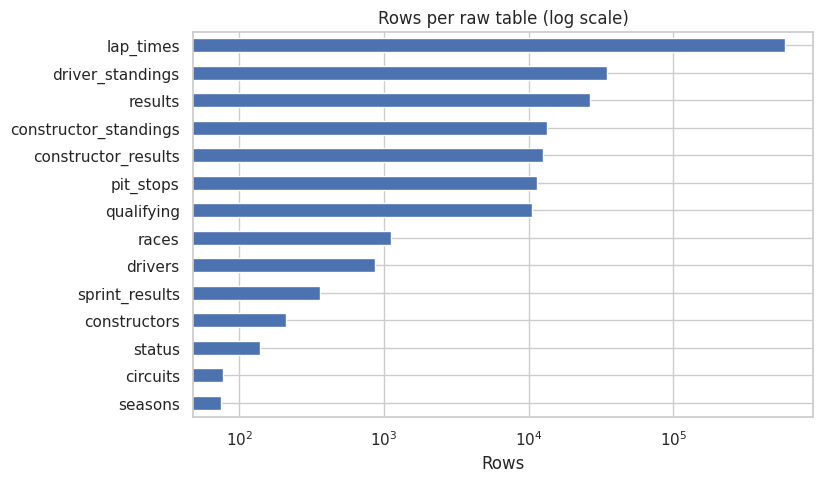

,rows,columns
lap_times,589081,6
driver_standings,34863,7
results,26759,18
constructor_standings,13391,7
constructor_results,12625,5
pit_stops,11371,7
qualifying,10494,9
races,1125,18
drivers,861,9
sprint_results,360,16


In [143]:
overview = pd.DataFrame({
    'rows':    {t: len(df) for t, df in raw.items()},
    'columns': {t: df.shape[1] for t, df in raw.items()},
}).sort_values('rows', ascending=False)

overview['rows'].plot(kind='barh', logx=True, figsize=(8, 5))
plt.title('Rows per raw table (log scale)')
plt.xlabel('Rows')
plt.gca().invert_yaxis()
plt.show()
overview

### 3.2 Columns vs our schema (D1)

Our `f1_schema.sql` is the audit specification. We first check its column lists against the real files, so the key checks in 5.3–5.4 test the right columns.

In [144]:
SCHEMA_COLUMNS = {
    'seasons':               ['year', 'url'],
    'circuits':              ['circuitId', 'circuitRef', 'name', 'location', 'country', 'lat', 'lng', 'alt', 'url'],
    'constructors':          ['constructorId', 'constructorRef', 'name', 'nationality', 'url'],
    'drivers':               ['driverId', 'driverRef', 'number', 'code', 'forename', 'surname', 'dob', 'nationality', 'url'],
    'status':                ['statusId', 'status'],
    'races':                 ['raceId', 'year', 'round', 'circuitId', 'name', 'date', 'time', 'url',
                              'fp1_date', 'fp1_time', 'fp2_date', 'fp2_time', 'fp3_date', 'fp3_time',
                              'quali_date', 'quali_time', 'sprint_date', 'sprint_time'],
    'results':               ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position',
                              'positionText', 'positionOrder', 'points', 'laps', 'time', 'milliseconds',
                              'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId'],
    'sprint_results':        ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position',
                              'positionText', 'positionOrder', 'points', 'laps', 'time', 'milliseconds',
                              'fastestLap', 'fastestLapTime', 'statusId'],
    'qualifying':            ['qualifyId', 'raceId', 'driverId', 'constructorId', 'number', 'position', 'q1', 'q2', 'q3'],
    'lap_times':             ['raceId', 'driverId', 'lap', 'position', 'time', 'milliseconds'],
    'pit_stops':             ['raceId', 'driverId', 'stop', 'lap', 'time', 'duration', 'milliseconds'],
    'driver_standings':      ['driverStandingsId', 'raceId', 'driverId', 'points', 'position', 'positionText', 'wins'],
    'constructor_standings': ['constructorStandingsId', 'raceId', 'constructorId', 'points', 'position', 'positionText', 'wins'],
    'constructor_results':   ['constructorResultsId', 'raceId', 'constructorId', 'points', 'status'],
}

schema_rows = []
for t, cols in SCHEMA_COLUMNS.items():
    real = set(raw[t].columns)
    schema_rows.append({'table': t,
                        'in_schema_not_csv': sorted(set(cols) - real),
                        'in_csv_not_schema': sorted(real - set(cols))})
schema_check = pd.DataFrame(schema_rows).set_index('table')
print('Tables with a column mismatch:',
      int((schema_check.map(len).sum(axis=1) > 0).sum()))
schema_check

Tables with a column mismatch: 0


,in_schema_not_csv,in_csv_not_schema
table,,
seasons,[],[]
circuits,[],[]
constructors,[],[]
drivers,[],[]
status,[],[]
races,[],[]
results,[],[]
sprint_results,[],[]
qualifying,[],[]


> **Interpretation:** any non-empty cell above means the schema must be corrected before the key checks. An all-empty table means the schema matches the files column for column.

### 3.3 Raw dtypes and first rows

In [145]:
raw_dtypes = pd.concat(
    {t: df.dtypes.astype(str) for t, df in raw.items()}, names=['table', 'column']
).rename('raw_dtype').to_frame()
text_cols = [(t, c) for t, df in raw.items() for c in df.columns if is_text(df[c])]
print('Columns read as text:', len(text_cols), 'of', len(raw_dtypes))
raw_dtypes.loc[text_cols]

Columns read as text: 57 of 120


raw_dtype
table                 column                   
circuits              circuitRef         object
                      name               object
                      location           object
                      country            object
                      url                object
constructors          constructorRef     object
                      name               object
                      nationality        object
                      url                object
constructor_results   status             object
constructor_standings positionText       object
drivers               driverRef          object
                      number             object
                      code               object
                      forename           object
                      surname            object
                      dob                object
                      nationality        object
                      url                object
driver_standings      positionText       object
races                 name               object
                      date               object
                      time               object
                      url                object
                      fp1_date           object
                      fp1_time           object
                      fp2_date           object
                      fp2_time           object
                      fp3_date           object
                      fp3_time           object
                      quali_date         object
                      quali_time         object
                      sprint_date        object
                      sprint_time        object
results               number             object
                      position           object
                      positionText       object
                      time               object
                      milliseconds       object
                      fastestLap         object
                      rank               object
                      fastestLapTime     object
                      fastestLapSpeed    object
qualifying            q1                 object
                      q2                 object
                      q3                 object
lap_times             time               object
pit_stops             time               object
                      duration           object
sprint_results        position           object
                      positionText       object
                      time               object
                      milliseconds       object
                      fastestLap         object
                      fastestLapTime     object
seasons               url                object
status                status             object

In [146]:
# A-priority tables only (describe() on lap_times' ~600k rows adds nothing for cleaning)
for t in ['races', 'results', 'qualifying', 'drivers', 'status']:
    print(t)
    display(raw[t].head(3))

races


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N


results


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1


qualifying


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079


drivers


,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,\N,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg


status


,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident


### 3.4 Inspect the data (Lab 1, step 3)

Following Lab 1, we inspect the main tables before touching them:
- **a. Structure** (`info()`): rows, columns, types, memory. *Numerical* columns are measurable quantities (grid, laps, points); *categorical* columns are labels (nationality, status, positionText).
- **b. Summary statistics** (`describe()`): ranges and possible outliers.
- **c. Missing values** (`isnull().sum()`).
- **d. Categorical features** (`value_counts()`): inconsistent spellings or rare categories.

Each check is in its own cell, as in the lab.

In [147]:
raw['results'].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26759 non-null  object 
 5   grid             26759 non-null  int64  
 6   position         26759 non-null  object 
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             26759 non-null  object 
 12  milliseconds     26759 non-null  object 
 13  fastestLap       26759 non-null  object 
 14  rank             26759 non-null  object 
 15  fastestLapTime   26759 non-null  object 
 16  fastestLapSpeed  26759 non-null  object 
 17  statusId    

In [148]:
raw['results'].describe()

,resultId,raceId,driverId,constructorId,grid,positionOrder,points,laps,statusId
count,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000
mean,13380.977391,551.687283,278.673530,50.180537,11.134796,12.794051,1.987632,46.301768,17.224971
std,7726.134642,313.265036,282.703039,61.551498,7.202860,7.665951,4.351209,29.496557,26.026104
min,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000
25%,6690.500000,300.000000,57.000000,6.000000,5.000000,6.000000,0.000000,23.000000,1.000000
50%,13380.000000,531.000000,172.000000,25.000000,11.000000,12.000000,0.000000,53.000000,10.000000
75%,20069.500000,811.000000,399.500000,63.000000,17.000000,18.000000,2.000000,66.000000,14.000000
max,26764.000000,1144.000000,862.000000,215.000000,34.000000,39.000000,50.000000,200.000000,141.000000


> `describe()` only summarises the columns pandas read as numbers. Columns such as `position`, `grid` or `milliseconds` are missing from it because the `\N` text forced pandas to read them as text.

In [149]:
raw['results'].isnull().sum()

resultId           0
raceId             0
driverId           0
constructorId      0
number             0
grid               0
position           0
positionText       0
positionOrder      0
points             0
laps               0
time               0
milliseconds       0
fastestLap         0
rank               0
fastestLapTime     0
fastestLapSpeed    0
statusId           0
dtype: int64

> **Every count is 0, but the data is not complete.** In Lab 1 (Titanic) missing values were real NaN, so `isnull()` found them. Here missing values are written as the text `\N`, which pandas does not recognise as missing. This is why Section 4.1 counts the sentinel explicitly, and why 5.1 converts it.

In [150]:
raw['results']['positionText'].value_counts().head(10)

positionText
R    8897
F    1368
3    1135
4    1135
2    1133
5    1131
1    1128
6    1124
7    1104
8    1076
Name: count, dtype: int64

In [151]:
raw['drivers']['nationality'].value_counts()

nationality
British              166
American             158
Italian               99
French                73
German                50
Brazilian             32
Argentine             24
Belgian               23
Swiss                 23
South African         23
Japanese              20
Australian            19
Dutch                 18
Austrian              15
Spanish               15
Canadian              14
Swedish               10
New Zealander         10
Finnish                9
Mexican                6
Danish                 5
Irish                  5
Uruguayan              4
Rhodesian              4
Monegasque             4
Portuguese             4
Russian                4
Venezuelan             3
Colombian              3
East German            3
Thai                   2
Indian                 2
Polish                 1
Hungarian              1
Malaysian              1
Czech                  1
American-Italian       1
Chilean                1
Liechtensteiner        1
Argentine-Ita

In [152]:
raw['circuits']['country'].value_counts()

country
USA              11
France            7
Spain             6
Italy             4
Portugal          4
UK                4
Germany           3
Belgium           3
Canada            3
Japan             3
Australia         2
Austria           2
Brazil            2
South Africa      2
Malaysia          1
Bahrain           1
Hungary           1
Turkey            1
Monaco            1
United States     1
China             1
Singapore         1
Argentina         1
Mexico            1
Korea             1
Netherlands       1
UAE               1
Sweden            1
Morocco           1
Switzerland       1
India             1
Russia            1
Azerbaijan        1
Saudi Arabia      1
Qatar             1
Name: count, dtype: int64

> Like the "Male / male / M" example in Lab 1, the same category appears under different spellings: `USA` vs `United States` in circuits. Nationalities also include rare and historical labels (`East German`, `Rhodesian`, `American-Italian`). Both are handled in 5.16.

## 4. EDA before cleaning

Goal: measure every problem **before** deciding how to fix it. Every decision in Section 5 points back to a number or plot here.

### 4.1 Sentinel (`\N`) and empty-string counts per column

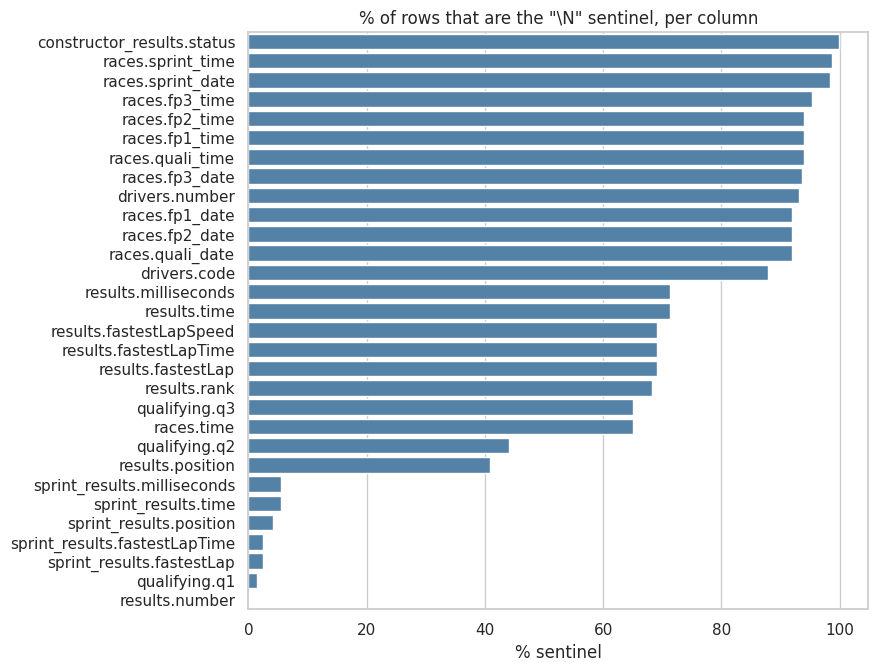

,table,column,n_sentinel,n_empty,pct_sentinel
0,constructor_results,status,12608,0,99.865347
13,races,sprint_time,1110,0,98.666667
12,races,sprint_date,1107,0,98.400000
9,races,fp3_time,1072,0,95.288889
7,races,fp2_time,1057,0,93.955556
5,races,fp1_time,1057,0,93.955556
11,races,quali_time,1057,0,93.955556
8,races,fp3_date,1053,0,93.600000
1,drivers,number,802,0,93.147503
4,races,fp1_date,1035,0,92.000000


In [153]:
rows = []
for t, df in raw.items():
    for col in df.columns:
        s = df[col].astype(str)
        n_sent = int((s == SENTINEL).sum())
        n_empty = int((s.str.strip() == '').sum())
        if n_sent or n_empty:
            rows.append({'table': t, 'column': col, 'n_sentinel': n_sent, 'n_empty': n_empty,
                         'pct_sentinel': 100 * n_sent / len(df)})
sentinel_df = pd.DataFrame(rows).sort_values('pct_sentinel', ascending=False)

plot_df = sentinel_df.assign(label=sentinel_df['table'] + '.' + sentinel_df['column'])
plt.figure(figsize=(8, max(4, 0.25 * len(plot_df))))
sns.barplot(data=plot_df, x='pct_sentinel', y='label', color='steelblue')
plt.title(r'% of rows that are the "\N" sentinel, per column')
plt.xlabel('% sentinel'); plt.ylabel('')
plt.show()
sentinel_df

### 4.2 Other placeholder values?

`\N` is the documented sentinel, but there may be others. For each mostly-numeric text column we list the most common non-numeric values, and we look for text with stray whitespace.

In [154]:
for t, df in raw.items():
    for col in df.columns:
        if not is_text(df[col]):
            continue
        s = df[col].astype(str)
        is_num = pd.to_numeric(s, errors='coerce').notna()
        if 0.5 < is_num.mean() < 1:
            print(f'{t}.{col}: {s[~is_num].value_counts().head(5).to_dict()}')

constructor_standings.positionText: {'E': 17}
driver_standings.positionText: {'D': 1}
results.number: {'\\N': 6}
results.position: {'\\N': 10953}
results.positionText: {'R': 8897, 'F': 1368, 'W': 336, 'N': 190, 'D': 151}
pit_stops.duration: {'24:16.349': 2, '2:03.124': 1, '6:29.973': 1, '6:32.517': 1, '6:33.601': 1}
sprint_results.position: {'\\N': 15}
sprint_results.positionText: {'R': 13, 'N': 1, 'W': 1}
sprint_results.time: {'\\N': 20, '25:38.426': 1, '+1:08.213': 1, '+1:17.648': 1, '27:54.078': 1}
sprint_results.milliseconds: {'\\N': 20}
sprint_results.fastestLap: {'\\N': 9}


In [155]:
# Leading/trailing whitespace in text columns (would break joins and mappings, e.g. nationality)
ws = []
for t, df in raw.items():
    for col in [c for c in df.columns if is_text(df[c])]:
        s = df[col].astype(str)
        n = int((s != s.str.strip()).sum())
        if n:
            ws.append({'table': t, 'column': col, 'rows_with_whitespace': n,
                       'example': repr(s[s != s.str.strip()].iloc[0])})
pd.DataFrame(ws)

,table,column,rows_with_whitespace,example
0,drivers,nationality,1,'Argentinian '


> **Interpretation:**
> - In numeric columns the only non-numeric tokens are `\N`. `results.positionText` holds letter codes (R, F, W, N, D, E), which are **meaningful categories, not missing values**, so they are kept.
> - `pit_stops.duration` has values such as `24:16.349`: red-flag stops in `m:ss.sss` format, handled in 5.2.3.
> - Stray whitespace (if listed above) is stripped in 5.1.

### 4.3 Missingness patterns over time

Missing data in F1 is probably not random: older seasons recorded less. We attach `year` from `races` and plot the missing share per season. (`\N` → NaN only in these temporary views; `raw` is unchanged.)

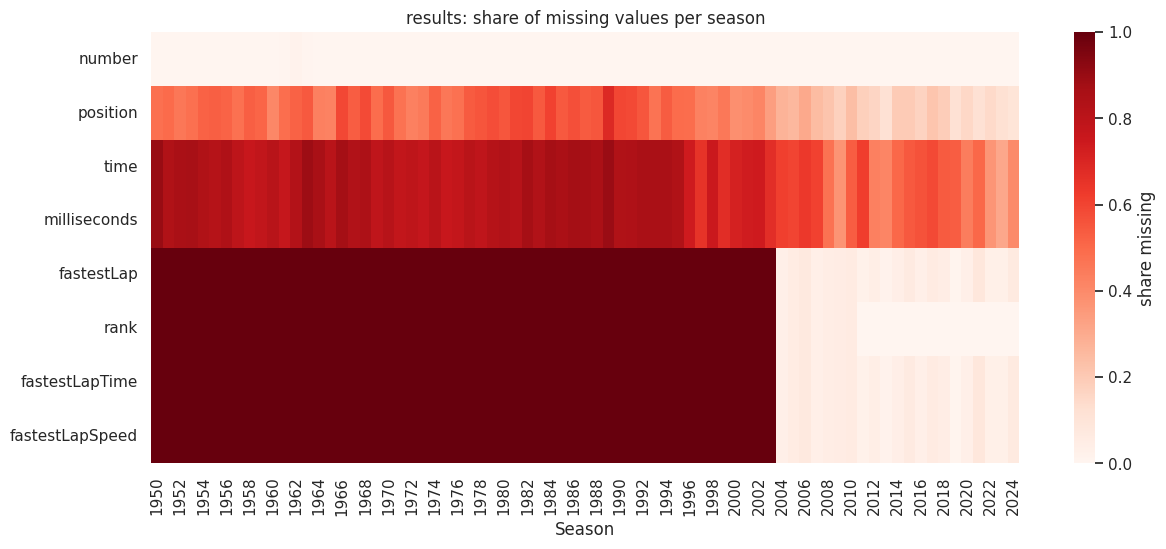

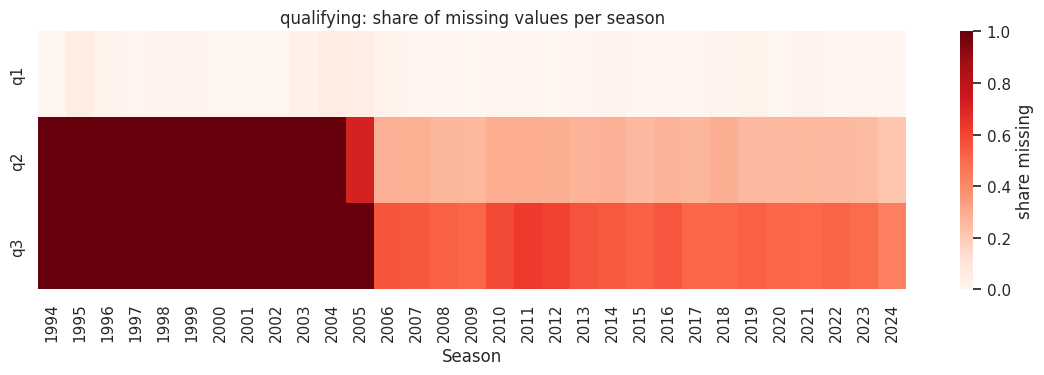

In [156]:
race_year = raw['races'][['raceId', 'year']]

def missing_by_year(table):
    tmp = raw[table].replace(SENTINEL, np.nan).merge(race_year, on='raceId', how='left')
    return tmp.drop(columns=['raceId']).isna().groupby(tmp['year']).mean()

for t in ['results', 'qualifying']:
    m = missing_by_year(t)
    m = m.loc[:, m.sum() > 0]
    plt.figure(figsize=(14, 0.45 * m.shape[1] + 2))
    sns.heatmap(m.T, cmap='Reds', vmin=0, vmax=1, cbar_kws={'label': 'share missing'})
    plt.title(f'{t}: share of missing values per season')
    plt.xlabel('Season')
    plt.show()

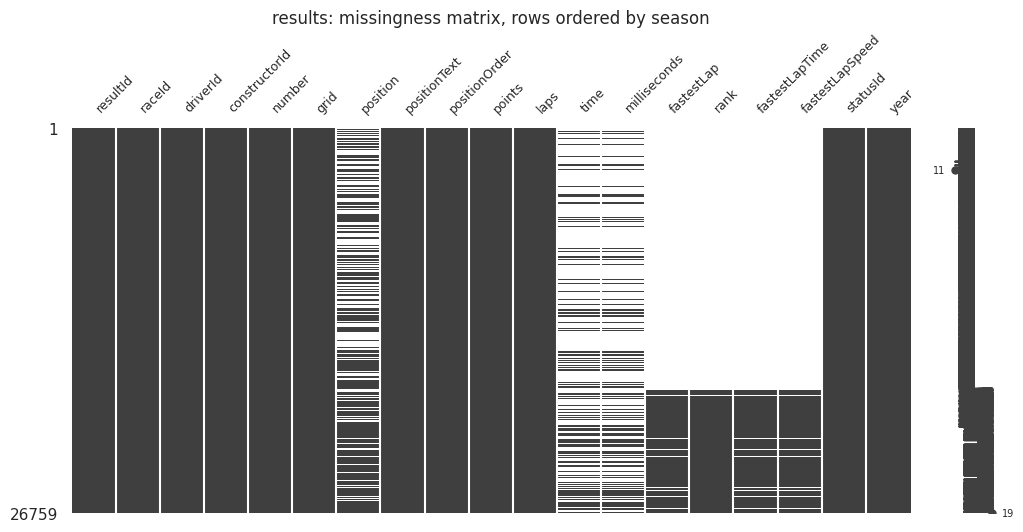

In [157]:
if msno is not None:
    tmp = raw['results'].replace(SENTINEL, np.nan).merge(race_year, on='raceId').sort_values('year')
    msno.matrix(tmp, figsize=(12, 5), fontsize=9)
    plt.title('results: missingness matrix, rows ordered by season')
    plt.show()

> **Interpretation:** `time`, `milliseconds` and fastest-lap columns are post-race and mostly missing before the 2000s; they are never features. `position` is missing whenever a driver was not classified, which is why the target uses `positionOrder`.

### 4.4 Domain checks (from our notes and the newcomer guide)

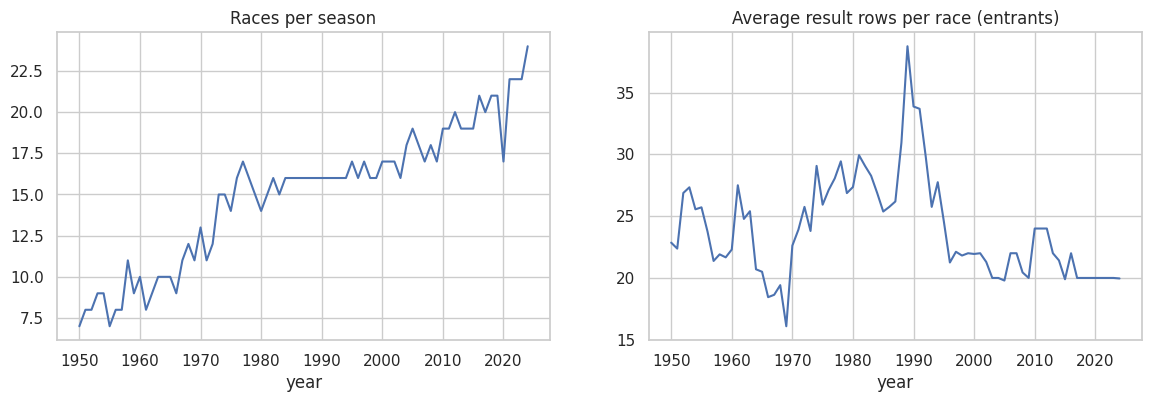

In [158]:
res = raw['results'].merge(race_year, on='raceId')
res['grid_num'] = pd.to_numeric(res['grid'], errors='coerce')
res['po_num'] = pd.to_numeric(res['positionOrder'], errors='coerce')

per_season = pd.DataFrame({
    'races': raw['races'].groupby('year')['raceId'].nunique(),
    'rows_per_race': res.groupby('year').size() / res.groupby('year')['raceId'].nunique(),
})
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
per_season['races'].plot(ax=axes[0], title='Races per season')
per_season['rows_per_race'].plot(ax=axes[1], title='Average result rows per race (entrants)')
plt.show()

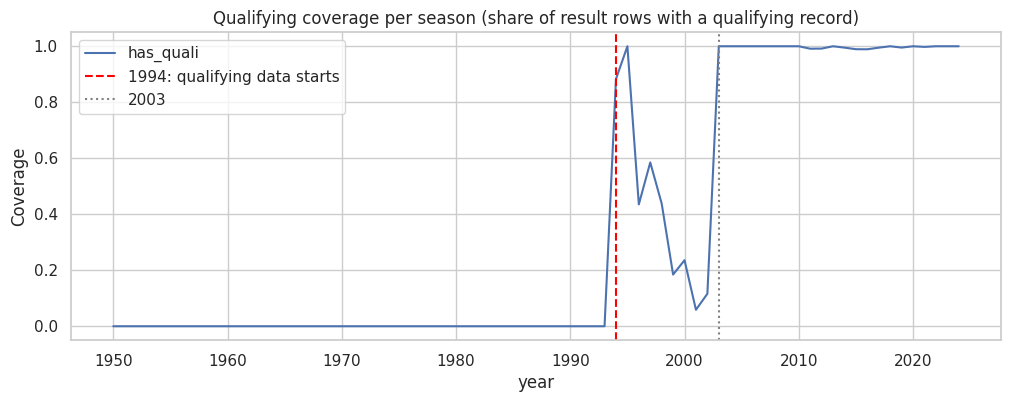

year,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006
coverage,0.0,0.88,1.0,0.44,0.59,0.44,0.18,0.24,0.06,0.12,1.0,1.0,1.0,1.0


In [159]:
# Qualifying coverage: share of result rows (raceId, driverId) that have a qualifying row
q_keys = raw['qualifying'][['raceId', 'driverId']].drop_duplicates().assign(has_quali=1)
cov = res.merge(q_keys, on=['raceId', 'driverId'], how='left')
cov['has_quali'] = cov['has_quali'].fillna(0)
cov_before = cov.groupby('year')['has_quali'].mean()

ax = cov_before.plot(figsize=(12, 4))
ax.axvline(1994, color='red', ls='--', label='1994: qualifying data starts')
ax.axvline(2003, color='grey', ls=':', label='2003')
plt.title('Qualifying coverage per season (share of result rows with a qualifying record)')
plt.ylabel('Coverage'); plt.legend()
plt.show()
cov_before.loc[1993:2006].round(2).to_frame('coverage').T

> **Interpretation (important for D7):** qualifying data starts in 1994 but is **patchy until 2003**. Several seasons in 1996–2002 have qualifying rows for only a few races. Because the model trains on every season from 1950 (D7, TA), most training rows have **no qualifying data at all**. Section 5.12 measures this and lists how the feature part works around it.

Non-numeric grid values: 0
grid == 0 rows: 1638


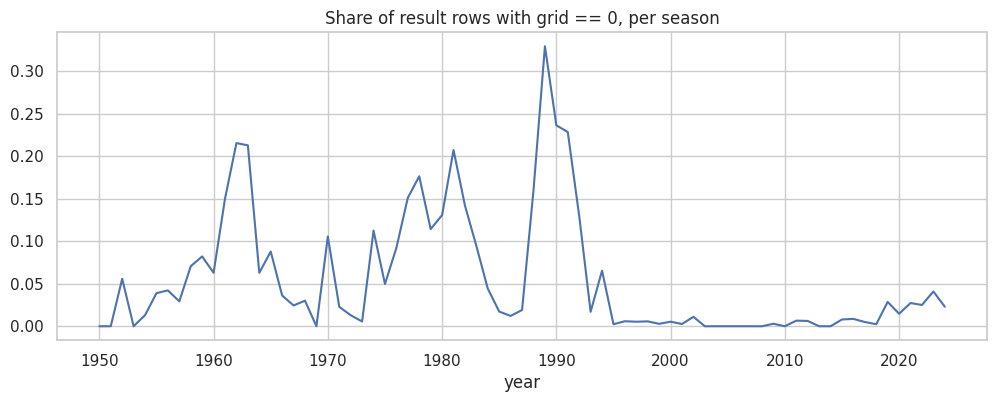

In [160]:
# grid == 0 per season
print('Non-numeric grid values:', res['grid_num'].isna().sum())
print('grid == 0 rows:', (res['grid_num'] == 0).sum())
res.assign(grid_zero=res['grid_num'] == 0).groupby('year')['grid_zero'].mean() \
   .plot(figsize=(12, 4), title='Share of result rows with grid == 0, per season')
plt.show()

In [161]:
# Evidence for D3/D4: what does grid == 0 mean? Cross grid 0 with laps and status.
res_st = res.merge(raw['status'], on='statusId', how='left')
res_st['laps_num'] = pd.to_numeric(res_st['laps'], errors='coerce')
g0 = res_st[res_st['grid_num'] == 0]
g0_table = (g0.assign(drove_laps=np.where(g0['laps_num'] > 0, 'laps > 0', 'laps = 0'))
              .groupby(['drove_laps', 'status']).size().rename('rows')
              .reset_index().sort_values(['drove_laps', 'rows'], ascending=[True, False]))
print(g0_table.groupby('drove_laps')['rows'].sum())
g0_table.groupby('drove_laps').head(8)

drove_laps
laps = 0    1566
laps > 0      72
Name: rows, dtype: int64


,drove_laps,status,rows
5,laps = 0,Did not qualify,1013
4,laps = 0,Did not prequalify,331
17,laps = 0,Withdrew,164
1,laps = 0,Accident,18
12,laps = 0,Injury,8
6,laps = 0,Disqualified,6
7,laps = 0,Engine,6
8,laps = 0,Excluded,6
18,laps > 0,+1 Lap,27
24,laps > 0,Finished,22


> **Interpretation:** grid 0 has **two different meanings**. With `laps = 0` it is almost always a non-starter (did not qualify, did not prequalify, withdrew). With `laps > 0` the driver raced, so it is a genuine **pit-lane start**. This justifies D3 and D4.

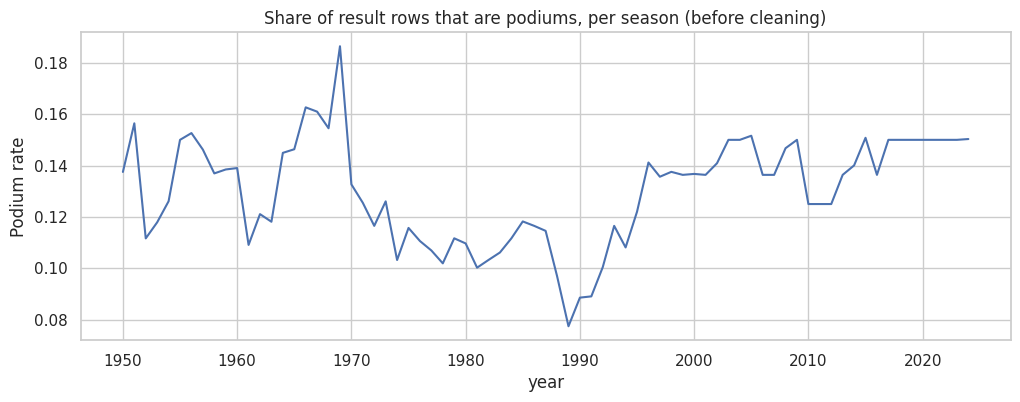

In [162]:
# Podium base rate per season (class imbalance by era)
res.assign(podium=res['po_num'] <= 3).groupby('year')['podium'].mean().plot(figsize=(12, 4))
plt.title('Share of result rows that are podiums, per season (before cleaning)')
plt.ylabel('Podium rate')
plt.show()

Distinct status values used in results: 137


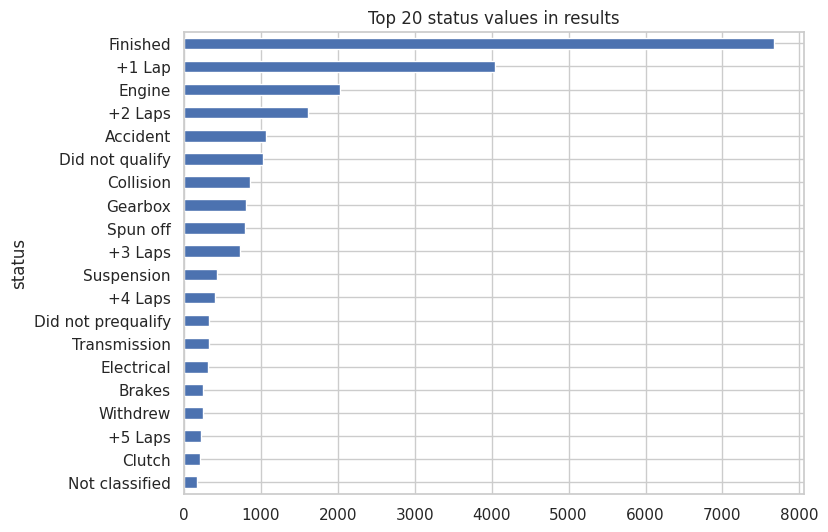

In [163]:
status_counts = res_st['status'].value_counts()
print('Distinct status values used in results:', status_counts.size)
status_counts.head(20).plot(kind='barh', figsize=(8, 6))
plt.title('Top 20 status values in results')
plt.gca().invert_yaxis()
plt.show()

In [164]:
pt = raw['results']['positionText']
pt[~pt.str.isdigit()].value_counts().rename('rows').to_frame()

,rows
positionText,
R,8897
F,1368
W,336
N,190
D,151
E,9


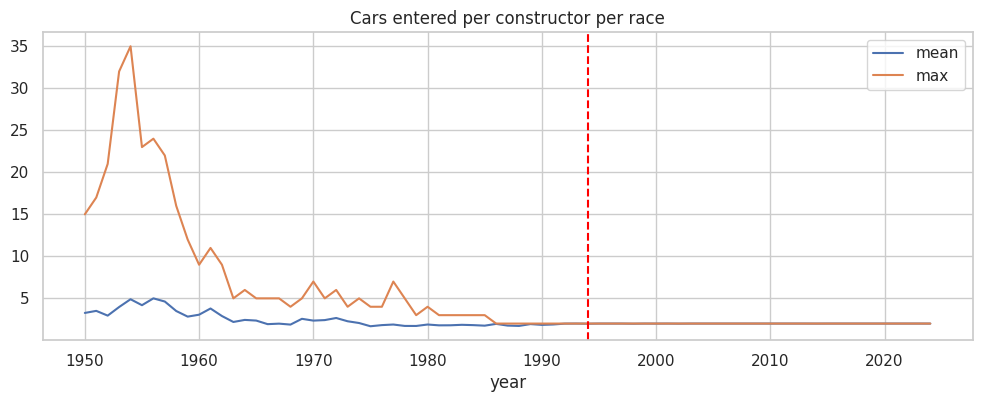

In [165]:
# Evidence for D6 (privateers): cars per constructor per race. Customer cars inflate this in early decades.
cars = res.groupby(['year', 'raceId', 'constructorId']).size().rename('cars').reset_index()
cars_by_year = cars.groupby('year')['cars'].agg(['mean', 'max'])
ax = cars_by_year.plot(figsize=(12, 4), title='Cars entered per constructor per race')
ax.axvline(1994, color='red', ls='--')
plt.show()

In [166]:
# Evidence for D13: country / nationality spellings
print('Circuit countries:', sorted(raw['circuits']['country'].unique()))
print()
print('Driver nationalities:', sorted(raw['drivers']['nationality'].unique()))

Circuit countries: ['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']

Driver nationalities: ['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian ', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan']


> **Interpretation:** the same country appears under two spellings (`USA` and `United States`), one nationality has a trailing space (`'Argentinian '`), and some are double (`American-Italian`). These are handled in 5.16. If `\N` appears among nationalities, those drivers have no recorded nationality.

## 5. Cleaning (on copies)

From here on we only modify `clean`. `raw` stays as the before/after reference.

### 5.0 Scope: every season in the dataset
**Decision (TA):** use the whole attached dataset; no seasons are cut. `MAX_YEAR` stays as a switch so the scope can be changed in one place.

In [167]:
MAX_YEAR = None          # None = keep every season in the attached dataset (TA decision)
clean = {t: df.copy() for t, df in raw.items()}

races_year = pd.to_numeric(clean['races']['year'])
keep_mask = races_year.notna() if MAX_YEAR is None else races_year <= MAX_YEAR
keep_race_ids = set(clean['races'].loc[keep_mask, 'raceId'])
scope_log = {}
for t, df in clean.items():
    if 'raceId' in df.columns:
        before = len(df)
        clean[t] = df[df['raceId'].isin(keep_race_ids)].copy()
        scope_log[t] = before - len(clean[t])
if MAX_YEAR is not None:
    clean['seasons'] = clean['seasons'][pd.to_numeric(clean['seasons']['year']) <= MAX_YEAR].copy()
print('Seasons in scope:', int(races_year[keep_mask].min()), '-', int(races_year[keep_mask].max()))
pd.Series(scope_log, name='rows removed by scope').to_frame()

Seasons in scope: 1950 - 2024


,rows removed by scope
constructor_results,0
constructor_standings,0
driver_standings,0
races,0
results,0
qualifying,0
lap_times,0
pit_stops,0
sprint_results,0


### 5.1 Missing-value placeholders and whitespace
**Evidence:** 4.1 and 4.2. Two placeholders mean "missing" in these files:
- the literal text `\N` (the documented sentinel);
- an **empty string** in `qualifying.q2` and `q3` (4.1 counts them in `n_empty`; on our Kaggle copy 22 and 46 rows).

**Step:** strip stray whitespace from text columns, then turn both placeholders into NaN. The check confirms the NaN count equals the number of placeholders found.

In [168]:
def count_placeholders(df):
    s = df.astype(str)
    return int((s == SENTINEL).sum().sum()), int((s.apply(lambda c: c.str.strip()) == '').sum().sum())

before = {t: count_placeholders(clean[t]) for t in clean}
for t in clean:
    for col in [c for c in clean[t].columns if is_text(clean[t][c])]:
        clean[t][col] = clean[t][col].str.strip()
    clean[t] = clean[t].replace({SENTINEL: np.nan, '': np.nan})

check = pd.DataFrame({'sentinel_N': {t: b[0] for t, b in before.items()},
                      'empty_string': {t: b[1] for t, b in before.items()},
                      'nan_after': {t: int(clean[t].isna().sum().sum()) for t in clean}})
check['match'] = (check['sentinel_N'] + check['empty_string']) == check['nan_after']
assert check['match'].all(), 'NaN count differs from placeholder count: another placeholder exists'
check[(check['sentinel_N'] + check['empty_string']) > 0]

,sentinel_N,empty_string,nan_after,match
constructor_results,12608,0,12608,True
drivers,1559,0,1559,True
races,11349,0,11349,True
results,122887,0,122887,True
qualifying,11600,68,11668,True
sprint_results,73,0,73,True


> **Decision:** `\N` and empty strings are the only placeholders (counts match exactly). Letter codes in `positionText` (R, F, W, N, D, E) are categories, not missing values, so they are kept. Whitespace is stripped because `'Argentinian '` would break the nationality mapping.

### 5.2 Semantic typing
#### 5.2.1 Numeric columns

In [169]:
numeric_report = []
for t, df in clean.items():
    for col in df.columns:
        if not is_text(df[col]):
            continue
        non_null = df[col].notna().sum()
        converted = pd.to_numeric(df[col], errors='coerce')
        parsed = converted.notna().sum()
        if non_null > 0 and parsed == non_null:
            # whole numbers -> nullable integer (keeps NaN as <NA>), else float
            clean[t][col] = converted.astype('Int64') if (converted.dropna() % 1 == 0).all() else converted
            numeric_report.append({'table': t, 'column': col, 'action': 'converted'})
        elif parsed > 0:
            numeric_report.append({'table': t, 'column': col,
                                   'action': f'partly numeric ({parsed}/{non_null}), left as text'})
pd.DataFrame(numeric_report)

,table,column,action
0,constructor_standings,positionText,"partly numeric (13374/13391), left as text"
1,drivers,number,converted
2,driver_standings,positionText,"partly numeric (34862/34863), left as text"
3,results,number,converted
4,results,position,converted
5,results,positionText,"partly numeric (15808/26759), left as text"
6,results,time,"partly numeric (4359/7680), left as text"
7,results,milliseconds,converted
8,results,fastestLap,converted
9,results,rank,converted


> **Partly numeric columns:** `positionText` (letter codes, kept as text by design) and time strings such as `pit_stops.duration`, converted to seconds in 5.2.3. Nothing else needs handling.

#### 5.2.2 Date columns

In [170]:
DATE_COLUMNS = {'races': ['date', 'fp1_date', 'fp2_date', 'fp3_date', 'quali_date', 'sprint_date'],
                'drivers': ['dob']}
date_report = []
for t, cols in DATE_COLUMNS.items():
    for col in cols:
        before_non_null = clean[t][col].notna().sum()
        clean[t][col] = pd.to_datetime(clean[t][col], errors='coerce')
        date_report.append({'column': f'{t}.{col}', 'non_null': int(before_non_null),
                            'failed_to_parse': int(before_non_null - clean[t][col].notna().sum()),
                            'min': clean[t][col].min(), 'max': clean[t][col].max()})
pd.DataFrame(date_report)

,column,non_null,failed_to_parse,min,max
0,races.date,1125,0,1950-05-13,2024-12-08
1,races.fp1_date,90,0,2021-03-26,2024-12-06
2,races.fp2_date,90,0,2021-03-26,2024-12-06
3,races.fp3_date,72,0,2021-03-27,2024-12-07
4,races.quali_date,90,0,2021-03-27,2024-12-07
5,races.sprint_date,18,0,2021-07-17,2024-11-30
6,drivers.dob,861,0,1896-12-28,2005-05-08


#### 5.2.3 Duration columns (time strings → seconds)

In [171]:
TIME_PATTERN = re.compile(r'^(\d+:)?\d{1,2}\.\d+$')

def time_to_seconds(value):
    '''"1:26.572" -> 86.572, "26.572" -> 26.572, NaN or anything else -> NaN'''
    if pd.isna(value):
        return np.nan
    value = str(value).strip()
    if not TIME_PATTERN.match(value):
        return np.nan
    if ':' in value:
        minutes, seconds = value.split(':')
        return int(minutes) * 60 + float(seconds)
    return float(value)

# Unit tests on hand-picked values, including the red-flag pit-stop format
tests = {'1:26.572': 86.572, '26.572': 26.572, '24:16.349': 1456.349, 'abc': None, np.nan: None}
for v, expected in tests.items():
    out = time_to_seconds(v)
    assert (np.isnan(out) if expected is None else abs(out - expected) < 1e-9), (v, out)
print('time_to_seconds: all tests passed')

time_to_seconds: all tests passed


In [172]:
DURATION_COLUMNS = {'qualifying': ['q1', 'q2', 'q3'],
                    'pit_stops': ['duration'],
                    'results': ['fastestLapTime']}
dur_report = []
for t, cols in DURATION_COLUMNS.items():
    for col in cols:
        before_non_null = clean[t][col].notna().sum()
        clean[t][col + '_sec'] = clean[t][col].apply(time_to_seconds)
        bad = clean[t].loc[clean[t][col].notna() & clean[t][col + '_sec'].isna(), col]
        dur_report.append({'column': f'{t}.{col}', 'non_null': int(before_non_null),
                           'failed_to_parse': len(bad),
                           'unparsed_examples': bad.value_counts().head(5).to_dict()})
pd.DataFrame(dur_report)

,column,non_null,failed_to_parse,unparsed_examples
0,qualifying.q1,10338,0,{}
1,qualifying.q2,5847,0,{}
2,qualifying.q3,3629,0,{}
3,pit_stops.duration,11371,0,{}
4,results.fastestLapTime,8252,0,{}


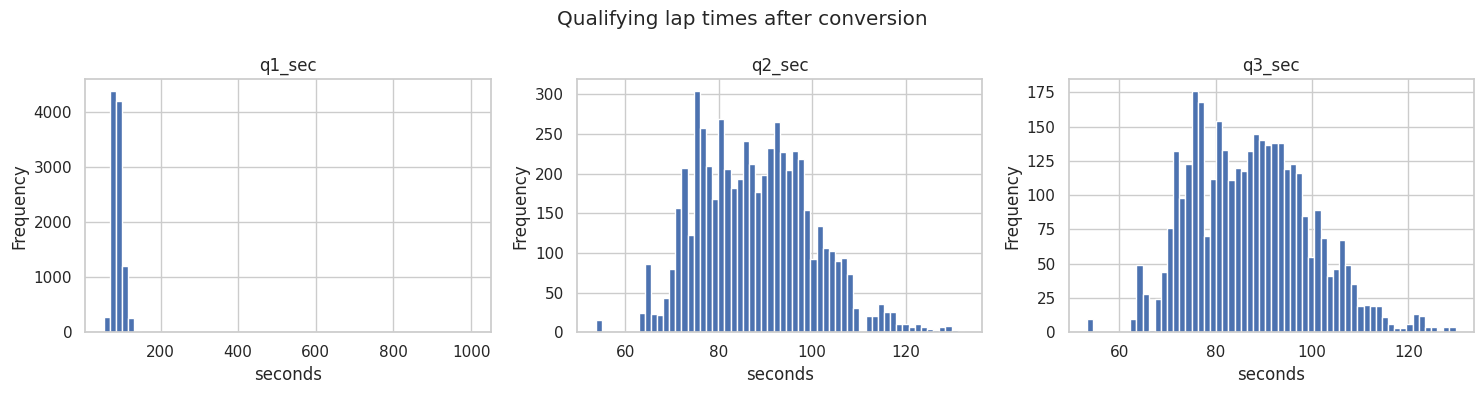

In [173]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['q1_sec', 'q2_sec', 'q3_sec']):
    clean['qualifying'][col].plot(kind='hist', bins=60, ax=ax, title=col)
    ax.set_xlabel('seconds')
plt.suptitle('Qualifying lap times after conversion')
plt.tight_layout(); plt.show()

**Outlier vs invalid value.** An *outlier* is unusual but possible (a slow lap in the rain): it is kept. An *invalid* value is impossible: a qualifying lap more than **twice the median lap of the same session** cannot be a real flying lap (e.g. `16:42.640` in the 1995 Japanese GP, where everyone else lapped in about 1:40). Invalid values are set to NaN, and the text column is kept, so the change is visible.

In [174]:
invalid_log = {}
for col in ['q1_sec', 'q2_sec', 'q3_sec']:
    session_median = clean['qualifying'].groupby('raceId')[col].transform('median')
    invalid = clean['qualifying'][col] > 2 * session_median
    invalid_log[col] = int(invalid.sum())
    if invalid.any():
        display(clean['qualifying'].loc[invalid, ['raceId', 'driverId', col.replace('_sec', ''), col]]
                .merge(clean['races'][['raceId', 'year', 'name']], on='raceId'))
    clean['qualifying'].loc[invalid, col] = np.nan
pd.Series(invalid_log, name='impossible lap times set to NaN').to_frame()

,raceId,driverId,q1,q1_sec,year,name
0,255,87,16:42.640,1002.64,1995,Japanese Grand Prix


,impossible lap times set to NaN
q1_sec,1
q2_sec,0
q3_sec,0


> **Decision:** real outliers (slow but possible laps, red-flag pit stops) are kept. Only impossible values (more than 2× the session median) are set to NaN. Raw times are not compared across circuits anyway (see D14).

### 5.3 Primary keys and schema constraints (D1)

In [175]:
PRIMARY_KEYS = {
    'seasons': ['year'], 'circuits': ['circuitId'], 'drivers': ['driverId'],
    'constructors': ['constructorId'], 'races': ['raceId'], 'status': ['statusId'],
    'results': ['resultId'], 'sprint_results': ['resultId'], 'qualifying': ['qualifyId'],
    'driver_standings': ['driverStandingsId'], 'constructor_standings': ['constructorStandingsId'],
    'constructor_results': ['constructorResultsId'],
    'lap_times': ['raceId', 'driverId', 'lap'],     # composite key
    'pit_stops': ['raceId', 'driverId', 'stop'],    # composite key
}

def check_pk(df, cols):
    return {'key': cols,
            'null_rows': int(df[cols].isna().any(axis=1).sum()),
            'duplicate_rows': int(df.duplicated(subset=cols, keep=False).sum())}

pk_report = pd.DataFrame({t: check_pk(clean[t], cols) for t, cols in PRIMARY_KEYS.items()}).T
pk_report

,key,null_rows,duplicate_rows
seasons,[year],0,0
circuits,[circuitId],0,0
drivers,[driverId],0,0
constructors,[constructorId],0,0
races,[raceId],0,0
status,[statusId],0,0
results,[resultId],0,0
sprint_results,[resultId],0,0
qualifying,[qualifyId],0,0
driver_standings,[driverStandingsId],0,0


In [176]:
# Every UNIQUE and NOT NULL constraint from f1_schema.sql, tested as a pass/fail check
UNIQUE_CONSTRAINTS = [
    ('races', ['year', 'round']), ('races', ['url']),
    ('circuits', ['circuitRef']), ('circuits', ['url']),
    ('constructors', ['constructorRef']), ('constructors', ['name']),
    ('drivers', ['driverRef']), ('drivers', ['url']), ('seasons', ['url']),
    ('driver_standings', ['raceId', 'driverId']),
    ('constructor_standings', ['raceId', 'constructorId']),
    ('constructor_results', ['raceId', 'constructorId']),
]
NOT_NULL = {
    'results': ['raceId', 'driverId', 'constructorId', 'grid', 'positionText', 'positionOrder',
                'points', 'laps', 'statusId'],
    'qualifying': ['raceId', 'driverId', 'constructorId', 'number', 'position'],
    'races': ['year', 'round', 'circuitId', 'name', 'date'],
    'drivers': ['driverRef', 'forename', 'surname'],
    'sprint_results': ['number', 'grid', 'positionOrder', 'laps', 'statusId'],
    'pit_stops': ['lap', 'time'],
    'driver_standings': ['points', 'wins'], 'constructor_standings': ['points', 'wins'],
}

constraint_rows = []
for t, cols in UNIQUE_CONSTRAINTS:
    n = int(clean[t].dropna(subset=cols).duplicated(subset=cols, keep=False).sum())
    constraint_rows.append({'constraint': f'UNIQUE {t}({", ".join(cols)})', 'failing_rows': n})
for t, cols in NOT_NULL.items():
    for c in cols:
        constraint_rows.append({'constraint': f'NOT NULL {t}.{c}', 'failing_rows': int(clean[t][c].isna().sum())})
constraint_report = pd.DataFrame(constraint_rows)
constraint_report['result'] = np.where(constraint_report['failing_rows'] == 0, 'pass', 'FAIL')
print(constraint_report['result'].value_counts().to_dict())
constraint_report[constraint_report['result'] == 'FAIL']

{'pass': 45}


,constraint,failing_rows,result


> **Interpretation:** all primary keys are unique and non-null, and all 45 UNIQUE / NOT NULL constraints from the schema pass. `UNIQUE` on `(raceId, driverId)` in **results** is deliberately not in the schema: it is the grain problem handled in 5.9.

### 5.4 Foreign keys: every reference exists in the parent table

In [177]:
FOREIGN_KEYS = [
    ('races', 'year', 'seasons', 'year'),
    ('races', 'circuitId', 'circuits', 'circuitId'),
    ('results', 'raceId', 'races', 'raceId'),
    ('results', 'driverId', 'drivers', 'driverId'),
    ('results', 'constructorId', 'constructors', 'constructorId'),
    ('results', 'statusId', 'status', 'statusId'),
    ('sprint_results', 'raceId', 'races', 'raceId'),
    ('sprint_results', 'driverId', 'drivers', 'driverId'),
    ('sprint_results', 'constructorId', 'constructors', 'constructorId'),
    ('sprint_results', 'statusId', 'status', 'statusId'),
    ('qualifying', 'raceId', 'races', 'raceId'),
    ('qualifying', 'driverId', 'drivers', 'driverId'),
    ('qualifying', 'constructorId', 'constructors', 'constructorId'),
    ('driver_standings', 'raceId', 'races', 'raceId'),
    ('driver_standings', 'driverId', 'drivers', 'driverId'),
    ('constructor_standings', 'raceId', 'races', 'raceId'),
    ('constructor_standings', 'constructorId', 'constructors', 'constructorId'),
    ('constructor_results', 'raceId', 'races', 'raceId'),
    ('constructor_results', 'constructorId', 'constructors', 'constructorId'),
    ('lap_times', 'raceId', 'races', 'raceId'),
    ('lap_times', 'driverId', 'drivers', 'driverId'),
    ('pit_stops', 'raceId', 'races', 'raceId'),
    ('pit_stops', 'driverId', 'drivers', 'driverId'),
]
fk_rows = []
for child, c_col, parent, p_col in FOREIGN_KEYS:
    values = clean[child][c_col]
    orphans = values.notna() & ~values.isin(clean[parent][p_col])
    fk_rows.append({'fk': f'{child}.{c_col} -> {parent}.{p_col}',
                    'null_fk': int(values.isna().sum()), 'orphans': int(orphans.sum())})
fk_report = pd.DataFrame(fk_rows).set_index('fk')
print(f"{len(fk_report)} foreign keys checked, total orphans = {fk_report['orphans'].sum()}")
fk_report

23 foreign keys checked, total orphans = 0


,null_fk,orphans
fk,,
races.year -> seasons.year,0,0
races.circuitId -> circuits.circuitId,0,0
results.raceId -> races.raceId,0,0
results.driverId -> drivers.driverId,0,0
results.constructorId -> constructors.constructorId,0,0
results.statusId -> status.statusId,0,0
sprint_results.raceId -> races.raceId,0,0
sprint_results.driverId -> drivers.driverId,0,0
sprint_results.constructorId -> constructors.constructorId,0,0


> **Decision:** with zero orphans and zero null foreign keys, no rows are dropped here. Every join in later parts is safe.

### 5.5 Chronological order key

`raceId` is **not** in date order (races were added to the database out of order), so it must never be used to mean "earlier". We build `race_order` from `(year, round)`. Every past-races-only feature later sorts by it.

In [178]:
r_ = clean['races']
print('raceId increasing with date?', r_.sort_values('raceId')['date'].is_monotonic_increasing)
clean['races'] = r_.sort_values(['year', 'round']).reset_index(drop=True)
clean['races']['race_order'] = np.arange(1, len(clean['races']) + 1)
assert clean['races']['date'].is_monotonic_increasing
clean['races'][['raceId', 'year', 'round', 'date', 'race_order']].head()

raceId increasing with date? False


,raceId,year,round,date,race_order
0,833,1950,1,1950-05-13,1
1,834,1950,2,1950-05-21,2
2,835,1950,3,1950-05-30,3
3,836,1950,4,1950-06-04,4
4,837,1950,5,1950-06-18,5


### 5.6 D5: exclude the Indianapolis 500 (1950–1960)

Almost no regular F1 drivers entered it, its drivers rarely raced elsewhere, and it distorts race counts, home-race analysis (Q2) and grid structure. We remove its races from **every** table that references `raceId`.

In [179]:
indy = clean['races'][clean['races']['name'].str.contains('Indianapolis', case=False, na=False)]
print('Indianapolis races found:', len(indy), '| years', indy['year'].min(), '-', indy['year'].max())
assert indy['year'].max() <= 1960, 'Filter caught a non-Indy-500 race'
indy_ids = set(indy['raceId'])

indy_results = clean['results'][clean['results']['raceId'].isin(indy_ids)].copy()   # kept for the D5 experiment
indy_log = {}
for t, df in clean.items():
    if 'raceId' in df.columns:
        mask = df['raceId'].isin(indy_ids)
        indy_log[t] = int(mask.sum())
        clean[t] = df[~mask].copy()
clean['indy_results'] = indy_results
clean['indy_races'] = indy.copy()                      # kept for the D5 experiment (14.3)
pd.Series(indy_log, name='rows removed (Indy 500)').to_frame().query('`rows removed (Indy 500)` > 0')

Indianapolis races found: 11 | years 1950 - 1960


,rows removed (Indy 500)
constructor_results,21
constructor_standings,26
driver_standings,669
races,11
results,405


### 5.7 D9: status groups and the mechanical definition

**Definition used (brief note):** a mechanical retirement is a race start that ended early *because a component of the car failed*. It excludes crashes, driver causes and regulation decisions.

**Sources for each group**
- The newcomer guide names Engine, Gearbox, Hydraulics, Brakes, Power Unit as mechanical examples, so every status naming a car component is mechanical.
- Piazza (instructor): Puncture, Tyre, Tyre puncture, Fire, Safety belt are mechanical; Refuelling is **not**.
- Statuses that give **no cause** (Retired, Damage, Debris, Out of fuel, Withdrew, Not classified …) go to `unclear` and are **not** counted as mechanical. The brief requires a component to have failed; these rows don't tell us that.
- **Wings, undertray, wheel:** the data cannot say whether a part failed on its own or after contact. Crash-caused retirements have their own statuses (`Collision damage`, `Damage`), so a status that names a part is read as that part failing. This matches the instructor's ruling on Puncture (often caused by debris, still counted as mechanical).

Every status used in `results` must land in exactly one group; the cell stops otherwise.

In [180]:
DID_NOT_START = {'Did not qualify', 'Did not prequalify', '107% Rule', 'Did not start'}
REGULATION = {'Disqualified', 'Excluded', 'Underweight'}
ACCIDENT_DRIVER = {'Accident', 'Collision', 'Collision damage', 'Spun off', 'Fatal accident', 'Stalled',
                   'Driver unwell', 'Illness', 'Injury', 'Injured', 'Eye injury', 'Physical'}
NOT_MECHANICAL_OTHER = {'Refuelling', 'Fuel rig'}          # Piazza: refuelling is not mechanical
UNCLEAR = {'Retired', 'Damage', 'Debris', 'Out of fuel', 'Withdrew', 'Not classified', 'Not restarted',
           'Safety', 'Safety concerns'}
MECHANICAL = {
    # named in the brief / guide
    'Engine', 'Gearbox', 'Hydraulics', 'Brakes', 'Power Unit',
    # instructor ruling on Piazza
    'Puncture', 'Tyre', 'Tyre puncture', 'Fire', 'Safety belt',
    # other car components
    'Alternator', 'Axle', 'Battery', 'Brake duct', 'Broken wing', 'CV joint', 'Chassis', 'Clutch',
    'Cooling system', 'Crankshaft', 'Differential', 'Distributor', 'Driver Seat', 'Driveshaft', 'Drivetrain',
    'ERS', 'Electrical', 'Electronics', 'Engine fire', 'Engine misfire', 'Exhaust', 'Front wing', 'Fuel',
    'Fuel leak', 'Fuel pipe', 'Fuel pressure', 'Fuel pump', 'Fuel system', 'Halfshaft', 'Handling',
    'Heat shield fire', 'Ignition', 'Injection', 'Launch control', 'Magneto', 'Mechanical', 'Oil leak',
    'Oil line', 'Oil pipe', 'Oil pressure', 'Oil pump', 'Overheating', 'Pneumatics', 'Power loss', 'Radiator',
    'Rear wing', 'Safety switch', 'Seat', 'Spark plugs', 'Steering', 'Supercharger', 'Suspension', 'Technical',
    'Throttle', 'Track rod', 'Transmission', 'Turbo', 'Undertray', 'Vibration', 'Vibrations', 'Water leak',
    'Water pipe', 'Water pressure', 'Water pump', 'Wheel', 'Wheel bearing', 'Wheel nut', 'Wheel rim',
}
GROUPS = {'did_not_start': DID_NOT_START, 'regulation': REGULATION, 'accident_driver': ACCIDENT_DRIVER,
          'not_mechanical_other': NOT_MECHANICAL_OTHER, 'unclear': UNCLEAR, 'mechanical': MECHANICAL}
overlap = [(a, b) for a in GROUPS for b in GROUPS if a < b and GROUPS[a] & GROUPS[b]]
assert not overlap, f'status in two groups: {overlap}'

def status_group(s):
    if s == 'Finished':
        return 'finished'
    if re.fullmatch(r'\+\d+ Laps?', s) or s == 'Lapped':
        return 'lapped'
    for name, members in GROUPS.items():
        if s in members:
            return name
    return 'UNMAPPED'

clean['status']['status_base'] = clean['status']['status'].map(status_group)
clean['status']['is_mechanical'] = clean['status']['status_base'] == 'mechanical'

used = clean['status'][clean['status']['statusId'].isin(clean['results']['statusId'])]
unmapped = used.loc[used['status_base'] == 'UNMAPPED', 'status'].tolist()
assert not unmapped, f'Status values used in results but not mapped: {unmapped}'
used['status_base'].value_counts().rename('status values used').to_frame()

,status values used
status_base,
mechanical,76
lapped,30
accident_driver,12
unclear,9
did_not_start,3
regulation,3
not_mechanical_other,2
finished,1


In [181]:
# Q3 period check: how many 2014-2024 retirements land in each group, and how big the 'unclear' group is
q3_scope = (clean['results'].merge(clean['races'][['raceId', 'year']], on='raceId')
            .query('2014 <= year <= 2024')
            .merge(clean['status'], on='statusId'))
# race starts only (the brief defines the rate per start); same rule as D3 in 5.8
never_started = ((q3_scope['status_base'] == 'did_not_start') | ((q3_scope['grid'] == 0) & (q3_scope['laps'] == 0))
                 | ((q3_scope['status'] == 'Withdrew') & (q3_scope['laps'] == 0)))
q3_scope = q3_scope[~never_started]
retired = q3_scope[~q3_scope['status_base'].isin(['finished', 'lapped'])]
print(retired['status_base'].value_counts().to_string())
print()
print('Unclear statuses in 2014-2024 (counted as NOT mechanical):')
retired.loc[retired['status_base'] == 'unclear', 'status'].value_counts().rename('rows').to_frame()

status_base
mechanical         409
accident_driver    308
unclear             57
regulation          12

Unclear statuses in 2014-2024 (counted as NOT mechanical):


,rows
status,
Retired,50
Withdrew,3
Damage,2
Out of fuel,1
Debris,1


> **Interpretation:** `Retired` is the largest unclear status in 2014–2024: the data records that the car stopped but gives no cause. Treating it as not mechanical follows the brief's wording (a component must have failed). As a robustness check, Q3 (9.3) recomputes the ranking with `unclear` counted as mechanical: the 2014–2021 ranking barely changes (Spearman ρ ≈ 0.98), so the choice matters little there.

### 5.8 D3: drop non-starters from the modeling table

**Rule (from the evidence in 4.4):** a row is a non-starter if any of these hold:
1. status is *Did not qualify*, *Did not prequalify*, *107% Rule* or *Did not start*;
2. `laps == 0` **and** `grid == 0` (no grid slot and never drove);
3. status is *Withdrew* **and** `laps == 0`.

A driver with a grid slot who retired on lap 1 (`grid > 0`, `laps == 0`) **did** start and is kept.
At the prediction cutoff a non-starter has no grid slot, so there is nothing to predict. Non-starters stay in `results_all` for EDA.

In [182]:
r_ = clean['results'].merge(clean['status'][['statusId', 'status', 'status_base']], on='statusId', how='left')
non_starter = (
    (r_['status_base'] == 'did_not_start')
    | ((r_['laps'] == 0) & (r_['grid'] == 0))
    | ((r_['status'] == 'Withdrew') & (r_['laps'] == 0))
)
r_['is_starter'] = ~non_starter
clean['results_all'] = r_.copy()                       # every entry, for EDA
clean['results'] = r_[r_['is_starter']].copy()         # starters only

print(f"Non-starters removed: {int(non_starter.sum())} of {len(r_)} rows ({non_starter.mean():.1%})")
r_[non_starter]['status'].value_counts().head(10).rename('non-starter rows').to_frame()

Non-starters removed: 1646 of 26354 rows (6.2%)


,non-starter rows
status,
Did not qualify,1025
Did not prequalify,331
Withdrew,225
Accident,18
107% Rule,9
Injury,8
Excluded,6
Disqualified,6
Engine,6


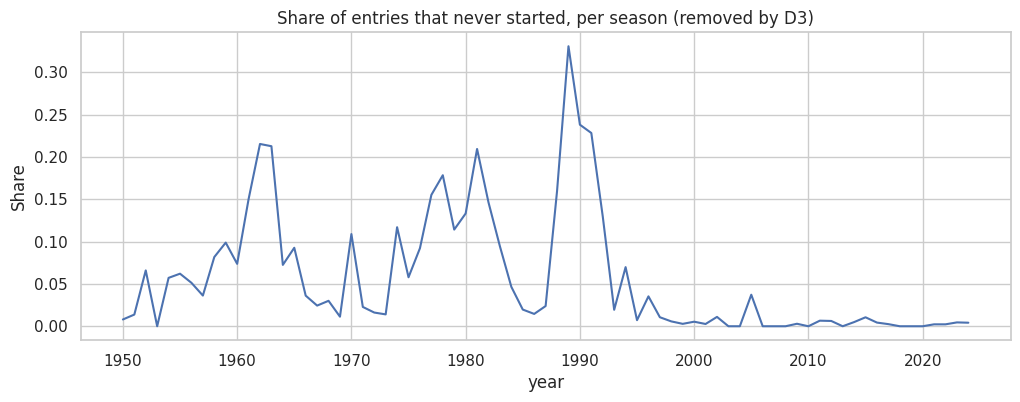

In [183]:
yr = clean['results_all'].merge(clean['races'][['raceId', 'year']], on='raceId')
yr.groupby('year')['is_starter'].apply(lambda s: 1 - s.mean()).plot(figsize=(12, 4))
plt.title('Share of entries that never started, per season (removed by D3)')
plt.ylabel('Share'); plt.show()

### 5.9 D2: shared drives — one driver per car, one row per driver

Until the late 1950s a driver could hand his car to a teammate mid-race. The data then has **one row per driver per car**: one car can appear with several drivers, and one driver can appear in two cars in the same race.

**What is a "car"?** Car numbers are *almost* unique per race, but not always: in the 1953 German GP number 12 was used by Farina's Ferrari (grid 3, **won**) and by Claes's car (grid 25, retired). The rows of a genuinely shared car always share the same starting grid, so a car is identified by **(raceId, number, grid)**.

Race/number combinations used by two different cars (different grid): 3
Shared cars (more than one driver): 74 | rows on those cars: 155
Drivers listed twice in one race (all entries / starters): 64 / 61
qualifying / sprint duplicates: 0 / 0


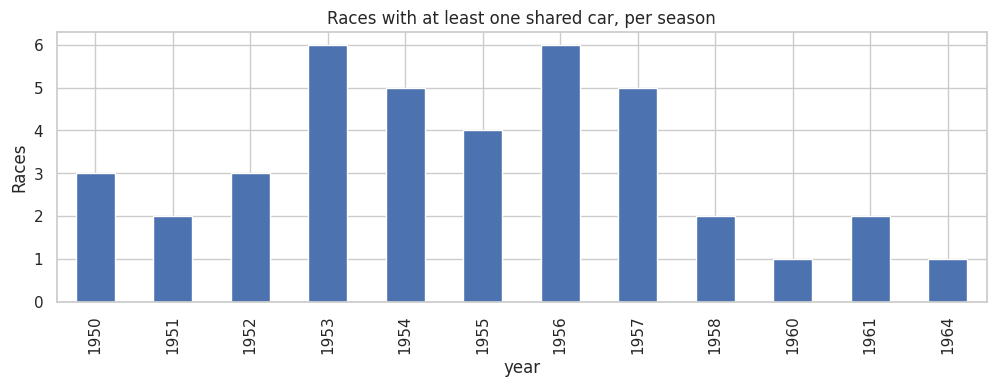

In [184]:
def grain_duplicates(df, keys=('raceId', 'driverId')):
    return df[df.duplicated(subset=list(keys), keep=False)]

CAR = ['raceId', 'number', 'grid']
r_ = clean['results']

# evidence: the same number used by two different cars in one race
num_reuse = r_.groupby(['raceId', 'number'])['grid'].nunique()
print('Race/number combinations used by two different cars (different grid):', int((num_reuse > 1).sum()))

drivers_per_car = r_.groupby(CAR)['driverId'].transform('nunique')
print('Shared cars (more than one driver):', r_[drivers_per_car > 1][CAR].drop_duplicates().shape[0],
      '| rows on those cars:', int((drivers_per_car > 1).sum()))
print('Drivers listed twice in one race (all entries / starters):',
      grain_duplicates(clean['results_all']).groupby(['raceId', 'driverId']).ngroups, '/',
      grain_duplicates(r_).groupby(['raceId', 'driverId']).ngroups)
print('qualifying / sprint duplicates:',
      len(grain_duplicates(clean['qualifying'])), '/', len(grain_duplicates(clean['sprint_results'])))

shared = r_[drivers_per_car > 1].merge(clean['races'][['raceId', 'year']], on='raceId')
shared.groupby('year')['raceId'].nunique().plot(kind='bar', figsize=(12, 3.5))
plt.title('Races with at least one shared car, per season'); plt.ylabel('Races')
plt.show()

**Chosen rule (D2, confirmed with the TA):** each car stays in the data once, with the driver who drove it **last**, and the row keeps the **car's starting grid**. Each driver stays in the data once.

"Drove it last" = the car's last entry (highest `resultId`): takeover entries were added to the database after the starting entry.

**Case 1: two drivers swap cars, both kept (1957 British GP).** Moss started car 18 from pole; it broke and he took over Brooks's car 20 (started P3), which won. Car 20 → **Moss, grid 3, won**. Car 18 → **Brooks, grid 1, retired**.

**Case 2: a driver's car breaks and he takes over a teammate's car (1961 US GP).** Gregory's own car 22 (grid 11) broke on lap 23; he took over Gendebien's car 21 (grid 15), which finished 11th. Car 21 → **Gregory, grid 15, 11th**. Car 22 had no other driver and Gregory is already used, so **car 22 is dropped**. Gendebien's only car now belongs to Gregory, so **Gendebien is removed from this race**.

In [185]:
clean['results_before_d2'] = clean['results'].copy()   # kept for the D2 experiment
r_ = clean['results'].copy()
before_rows = len(r_)
r_['is_last_entry'] = r_.groupby(CAR)['resultId'].transform('max') == r_['resultId']

kept, used_cars, used_drivers = [], set(), set()
for row in r_.sort_values(['raceId', 'is_last_entry', 'resultId'], ascending=[True, False, False]).itertuples():
    car, drv = (row.raceId, row.number, row.grid), (row.raceId, row.driverId)
    if car in used_cars or drv in used_drivers:
        continue
    used_cars.add(car); used_drivers.add(drv); kept.append(row.Index)
dedup = r_.loc[kept].drop(columns='is_last_entry')

# impact checks
cars_before = r_[CAR].drop_duplicates()
lost_cars = cars_before.merge(dedup[CAR].drop_duplicates(), how='left', indicator=True).query('_merge == "left_only"')
lost_drivers = (r_[['raceId', 'driverId']].drop_duplicates()
                .merge(dedup[['raceId', 'driverId']].drop_duplicates(), how='left', indicator=True)
                .query('_merge == "left_only"'))
shared_races = r_.loc[r_.groupby(CAR)['driverId'].transform('nunique') > 1, 'raceId'].unique()
podiums = dedup[dedup['positionOrder'] <= 3].groupby('raceId').size().reindex(shared_races, fill_value=0)
print('Rows removed:', before_rows - len(dedup))
print('Cars dropped (all their drivers used elsewhere):', len(lost_cars),
      '| podium rows among them:', int(r_.merge(lost_cars[CAR], on=CAR)['positionOrder'].le(3).sum()))
print('Drivers removed from a race (only drove a car someone else finished):', len(lost_drivers))
print('Podium rows per shared-car race after the rule:', podiums.value_counts().to_dict())
assert (podiums == 3).all(), 'a shared-car race lost a podium finisher'

example = (dedup[(dedup['raceId'] == 780) & dedup['driverId'].isin([475, 479])]
           .merge(clean['drivers'][['driverId', 'surname']], on='driverId'))
display(example[['raceId', 'surname', 'number', 'grid', 'positionOrder', 'status']])
clean['results'] = dedup.sort_values('resultId').reset_index(drop=True)

Rows removed: 120
Cars dropped (all their drivers used elsewhere): 39 | podium rows among them: 0
Drivers removed from a race (only drove a car someone else finished): 56
Podium rows per shared-car race after the rule: {3: 40}


,raceId,surname,number,grid,positionOrder,status
0,780,Brooks,18,1,12,Engine
1,780,Moss,20,3,1,Finished


In [186]:
# Verification: one row per driver per race, and one driver per car
for t in ['results', 'qualifying', 'sprint_results']:
    n = int(clean[t].duplicated(subset=['raceId', 'driverId']).sum())
    print(f'{t:15s} duplicate (raceId, driverId) rows: {n}')
    assert n == 0
n_car = int(clean['results'].dropna(subset=['number']).duplicated(subset=CAR).sum())
print(f'results         cars with more than one driver: {n_car}')
assert n_car == 0

results         duplicate (raceId, driverId) rows: 0
qualifying      duplicate (raceId, driverId) rows: 0
sprint_results  duplicate (raceId, driverId) rows: 0
results         cars with more than one driver: 0


> **Interpretation:** the rule touches only shared-drive races (all before 1965) and keeps **exactly three podium finishers in every one of them**, so the target is not damaged. The cost is a small number of non-podium cars and of drivers who only drove a car that someone else finished; both are listed in section 8 as limitations.

### 5.10 D4: grid 0 (and missing grid)

After D3, every remaining `grid == 0` row has `laps > 0`, i.e. a **pit-lane start**. Left as 0, a model would read it as "better than pole". We:
- add `pit_lane_start = 1`;
- recode `grid` to **one place behind the last grid slot used in that race** (max grid + 1). Using the number of starters is not safe: in old races grid slots run past the number of starters, so a pit-lane starter could land on a slot someone else already has;
- keep the original value in `grid_raw`.

Starters with missing grid: 0
Pit-lane starts recoded: 72


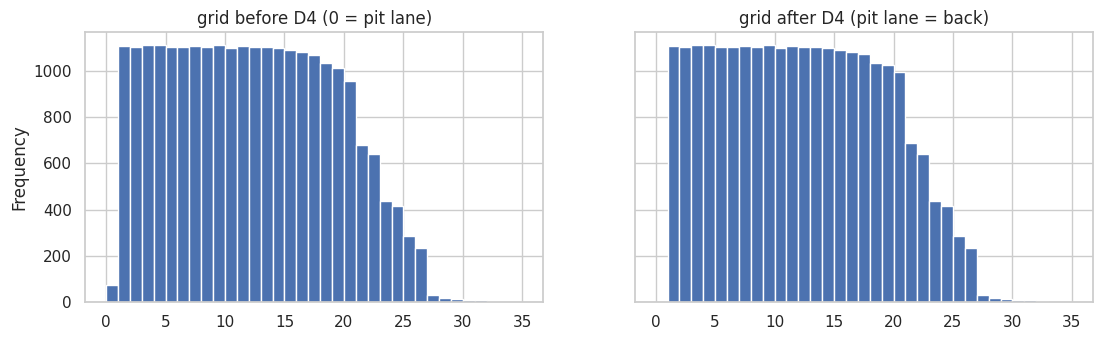

In [187]:
r_ = clean['results']

# Data repair: a few starters have no grid value at all (\N). Grid and qualifying position are almost
# identical (section 6.2), so we fill from qualifying and flag it; rows with neither are dropped.
missing_grid = r_['grid'].isna()
print('Starters with missing grid:', int(missing_grid.sum()))
if missing_grid.any():
    qpos = r_[['raceId', 'driverId']].merge(clean['qualifying'][['raceId', 'driverId', 'position']],
                                           on=['raceId', 'driverId'], how='left')['position'].values
    r_['grid_filled_from_quali'] = (missing_grid & pd.notna(qpos)).astype(int)
    r_.loc[missing_grid, 'grid'] = pd.array(qpos, dtype='Int64')[missing_grid.values]
    still = r_['grid'].isna()
    print('  filled from qualifying:', int(r_['grid_filled_from_quali'].sum()), '| dropped (no grid, no qualifying):', int(still.sum()))
    r_ = r_[~still].copy()
else:
    r_['grid_filled_from_quali'] = 0

assert not ((r_['grid'] == 0) & (r_['laps'] == 0)).any(), 'non-starter left in results'

back_of_grid = r_['grid'].where(r_['grid'] > 0).groupby(r_['raceId']).transform('max').fillna(0) + 1
r_['grid_raw'] = r_['grid']
r_['pit_lane_start'] = (r_['grid'] == 0).astype(int)
r_['grid'] = np.where(r_['grid'] == 0, back_of_grid, r_['grid']).astype(int)
clean['results'] = r_
print('Pit-lane starts recoded:', int(r_['pit_lane_start'].sum()))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
r_['grid_raw'].astype(float).plot(kind='hist', bins=range(0, 36), ax=axes[0], title='grid before D4 (0 = pit lane)')
r_['grid'].astype(float).plot(kind='hist', bins=range(0, 36), ax=axes[1], title='grid after D4 (pit lane = back)')
plt.show()

### 5.11 D6: keep privateers

No column identifies a privateer: `constructorId` records the **chassis maker**, not the entrant. Any proxy (cars per team, career starts) would either remove real works entries or use future races. The plot in 4.4 shows multi-car customer entries are concentrated in early decades. Because the model trains on every season (D7), the feature part adds field size (starters per race) so the model can tell a 30-car field from a 20-car one. For Q2, one-off home entries are noted as a confounder.

### 5.12 D7: the model uses every season (TA)

**Decision (TA):** the model is trained on all seasons from 1950, not only the years with qualifying data. The cell below measures what that means: how many starter rows have a qualifying record in each period.

In [188]:
q_keys = clean['qualifying'][['raceId', 'driverId']].drop_duplicates().assign(has_quali=True)
cov_d7 = (clean['results'].merge(clean['races'][['raceId', 'year']], on='raceId')
          .merge(q_keys, on=['raceId', 'driverId'], how='left'))
cov_d7['has_quali'] = cov_d7['has_quali'].notna()
cov_d7['period'] = pd.cut(cov_d7['year'], [1949, 1993, 2002, 3000], labels=['1950-1993', '1994-2002', '2003 onward'])
cov_d7.groupby('period', observed=True).agg(starter_rows=('has_quali', 'size'),
                                            share_with_qualifying=('has_quali', 'mean')).round(3)

,starter_rows,share_with_qualifying
period,,
1950-1993,12326,0.000
1994-2002,3328,0.463
2003 onward,8934,0.998


> **Interpretation:** about half of all starter rows (1950–1993) have **no qualifying data**, and 1994–2002 is only partly covered. Leaving these features empty would hurt the model (Piazza). The feature part therefore:
> 1. fills qualifying position with `grid` where it is missing (they correlate 0.97, section 6.2) and adds a `has_quali` flag;
> 2. fills the missing qualifying gap inside the model pipeline, fitted on training seasons only; four strategies are compared on validation PR-AUC in 13.3 (the median gap of drivers who qualified in the same position wins);
> 3. adds era and field-size features, so the model can learn that retirements and field sizes differ by decade;
> 4. uses championship rank, not raw points, because the points system changed (a win was 8 points in the 1950s, 10 in 2008, 25 from 2010).

### 5.13 D8: sprint results are not features

In 2021–2022 the sprint result already set the Sunday grid, so it is inside `grid`. From 2023 sprints happen at only a few races, so the feature would be mostly missing. `sprint_results` is cleaned and audited but not used as a feature. We keep a sprint-weekend flag for the penalty analysis in the feature part.

In [189]:
sprint_race_ids = set(clean['sprint_results']['raceId'])
clean['races']['is_sprint_weekend'] = clean['races']['raceId'].isin(sprint_race_ids)
clean['races'].groupby('year')['is_sprint_weekend'].sum().loc[2019:].rename('sprint weekends').to_frame().T

year,2019,2020,2021,2022,2023,2024
sprint weekends,0,0,3,3,6,6


### 5.14 D10: standings before a season opener

**Decision recorded here, applied in the feature part:** standings are snapshots *after* each race, so features use the previous race's standings within the same season. Before round 1 every driver and constructor gets **0 points**, and an `is_season_opener` flag tells the model that the standings carry no information yet.

### 5.15 D11: constructor renames — accept the reset

**Team decision:** renamed teams are **not** merged and `constructorId` is used as it is. Brawn (2009) and Mercedes (2010) stay separate, so team history restarts at a rename. The newcomer guide recommends exactly this: "a constructor form feature must follow constructorId, and we should accept that renames reset history."

**One trap to handle in the feature part:** a few IDs come back after decades (evidence below). If a form feature looked back "the last 5 races of this constructorId", Mercedes' first race in 2010 would reach back to 1955. **Rule for the feature part:** team-form features only look back within a limited time window (the current and previous season), so a gap of years automatically leaves the history empty, without changing any IDs.

In [190]:
# Evidence: constructorIds that reappear after a gap of 5+ seasons
cy = (clean['results'].merge(clean['races'][['raceId', 'year']], on='raceId')
      .merge(clean['constructors'][['constructorId', 'constructorRef']], on='constructorId')
      [['constructorRef', 'year']].drop_duplicates().sort_values(['constructorRef', 'year']))
cy['gap'] = cy.groupby('constructorRef')['year'].diff()
reused = cy[cy['gap'] >= 5].rename(columns={'year': 'returns_in', 'gap': 'seasons_absent'})
reused[['constructorRef', 'returns_in', 'seasons_absent']].reset_index(drop=True)

,constructorRef,returns_in,seasons_absent
0,alfa,1963,12.0
1,alfa,1979,14.0
2,alfa,2019,34.0
3,arrows,1997,7.0
4,aston_martin,2021,61.0
5,ats,1978,15.0
6,brabham,1970,7.0
7,brabham-ford,1976,7.0
8,brm,1956,5.0
9,emeryson,1962,6.0


### 5.16 D13: home-race mapping rules

Q2 compares driver **nationality** (`British`) with **circuit country** (`UK`). Rules:
1. Use `circuits.country`, never the race name (San Marino GP at Imola is in Italy; Luxembourg GP at the Nürburgring is in Germany).
2. Normalise circuit countries first: `United States` → `USA`.
3. Nationality means `drivers.nationality` only, not where a driver lives (living in Monaco does not make Monaco a home race).
4. Double nationalities (`American-Italian`) map to the **first** listed country, the one the driver raced under.
5. Nationalities whose country never hosted a race in the data map to `None` (no home race possible). Historical names follow today's map (`East German` → Germany, `Rhodesian` → None).
6. Every nationality in the data must be mapped or explicitly `None`. The check stops the notebook otherwise.
7. Drivers whose `home_country` is `None` are **left out of Q2**: they can never race at home, so they would only add to the away side.

In [191]:
COUNTRY_FIXES = {'United States': 'USA'}
clean['circuits']['country'] = clean['circuits']['country'].replace(COUNTRY_FIXES)

NATIONALITY_TO_COUNTRY = {
    'American': 'USA', 'American-Italian': 'USA', 'Argentine': 'Argentina', 'Argentinian': 'Argentina',
    'Argentine-Italian': 'Argentina', 'Australian': 'Australia', 'Austrian': 'Austria',
    'Belgian': 'Belgium', 'Brazilian': 'Brazil', 'British': 'UK', 'Canadian': 'Canada',
    'Chinese': 'China', 'Dutch': 'Netherlands', 'East German': 'Germany', 'French': 'France',
    'German': 'Germany', 'Hungarian': 'Hungary', 'Indian': 'India', 'Italian': 'Italy',
    'Japanese': 'Japan', 'Malaysian': 'Malaysia', 'Mexican': 'Mexico', 'Monegasque': 'Monaco',
    'Portuguese': 'Portugal', 'Russian': 'Russia', 'South African': 'South Africa',
    'Spanish': 'Spain', 'Swedish': 'Sweden', 'Swiss': 'Switzerland',
    # no home Grand Prix in the data
    'Chilean': None, 'Colombian': None, 'Czech': None, 'Danish': None, 'Finnish': None,
    'Indonesian': None, 'Irish': None, 'Liechtensteiner': None, 'New Zealander': None,
    'Polish': None, 'Rhodesian': None, 'Thai': None, 'Uruguayan': None, 'Venezuelan': None,
}

nats = set(clean['drivers']['nationality'].dropna())
unmapped = nats - set(NATIONALITY_TO_COUNTRY)
assert not unmapped, f'Unmapped nationalities: {unmapped}'
mapped_countries = {c for c in NATIONALITY_TO_COUNTRY.values() if c}
missing_country = mapped_countries - set(clean['circuits']['country'])
assert not missing_country, f'Mapped to a country with no circuit: {missing_country}'

clean['drivers']['home_country'] = clean['drivers']['nationality'].map(NATIONALITY_TO_COUNTRY)
print('Drivers with no recorded nationality:', int(clean['drivers']['nationality'].isna().sum()))
print('Drivers with no possible home race:',
      int((clean['drivers']['nationality'].notna() & clean['drivers']['home_country'].isna()).sum()))

# Effect: home-race rows among starters (Q2 tests whether these podium more often)
home_chk = (clean['results'].merge(clean['drivers'][['driverId', 'home_country']], on='driverId')
            .merge(clean['races'][['raceId', 'circuitId']], on='raceId')
            .merge(clean['circuits'][['circuitId', 'country']], on='circuitId'))
home_chk['is_home'] = home_chk['home_country'] == home_chk['country']
print('Starter rows at a home circuit:', int(home_chk['is_home'].sum()), f"({home_chk['is_home'].mean():.1%})")

Drivers with no recorded nationality: 0
Drivers with no possible home race: 50
Starter rows at a home circuit: 1915 (7.8%)


### 5.17 D14: qualifying features

Not a cleaning step; the cleaned qualifying table already holds `q1_sec`, `q2_sec`, `q3_sec`. **Decision:** the model uses qualifying position plus the **gap to the fastest Q1 time (%)**, because Q1 is the only session every driver runs, in the same conditions. The gap to each driver's best of Q1/Q2/Q3 was tested as an alternative in 13.4 and was not clearly better, so D14 stands.

### 5.18 Impute or remove? (Lab 1, step 4)

Lab 1 gives two options for missing data: **impute** (fill with an estimate) or **remove** (drop the column or rows), depending on how much is missing and how important the column is. We apply the same reasoning to every column with missing values that matters for this project.

**One deliberate difference from Lab 1:** Lab 1 imputes on the whole dataframe *before* splitting (for example `Age` with the median). Here that would leak information: the median of a column over all seasons includes the validation and test seasons (2020+). Any imputation of a **feature** is therefore done in the feature part, fitted on the training seasons only.

In [192]:
MISSING_DECISIONS = {
    ('results', 'position'):        'keep, unused: target uses positionOrder (always filled)',
    ('results', 'time'):            'keep for EDA only: post-race, never a feature',
    ('results', 'milliseconds'):    'keep for EDA only: post-race, never a feature',
    ('results', 'fastestLap'):      'keep for EDA only: post-race, never a feature',
    ('results', 'rank'):            'keep for EDA only: post-race, never a feature',
    ('results', 'fastestLapTime'):  'keep for EDA only: post-race, never a feature',
    ('results', 'fastestLapSpeed'): 'keep for EDA only: post-race, never a feature',
    ('results', 'number'):          'keep: identifies the car for the D2 duplicate rule',
    ('qualifying', 'q1'):           'used as the Q1 gap feature; missing gaps filled in the model pipeline (13.3)',
    ('qualifying', 'q2'):           'not a feature: missing for everyone knocked out in Q1 (used only in the best-of-3 test, 13.4)',
    ('qualifying', 'q3'):           'not a feature: missing for everyone knocked out before Q3 (used only in the best-of-3 test, 13.4)',
    ('drivers', 'number'):          'drop as feature: permanent numbers only exist from 2014',
    ('drivers', 'code'):            'drop as feature: identifier, mostly missing for older drivers',
    ('drivers', 'nationality'):     'leave missing: driver cannot have a home race',
    ('circuits', 'alt'):            'not used as a feature',
}
miss_rows = []
for (t, col), decision in MISSING_DECISIONS.items():
    if col in clean[t].columns:
        miss_rows.append({'table': t, 'column': col,
                          'missing': int(clean[t][col].isna().sum()),
                          'pct_missing': round(100 * clean[t][col].isna().mean(), 1),
                          'decision': decision})
missing_decisions = pd.DataFrame(miss_rows).sort_values('pct_missing', ascending=False)
missing_decisions

,table,column,missing,pct_missing,decision
11,drivers,number,802,93.1,drop as feature: permanent numbers only exist ...
12,drivers,code,757,87.9,"drop as feature: identifier, mostly missing fo..."
1,results,time,17044,69.3,"keep for EDA only: post-race, never a feature"
2,results,milliseconds,17044,69.3,"keep for EDA only: post-race, never a feature"
5,results,fastestLapTime,16336,66.4,"keep for EDA only: post-race, never a feature"
6,results,fastestLapSpeed,16336,66.4,"keep for EDA only: post-race, never a feature"
3,results,fastestLap,16336,66.4,"keep for EDA only: post-race, never a feature"
4,results,rank,16099,65.5,"keep for EDA only: post-race, never a feature"
10,qualifying,q3,6865,65.4,not a feature: missing for everyone knocked ou...
9,qualifying,q2,4647,44.3,not a feature: missing for everyone knocked ou...


> **Reasoning, Lab 1 style:** Lab 1 dropped `Cabin` because 77% was missing and it was not important. `drivers.number` is the same case: mostly missing and meaningless as a predictor. Lab 1 filled `Age` because it was important and only ~20% missing. `q1` is closer to the Age case: it becomes the Q1 gap feature, and its missing values are filled experimentally (Piazza: test imputation vs dropping). Section 13.3 compares four strategies on validation PR-AUC (drop the feature, train median, train 95th percentile, median gap by qualifying position), all fitted on training seasons only. `q2`/`q3` are a special case: a missing value usually means the driver was knocked out, so they are not used as features.

### 5.19 Encoding plan (Lab 1, step 4d)

The choice depends on what kind of category each column is (Lab 1: **ordinal → label encoding**, **nominal → one-hot encoding**). Final encodings, as used in the feature part:

| Column | Type | Encoding used | Why |
|---|---|---|---|
| `constructorId` | nominal | **not used directly**; replaced by team-form features (standings, recent podium and reliability rates) | about 47 teams since 1994, and renames create new IDs (D11), so one-hot columns would not carry over to a renamed team |
| `circuitId` | nominal | **not used** | Q1 showed per-circuit samples are too small to trust |
| home race | binary | **not used** | Q2 found no home effect (p = 0.57) |
| `pit_lane_start`, `has_quali` and the other flags | binary | 0/1 | two values only |
| era (from `year`) | ordered in time | **`era_index`, one ordered number (0–8)** | one-hot would fail: under the time split the test era never appears in training, so its column would be all zeros there |
| `grid`, qualifying position | numeric (ordinal) | kept as numbers | order is meaningful: P1 < P2 |

### 5.20 Final data-quality checks (the gate)

One cell re-checks every rule the cleaned data must satisfy, grouped by the usual data-quality dimensions. **Hard rules** stop the notebook if they fail. **Known quirks** are counted and explained, not fixed, because they don't touch the target or any feature.

In [193]:
res_ = clean['results'].merge(clean['races'][['raceId', 'year', 'date']], on='raceId', how='left')
res_ = res_.merge(clean['drivers'][['driverId', 'dob', 'home_country', 'nationality']], on='driverId', how='left')
age = (res_['date'] - res_['dob']).dt.days / 365.25
winners = res_[res_['positionOrder'] == 1].groupby('raceId').size().reindex(res_['raceId'].unique(), fill_value=0)
podium_rows = res_[res_['positionOrder'] <= 3].groupby('raceId').size().reindex(res_['raceId'].unique(), fill_value=0)
real_grid = res_[res_['pit_lane_start'] == 0]

hard = {
    # uniqueness
    'one row per (raceId, driverId)':        int(res_.duplicated(['raceId', 'driverId']).sum()),
    'one driver per car':                    int(res_.dropna(subset=['number']).duplicated(['raceId', 'number', 'grid_raw']).sum()),
    'positionOrder unique within a race':    int(res_.duplicated(['raceId', 'positionOrder']).sum()),
    # completeness of the columns the target and features need
    'missing raceId/driverId/constructorId/grid/positionOrder/statusId':
        int(res_[['raceId', 'driverId', 'constructorId', 'grid', 'positionOrder', 'statusId']].isna().any(axis=1).sum()),
    # validity
    'grid < 1 (0 must be recoded)':          int((res_['grid'] < 1).sum()),
    'pit-lane start not behind the field':   int((res_['pit_lane_start'].eq(1) &
                                                  (res_['grid'] <= real_grid.groupby('raceId')['grid'].max().reindex(res_['raceId']).fillna(0).values)).sum()),
    'driver age outside 15-60':              int(((age < 15) | (age > 60)).sum()),
    'qualifying lap > 2x session median':    int(sum((clean['qualifying'][c] > 2 * clean['qualifying'].groupby('raceId')[c].transform('median')).sum()
                                                     for c in ['q1_sec', 'q2_sec', 'q3_sec'])),
    'status not mapped to a group':          int((clean['status']['status_base'] == 'UNMAPPED').sum()),
    'nationality not mapped':                int((res_['nationality'].notna() & ~res_['nationality'].isin(NATIONALITY_TO_COUNTRY)).sum()),
    # consistency of the target
    'races without exactly one winner':      int((winners != 1).sum()),
    'races without exactly three podium rows': int((podium_rows != 3).sum()),
    # scope and integrity
    'Indianapolis 500 rows left':            int(res_['raceId'].isin(indy_ids).sum()),
    'non-starters left':                     int(((res_['grid_raw'] == 0) & (res_['laps'] == 0)).sum()),
    'results rows whose race/driver/team is missing':
        int((~res_['raceId'].isin(clean['races']['raceId']) | ~res_['driverId'].isin(clean['drivers']['driverId'])
             | ~res_['constructorId'].isin(clean['constructors']['constructorId'])).sum()),
}
gate = pd.DataFrame({'failing_rows': hard})
gate['result'] = np.where(gate['failing_rows'] == 0, 'pass', 'FAIL')
display(gate)
assert (gate['failing_rows'] == 0).all(), 'A hard data-quality rule failed: see the table above'
print(f'All {len(gate)} hard rules pass.')

,failing_rows,result
"one row per (raceId, driverId)",0,pass
one driver per car,0,pass
positionOrder unique within a race,0,pass
missing raceId/driverId/constructorId/grid/positionOrder/statusId,0,pass
grid < 1 (0 must be recoded),0,pass
pit-lane start not behind the field,0,pass
driver age outside 15-60,0,pass
qualifying lap > 2x session median,0,pass
status not mapped to a group,0,pass
nationality not mapped,0,pass


All 15 hard rules pass.


In [194]:
# Known quirks: counted and explained, not fixed (they do not affect the target or any feature)
q_res = clean['qualifying'].merge(clean['results'][['raceId', 'driverId', 'constructorId']],
                                  on=['raceId', 'driverId'], suffixes=('', '_results'))
st_ = res_.merge(clean['status'][['statusId', 'status_base']], on='statusId', how='left', suffixes=('', '_s'))
quirks = {
    'position differs from positionOrder (post-race disqualification moved others up)':
        int((res_['position'].notna() & (res_['position'] != res_['positionOrder'])).sum()),
    'two drivers on the same original grid slot (source data)':
        int(real_grid.duplicated(['raceId', 'grid']).sum()),
    'team id differs between qualifying and results (2015 Marussia/Manor)':
        int((q_res['constructorId'] != q_res['constructorId_results']).sum()),
    "positionText 'R' but status '+N Laps'":
        int(((st_['positionText'] == 'R') & st_['status_base_s'].isin(['lapped'])).sum()),
    'races with no result rows (races listed in the file but not yet run)':
        int((~clean['races']['raceId'].isin(res_['raceId'])).sum()),
    'qualifying rows with no results row (driver did not start or was removed by D2/D3/D5)':
        int(len(clean['qualifying']) - len(q_res)),
}
pd.Series(quirks, name='rows').to_frame()

,rows
position differs from positionOrder (post-race disqualification moved others up),13
two drivers on the same original grid slot (source data),72
team id differs between qualifying and results (2015 Marussia/Manor),10
positionText 'R' but status '+N Laps',5
races with no result rows (races listed in the file but not yet run),0
qualifying rows with no results row (driver did not start or was removed by D2/D3/D5),41


> **How to read the quirks:**
> - *position ≠ positionOrder*: e.g. 1983 Brazilian GP, where 2nd place was disqualified. `position` was not updated but `positionOrder` was, which is exactly why the target uses `positionOrder`.
> - *Same original grid slot*: a source-data issue in some races. Harmless for the model; the pit-lane recode no longer adds to it.
> - *Team id mismatch*: in 2015 qualifying lists Marussia while results list Manor for the same team. Features join qualifying on `(raceId, driverId)` and take the team from `results`, so this never matters.
> - *'R' but '+N Laps'*: two columns disagree on a handful of rows; neither is a feature, and Q3 uses `status`.

## 6. EDA after cleaning
### 6.1 Impact of the cleaning (before vs after)

In [195]:
rows_cmp = pd.DataFrame({'rows_raw': {t: len(raw[t]) for t in TABLES},
                         'rows_clean': {t: len(clean[t]) for t in TABLES}})
rows_cmp['removed'] = rows_cmp['rows_raw'] - rows_cmp['rows_clean']
rows_cmp[rows_cmp['removed'] > 0]

,rows_raw,rows_clean,removed
constructor_results,12625,12604,21
constructor_standings,13391,13365,26
driver_standings,34863,34194,669
races,1125,1114,11
results,26759,24588,2171


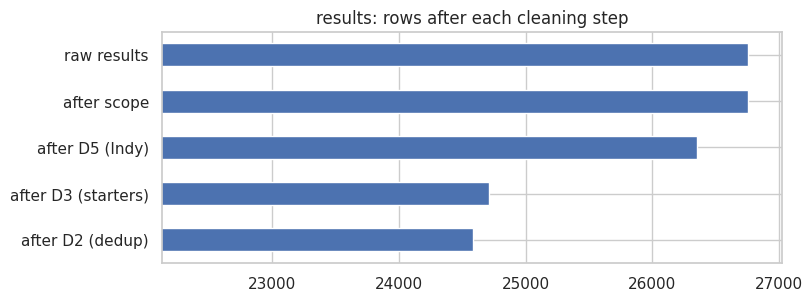

,rows
raw results,26759
after scope,26759
after D5 (Indy),26354
after D3 (starters),24708
after D2 (dedup),24588


In [196]:
# Step-by-step row flow of results (raw -> modeling base)
flow = pd.Series({
    'raw results': len(raw['results']),
    'after scope': len(raw['results']) - scope_log.get('results', 0),
    'after D5 (Indy)': len(clean['results_all']),
    'after D3 (starters)': int(clean['results_all']['is_starter'].sum()),
    'after D2 (dedup)': len(clean['results']),
})
flow.plot(kind='barh', figsize=(8, 3), title='results: rows after each cleaning step')
plt.gca().invert_yaxis(); plt.xlim(flow.min() * 0.9, flow.max() * 1.01)
plt.show()
flow.to_frame('rows')

In [197]:
clean_dtypes = pd.concat({t: df.dtypes.astype(str) for t, df in clean.items() if t in TABLES},
                         names=['table', 'column']).rename('clean_dtype').to_frame()
dtype_cmp = raw_dtypes.join(clean_dtypes, how='outer')
dtype_cmp[dtype_cmp['raw_dtype'] != dtype_cmp['clean_dtype']]

raw_dtype     clean_dtype
table          column                                          
drivers        dob                       object  datetime64[ns]
               home_country                 NaN          object
               number                    object           Int64
pit_stops      duration_sec                 NaN         float64
qualifying     q1_sec                       NaN         float64
               q2_sec                       NaN         float64
               q3_sec                       NaN         float64
races          date                      object  datetime64[ns]
               fp1_date                  object  datetime64[ns]
               fp2_date                  object  datetime64[ns]
               fp3_date                  object  datetime64[ns]
               is_sprint_weekend            NaN            bool
               quali_date                object  datetime64[ns]
               race_order                   NaN           int64
               sprint_date               object  datetime64[ns]
results        fastestLap                object           Int64
               fastestLapSpeed           object         float64
               fastestLapTime_sec           NaN         float64
               grid_filled_from_quali       NaN           int64
               grid_raw                     NaN           int64
               is_starter                   NaN            bool
               milliseconds              object           Int64
               number                    object           Int64
               pit_lane_start               NaN           int64
               position                  object           Int64
               rank                      object           Int64
               status                       NaN          object
               status_base                  NaN          object
sprint_results fastestLap                object           Int64
               milliseconds              object           Int64
               position                  object           Int64
status         is_mechanical                NaN            bool
               status_base                  NaN          object

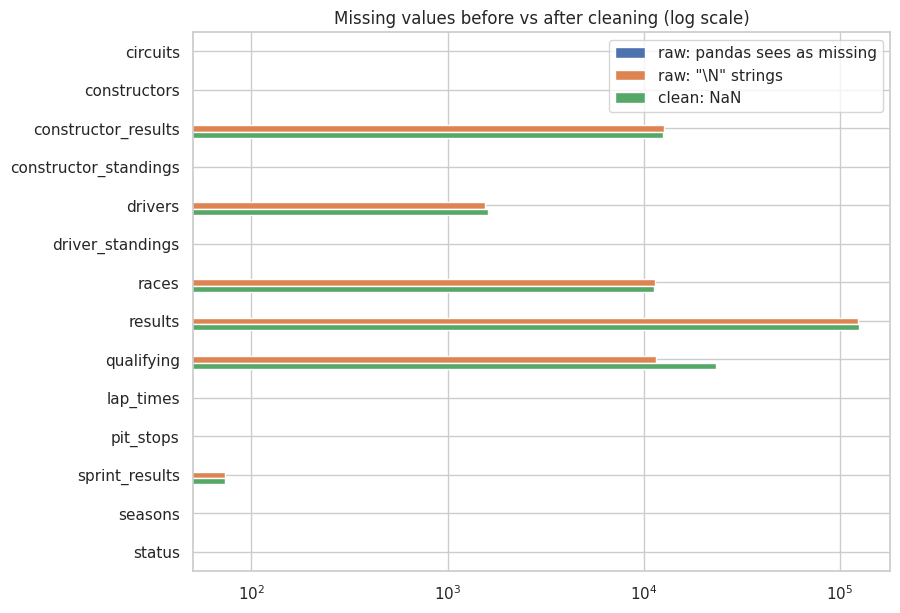

,raw: pandas sees as missing,"raw: ""\N"" strings",clean: NaN
circuits,0,0,0
constructors,0,0,0
constructor_results,0,12608,12587
constructor_standings,0,0,0
drivers,0,1559,1609
driver_standings,0,0,0
races,0,11349,11228
results,0,122887,124599
qualifying,0,11600,23337
lap_times,0,0,0


In [198]:
miss_cmp = pd.DataFrame({
    'raw: pandas sees as missing': {t: int(raw[t].isna().sum().sum()) for t in TABLES},
    r'raw: "\N" strings':          {t: int((raw[t].astype(str) == SENTINEL).sum().sum()) for t in TABLES},
    'clean: NaN':                  {t: int(clean[t].isna().sum().sum()) for t in TABLES},
})
miss_cmp.replace(0, np.nan).plot(kind='barh', figsize=(9, 7), logx=True)
plt.title('Missing values before vs after cleaning (log scale)')
plt.gca().invert_yaxis(); plt.show()
miss_cmp

In [199]:
pd.DataFrame({
    'dup_rows_raw':   {t: int(raw[t].duplicated(subset=['raceId', 'driverId']).sum()) for t in ['results', 'qualifying', 'sprint_results']},
    'dup_rows_clean': {t: int(clean[t].duplicated(subset=['raceId', 'driverId']).sum()) for t in ['results', 'qualifying', 'sprint_results']},
})

,dup_rows_raw,dup_rows_clean
results,91,0
qualifying,0,0
sprint_results,0,0


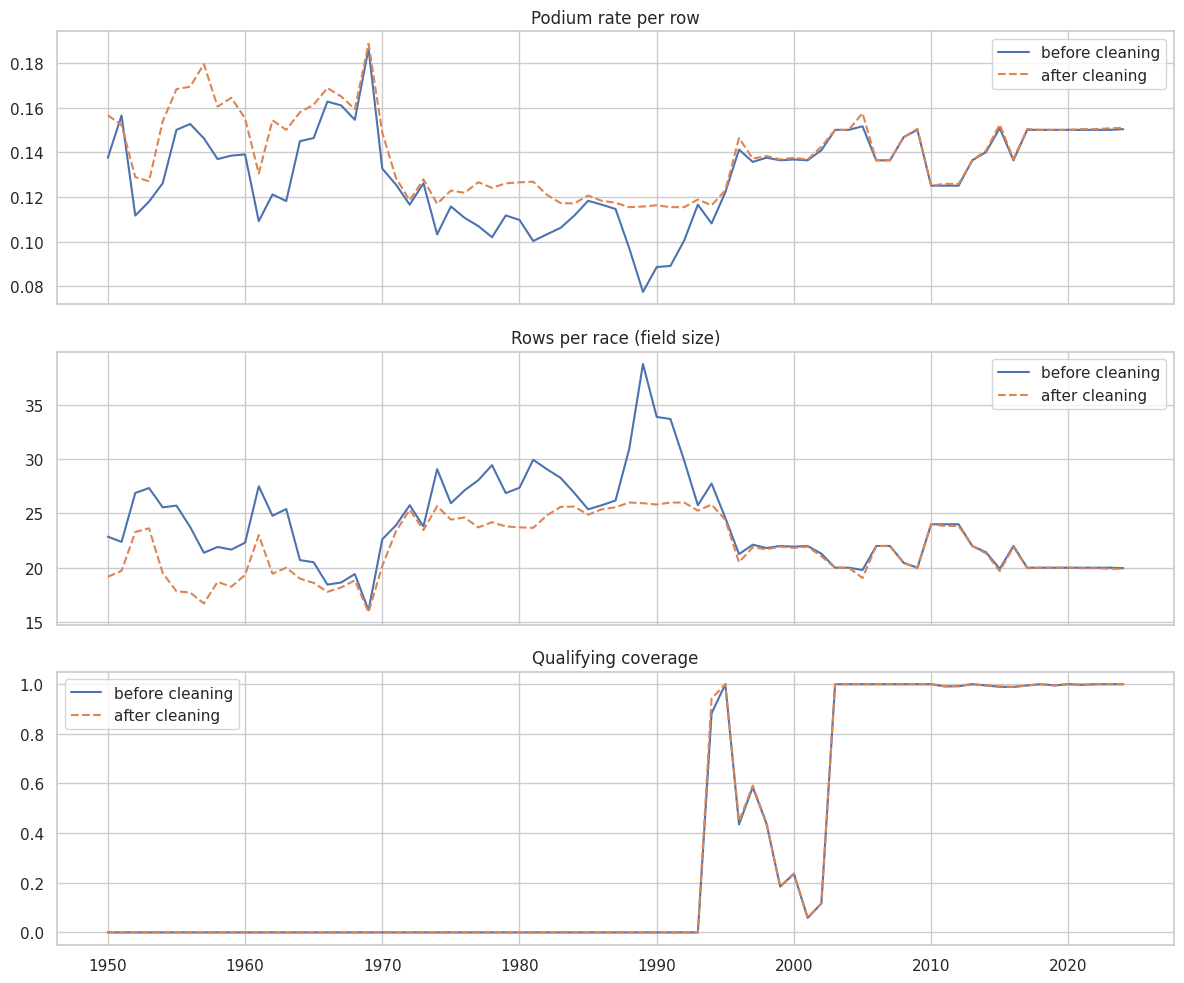

In [200]:
res_clean = clean['results'].merge(clean['races'][['raceId', 'year']], on='raceId')
before = res.assign(podium=res['po_num'] <= 3).groupby('year')['podium'].mean()
after = res_clean.assign(podium=res_clean['positionOrder'] <= 3).groupby('year')['podium'].mean()

field_before = res.groupby('year').size() / res.groupby('year')['raceId'].nunique()
field_after = res_clean.groupby('year').size() / res_clean.groupby('year')['raceId'].nunique()

cov2 = res_clean.merge(q_keys, on=['raceId', 'driverId'], how='left')
cov_after = cov2['has_quali'].fillna(0).groupby(cov2['year']).mean()

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, (b, a, title) in zip(axes, [(before, after, 'Podium rate per row'),
                                    (field_before, field_after, 'Rows per race (field size)'),
                                    (cov_before, cov_after, 'Qualifying coverage')]):
    ax.plot(b.index, b.values, label='before cleaning')
    ax.plot(a.index, a.values, label='after cleaning', ls='--')
    ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()

> **Interpretation:** removing non-starters (D3) shrinks fields in the 1950s–1990s and **raises** the podium rate per row there, because non-qualifiers could never podium. Qualifying coverage rises too, because non-starters rarely had qualifying rows. In 2003+ almost nothing changes: the cleaning mainly affects older eras.

### 6.2 Visual exploration of the cleaned data (Lab 1, step 5)

We first join the cleaned tables into one **modeling base**: one row per starter per race, with only information known **before the race** plus the target. Then we explore it with the four kinds of visualization from Lab 1:

1. **Distribution**: how values are spread (histograms, boxplots).
2. **Comparison**: differences between groups (bar plots).
3. **Relationship**: connections between variables (scatter, bubble, heatmaps).
4. **Composition**: parts of a whole (stacked percentages).

These plots are exploration, not features yet. They give the evidence that the feature part builds on.

In [201]:
ERAS = [(1950, 1957, '1950-57 front-engine'), (1958, 1965, '1958-65 rear-engine'),
        (1966, 1976, '1966-76 3-litre'), (1977, 1988, '1977-88 turbo'),
        (1989, 1994, '1989-94 post-turbo'), (1995, 2008, '1995-2008 V10/V8'),
        (2009, 2013, '2009-13 late V8'), (2014, 2021, '2014-21 hybrid'),
        (2022, 2025, '2022-25 ground effect'), (2026, 2100, '2026+ new rules')]
ERA_LABELS = [e[2] for e in ERAS]

def era_of(year):
    for lo, hi, label in ERAS:
        if lo <= year <= hi:
            return label
    return np.nan

base = (clean['results'][['resultId', 'raceId', 'driverId', 'constructorId',
                          'grid', 'pit_lane_start', 'positionOrder']]
        .merge(clean['races'][['raceId', 'year', 'round', 'circuitId', 'date', 'race_order',
                               'is_sprint_weekend']], on='raceId', how='left')
        .merge(clean['drivers'][['driverId', 'dob', 'home_country']], on='driverId', how='left')
        .merge(clean['circuits'][['circuitId', 'name', 'country']].rename(columns={'name': 'circuit'}),
               on='circuitId', how='left')
        .merge(clean['qualifying'][['raceId', 'driverId', 'position', 'q1_sec']]
               .rename(columns={'position': 'quali_position'}), on=['raceId', 'driverId'], how='left'))

base['podium'] = (base['positionOrder'] <= 3).astype(int)                 # target
base['driver_age'] = (base['date'] - base['dob']).dt.days / 365.25        # known before the race
base['is_home'] = (base['home_country'] == base['country']).astype(int)
base['era'] = pd.Categorical(base['year'].map(era_of), categories=ERA_LABELS, ordered=True)
base['grid_group'] = pd.cut(base['grid'].astype(float), bins=[0, 1, 2, 3, 5, 10, 15, 100],
                            labels=['P1', 'P2', 'P3', 'P4-5', 'P6-10', 'P11-15', 'P16+'])
base['is_sprint_weekend'] = base['is_sprint_weekend'].astype(int)
base['has_quali'] = base['quali_position'].notna().astype(int)

assert not base.duplicated(['raceId', 'driverId']).any(), 'grain broken'
assert base['era'].notna().all()
clean['model_base'] = base
print('model base:', base.shape, '| podium rate:', round(base['podium'].mean(), 3))
base.head()

model base: (24588, 25) | podium rate: 0.136


,resultId,raceId,driverId,constructorId,grid,pit_lane_start,positionOrder,year,round,circuitId,date,race_order,is_sprint_weekend,dob,home_country,circuit,country,quali_position,q1_sec,podium,driver_age,is_home,era,grid_group,has_quali
0,1,18,1,1,1,0,1,2008,1,1,2008-03-16,786,0,1985-01-07,UK,Albert Park Grand Prix Circuit,Australia,1.0,86.572,1,23.186858,0,1995-2008 V10/V8,P1,1
1,2,18,2,2,5,0,2,2008,1,1,2008-03-16,786,0,1977-05-10,Germany,Albert Park Grand Prix Circuit,Australia,5.0,85.960,1,30.850103,0,1995-2008 V10/V8,P4-5,1
2,3,18,3,3,7,0,3,2008,1,1,2008-03-16,786,0,1985-06-27,Germany,Albert Park Grand Prix Circuit,Australia,7.0,86.295,1,22.718686,0,1995-2008 V10/V8,P6-10,1
3,4,18,4,4,11,0,4,2008,1,1,2008-03-16,786,0,1981-07-29,Spain,Albert Park Grand Prix Circuit,Australia,12.0,86.907,0,26.631075,0,1995-2008 V10/V8,P11-15,1
4,5,18,5,1,3,0,5,2008,1,1,2008-03-16,786,0,1981-10-19,None,Albert Park Grand Prix Circuit,Australia,3.0,85.664,0,26.406571,0,1995-2008 V10/V8,P3,1


#### Distribution 1: histogram of starting grid position

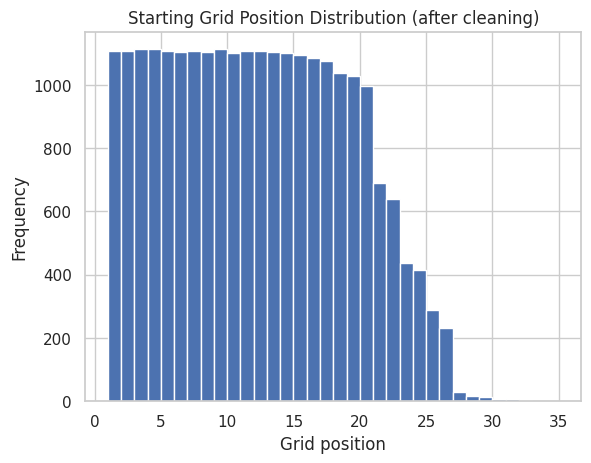

In [202]:
plt.hist(base['grid'].astype(float), bins=range(1, 36))
plt.title('Starting Grid Position Distribution (after cleaning)')
plt.xlabel('Grid position')
plt.ylabel('Frequency')
plt.show()

> Each grid slot from P1 to about P20 appears once per race, so the bars are roughly flat until field size starts to vary. Slots beyond P26 only exist in eras with oversized fields. There is no bar at 0 any more: pit-lane starts were moved to the back of the grid by D4.

#### Distribution 2: driver age, podium finishers vs the rest

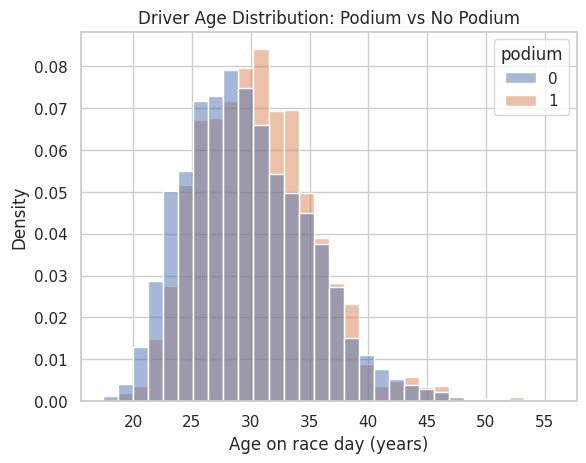

In [203]:
sns.histplot(data=base, x='driver_age', hue='podium', bins=30, stat='density', common_norm=False)
plt.title('Driver Age Distribution: Podium vs No Podium')
plt.xlabel('Age on race day (years)')
plt.ylabel('Density')
plt.show()

> Comparing two distributions works like the survivors vs non-survivors task in Lab 1. `common_norm=False` scales each group separately, so the much smaller podium group is still visible. The two shapes overlap heavily; podium finishers are only slightly older on average (fewer under 24, more around 30-35). Age is at most a weak feature, which the correlation table below confirms.

#### Distribution 3: boxplot to spot outliers in pit-stop duration

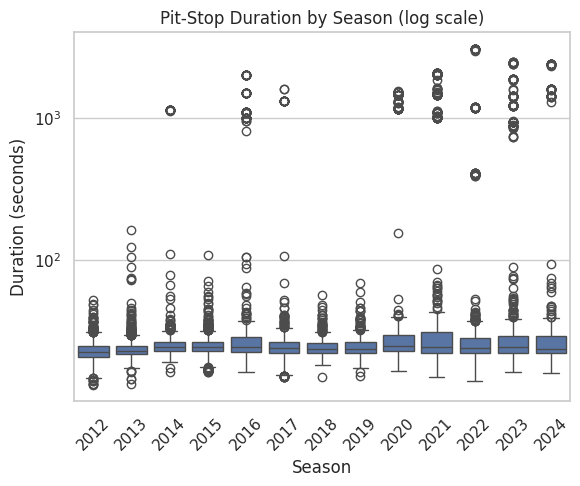

Stops longer than 120 s: 480


In [204]:
ps = clean['pit_stops'].merge(clean['races'][['raceId', 'year']], on='raceId')
ps = ps[ps['year'] >= 2012]
sns.boxplot(x='year', y='duration_sec', data=ps)
plt.yscale('log')
plt.title('Pit-Stop Duration by Season (log scale)')
plt.xlabel('Season'); plt.ylabel('Duration (seconds)')
plt.xticks(rotation=45)
plt.show()
print('Stops longer than 120 s:', int((ps['duration_sec'] > 120).sum()))

> The extreme points (minutes, not seconds) are red-flag stoppages, where cars wait in the pit lane. They are real events, not errors, so they are **not removed**. Pit stops are post-race data and are never features; this plot only documents the outliers found in 4.2.

#### Comparison 1: podium rate by grid group

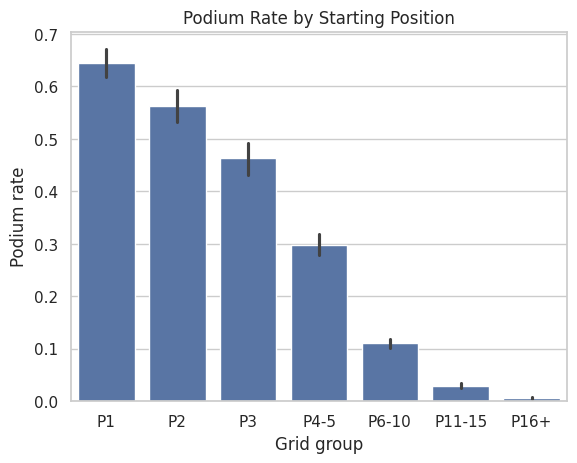

In [205]:
sns.barplot(data=base, x='grid_group', y='podium')
plt.title('Podium Rate by Starting Position')
plt.xlabel('Grid group')
plt.ylabel('Podium rate')
plt.show()

> This is the F1 version of Lab 1's *survival rate by age group*. Podium rate falls steeply with grid position, which is the evidence for using `grid` as the main feature. The error bars are 95% confidence intervals; they are wide only where a group is small.

#### Comparison 2: home vs away, inside each grid group (preview of Q2)

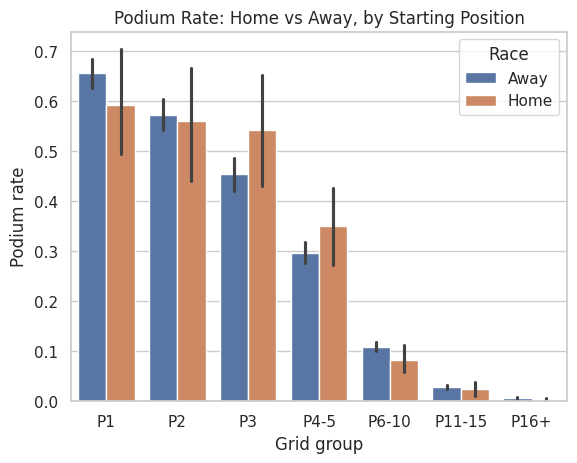

In [206]:
hv = base[base['home_country'].notna()].assign(race_type=lambda d: d['is_home'].map({0: 'Away', 1: 'Home'}))
sns.barplot(data=hv, x='grid_group', y='podium', hue='race_type', hue_order=['Away', 'Home'])
plt.title('Podium Rate: Home vs Away, by Starting Position')
plt.xlabel('Grid group'); plt.ylabel('Podium rate')
plt.legend(title='Race')
plt.show()

> Comparing home and away **within the same grid group** is what Q2 means by "controlling for starting position". Drivers whose nationality has no Grand Prix are excluded, because they could never race at home. The home bars have much wider error bars (far fewer home races) and do not sit consistently above the away bars, so any home effect is small at best. The full answer, with a statistical test, is in the Q2 section.

#### Relationship 1: scatter plot of qualifying position vs grid

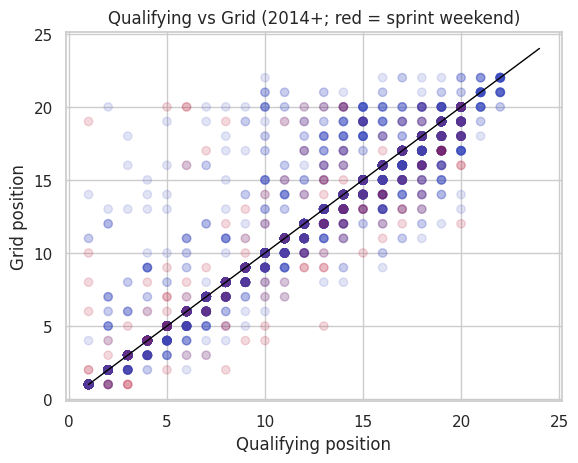

Rows where grid != qualifying position: 31.1%


In [207]:
s = base[(base['year'] >= 2014) & base['quali_position'].notna()]
plt.scatter(s['quali_position'], s['grid'], alpha=0.15, c=s['is_sprint_weekend'], cmap='coolwarm')
plt.plot([1, 24], [1, 24], color='black', lw=1)
plt.xlabel('Qualifying position'); plt.ylabel('Grid position')
plt.title('Qualifying vs Grid (2014+; red = sprint weekend)')
plt.show()
print('Rows where grid != qualifying position:', f"{(s['grid'] != s['quali_position']).mean():.1%}")

> Points on the diagonal started where they qualified. Points **above** it started further back (penalties or pit-lane starts); points slightly **below** it moved up because someone ahead was penalised. Sprint weekends in 2021-22 sit off the diagonal for a different reason: the sprint set the grid. This is why qualifying position and grid are kept as separate columns.

#### Relationship 2: bubble chart of constructor seasons (2014-2024)

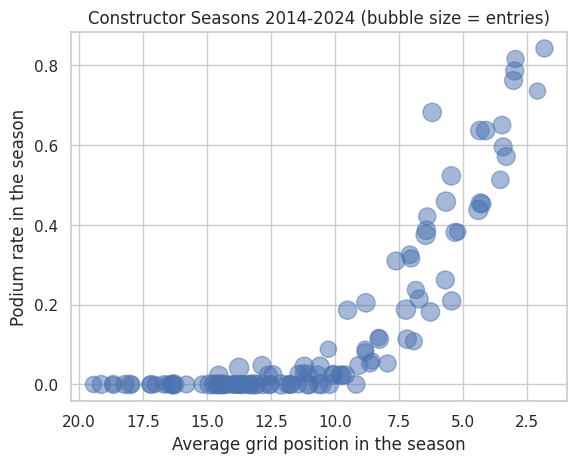

In [208]:
cs = (base[base['year'] >= 2014]
      .groupby(['year', 'constructorId'])
      .agg(mean_grid=('grid', 'mean'), podium_rate=('podium', 'mean'), entries=('podium', 'size'))
      .reset_index())
plt.scatter(cs['mean_grid'], cs['podium_rate'], s=cs['entries'] * 4, alpha=0.5)
plt.xlabel('Average grid position in the season')
plt.ylabel('Podium rate in the season')
plt.title('Constructor Seasons 2014-2024 (bubble size = entries)')
plt.gca().invert_xaxis()
plt.show()

> Each bubble is one team in one season. The steep curve shows that team pace (average grid) and podiums move together: teams that start at the front collect almost all podiums. This supports constructor-form features. Similar bubble sizes show every team enters about two cars per race in this era.

#### Relationship 3: pivot-table heatmap of podium rate by era and grid group

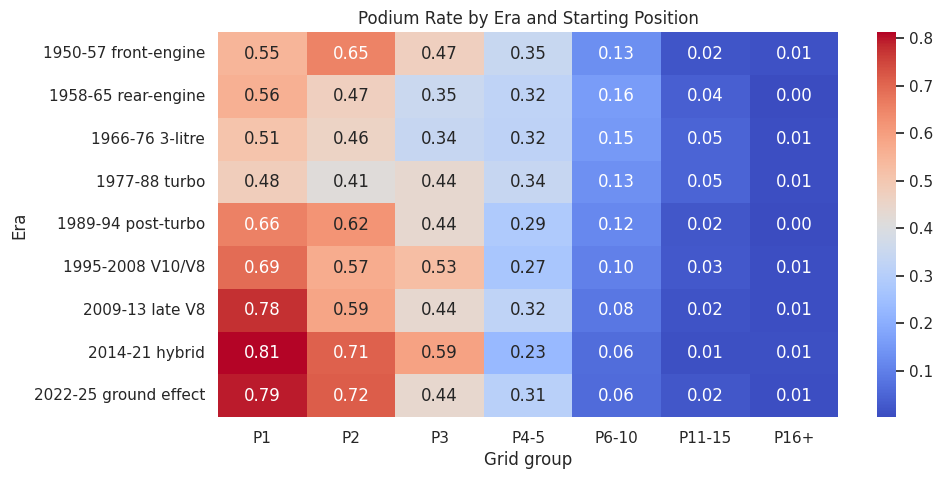

In [209]:
pivot = pd.pivot_table(base, index='era', columns='grid_group', values='podium',
                       aggfunc='mean', observed=False)
plt.figure(figsize=(10, 5))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Podium Rate by Era and Starting Position')
plt.xlabel('Grid group'); plt.ylabel('Era')
plt.show()

> As in Lab 1's Sex x Pclass pivot, each cell is a mean of the target for one combination. Reading down a column shows whether the same grid slot converts to a podium more often in some eras than others, which is the era sensitivity the brief asks us to report. Early eras convert less reliably because retirement rates were much higher.

#### Relationship 4: correlation heatmap of pre-race numeric columns, ranked by correlation with podium

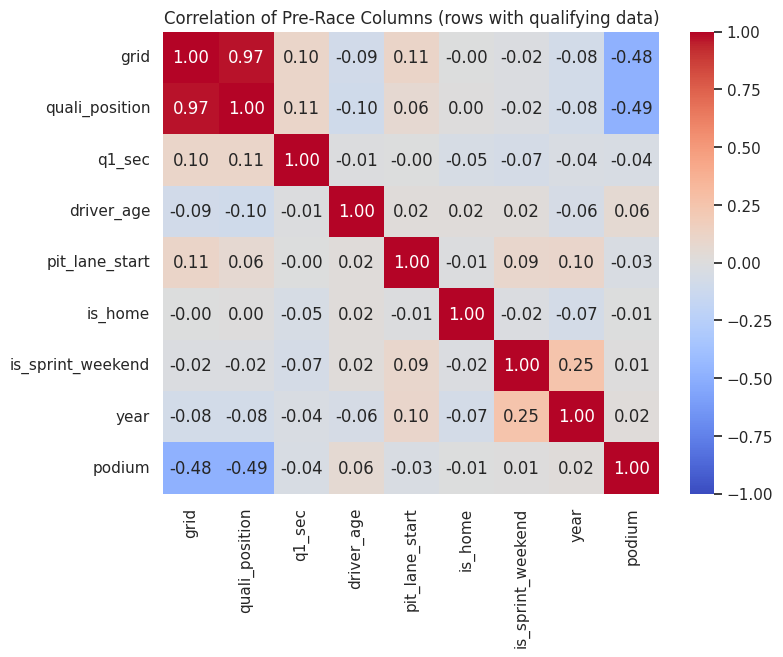

,corr with podium
quali_position,-0.487739
grid,-0.484995
driver_age,0.059040
q1_sec,-0.039079
pit_lane_start,-0.033612
year,0.017652
is_home,-0.007396
is_sprint_weekend,0.005333


In [210]:
num_cols = ['grid', 'quali_position', 'q1_sec', 'driver_age', 'pit_lane_start',
            'is_home', 'is_sprint_weekend', 'year', 'podium']
corr = base[base['has_quali'] == 1][num_cols].astype(float).corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation of Pre-Race Columns (rows with qualifying data)')
plt.show()
corr['podium'].drop('podium').sort_values(key=abs, ascending=False).rename('corr with podium').to_frame()

> Grid and qualifying position have the strongest (negative) correlation with podium: a lower number means a better start. They also correlate **0.97 with each other**, so they carry almost the same information; the ablation will show whether keeping both helps. `q1_sec` is close to zero because raw lap times depend on the circuit, so they cannot be compared across races. This is the evidence for D14: lap times must be turned into a gap to the fastest driver **in the same race** before they are useful. Correlation only measures linear association and does not mean cause.

#### Composition 1: share of each grid group among podium and non-podium finishers

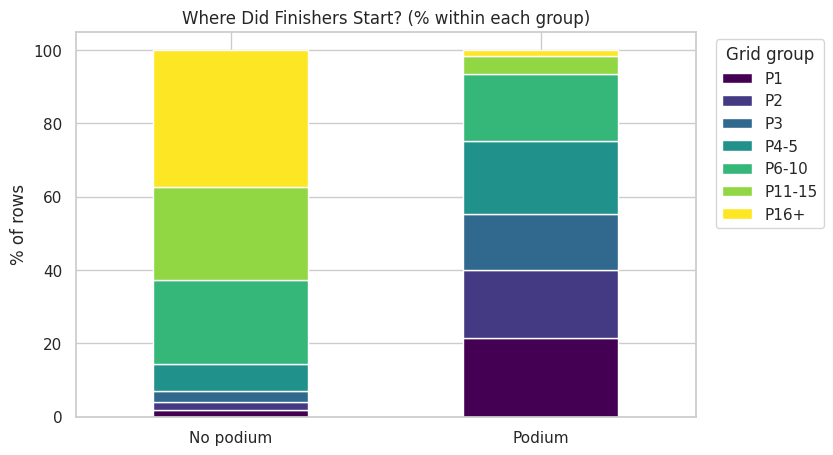

,No podium,Podium
grid_group,,
P1,1.9,21.4
P2,2.3,18.6
P3,2.8,15.4
P4-5,7.3,19.8
P6-10,23.2,18.3
P11-15,25.2,4.8
P16+,37.4,1.6


In [211]:
comp = pd.crosstab(base['grid_group'], base['podium'], normalize='columns') * 100
comp.columns = ['No podium', 'Podium']
comp.T.plot(kind='bar', stacked=True, figsize=(8, 5), colormap='viridis')
plt.title('Where Did Finishers Start? (% within each group)')
plt.ylabel('% of rows'); plt.xticks(rotation=0)
plt.legend(title='Grid group', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()
comp.round(1)

> Like the Pclass-within-survivors task in Lab 1, each bar adds to 100%. About three quarters of podium finishers started in the top five, and almost none from P16 or lower. Non-podium finishers are spread across the whole field.

#### Composition 2: how races ended, by decade (post-race, EDA only)

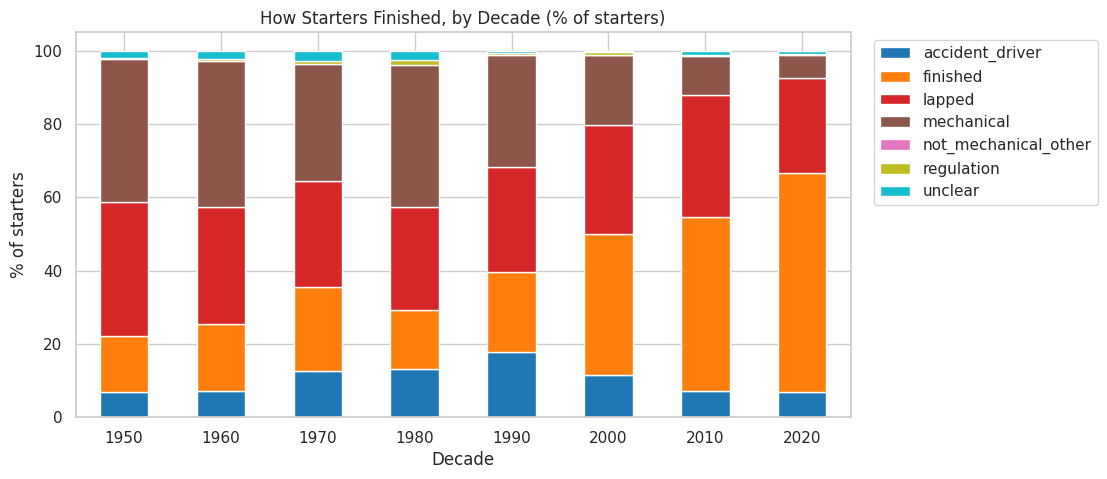

In [212]:
end = clean['results'].merge(clean['races'][['raceId', 'year']], on='raceId')
end['decade'] = (end['year'] // 10) * 10
end_comp = pd.crosstab(end['decade'], end['status_base'], normalize='index') * 100
end_comp.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='tab10')
plt.title('How Starters Finished, by Decade (% of starters)')
plt.ylabel('% of starters'); plt.xlabel('Decade'); plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

> Mechanical failures and accidents shrink decade by decade, while finishing on the lead lap grows. A good grid slot converted to a podium less reliably in early eras, which matches the era heatmap above. Status is post-race, so this is context for Q3 and the limitations section, never a feature.

## 7. Save cleaned tables
`raw` CSVs stay untouched; cleaned copies go to the working directory for the next parts.

In [213]:
OUT_DIR = '/kaggle/working/clean' if os.path.isdir('/kaggle/working') else 'clean'
os.makedirs(OUT_DIR, exist_ok=True)
for t, df in clean.items():
    df.to_pickle(os.path.join(OUT_DIR, f'{t}.pkl'))     # pickle keeps dtypes (datetime, Int64)
print('Saved', len(clean), 'tables to', OUT_DIR)

Saved 19 tables to /kaggle/working/clean


## 8. Summary of cleaning decisions

| # | Issue | Evidence | Decision | Why |
|---|---|---|---|---|
| 1 | `\N` sentinels | 4.1, 5.1 | Replaced with NaN | Only placeholder; NaN count matches sentinel count |
| 2 | Other placeholders / whitespace | 4.2 | Stripped whitespace; letter codes kept | Trailing spaces break mappings; letters are categories |
| 3 | Text columns that are numbers / dates / times | 5.2 | Converted; times → seconds with unit-tested parser | Needed for arithmetic and chronology |
| 4 | PK nulls / duplicates; schema constraints | 5.3 | Tested every PK, UNIQUE, NOT NULL | D1: schema as audit spec |
| 5 | FK orphans | 5.4 | None found; no rows dropped | Joins are safe |
| 6 | `raceId` not chronological | 5.5 | `race_order` from (year, round) | Prevents leakage in form features |
| 7 | Indianapolis 500 | 5.6 | Excluded from all tables (D5) | Distorts counts, Q2, grid structure |
| 8 | Non-starters | 4.4, 5.8 | Dropped from modeling base, kept in `results_all` (D3) | No grid slot at cutoff |
| 9 | Shared drives | 5.9 | Car = (race, number, grid); one driver per car (the finisher), one row per driver; row keeps the car's grid (D2, TA) | Each row is one car and one prediction; every shared race keeps 3 podium rows |
| 10 | `grid == 0` | 4.4, 5.10 | Pit-lane start → back of grid + flag (D4) | 0 must not read as better than pole |
| 11 | Privateers | 4.4, 5.11 | Kept (D6) | No identifier in the data; field size added as a feature |
| 12 | Training window | 4.4, 5.12 | All seasons from 1950 (D7, TA); missing qualifying handled in features | TA instruction; coverage measured |
| 13 | Sprint results | 5.13 | Not features; weekend flag kept (D8) | Inside grid 2021–22; sparse after |
| 14 | Constructor renames | 5.15 | Accept the reset; form features look back over the current and previous season only (D11) | Guide recommends it; avoids linking 1955 to 2010 |
| 15 | Nationality vs country | 4.4, 5.16 | Mapping + `USA` normalisation (D13) | Q2 needs exact matches |
| 15b | Impossible lap times | 5.2.3 | Set to NaN if > 2× session median; real outliers kept | Invalid ≠ outlier |
| 15c | Final quality gate | 5.20 | 15 hard rules asserted; quirks counted and explained | One place that proves the data is clean |
| 16 | Missing values per column | 5.18 | Impute / remove / keep, per column; feature imputation after the split | Lab 1 rule, adapted to avoid leakage |
| 17 | Mechanical mapping | 5.7 | Component failure = mechanical; unclear = not (D9) | Brief note, guide, Piazza |
| 18 | Qualifying features (D14) | 5.17, 13.4 | % gap to the fastest Q1 time | Q1 is the only session all drivers run; best-of-3 tested, not better |

**Known limitations noted during cleaning**
- No qualifying data before 1994 and patchy data until 2003, while the model trains on every season.
- In shared-drive races (before 1965), `grid` is the car's starting slot, which can differ from where the kept driver himself started. A few non-podium cars and drivers who only drove someone else's car are dropped (counts in 5.9).
- `Retired` and other unclear statuses give no cause; they are counted as not mechanical, so Q3 may slightly undercount mechanical failures.
- Renames reset team history, so a renamed team's first races have no form history.
- One nationality per driver; dual-heritage drivers follow the recorded one.

## 9. Data-engineering questions

All three answers use the **cleaned** tables from sections 5–6: Indy 500 removed (D5), non-starters removed (D3), one row per driver per race (D2), pit-lane starts recoded (D4). Every answer is backed by a table, a plot and a statistic.

In [214]:
from scipy.stats import spearmanr
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import StratifiedTable

def wilson_ci(successes, n, z=1.96):
    # 95% Wilson interval for a proportion: stays sensible for small n (unlike +-1.96*SE)
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

### 9.1 Q1: Which circuits turn a front-row start into a podium most often, and does the ranking change from 2014?

**Definitions**
- **Front row** = starting **grid** position 1 or 2. The brief warns that qualifying position and grid differ (penalties); the instructors confirmed on Piazza that this question is about the **grid**, the place the car actually started.
- **Conversion** = podiums ÷ front-row starts, per circuit.
- **Periods (D12):** before 2014 vs 2014 onward (the hybrid era starts in 2014).
- **Minimum sample:** a circuit is ranked in a period only with **at least 10 front-row starts** in that period (5 races). With fewer, one lucky race moves the rate by 10+ points.

**Tables joined:** `results` (grid, positionOrder) → `races` (year, circuitId) → `circuits` (name).

In [215]:
MIN_FRONT_ROW_STARTS = 10

fr = (clean['results'][['raceId', 'driverId', 'grid', 'positionOrder']]
      .merge(clean['races'][['raceId', 'year', 'circuitId']], on='raceId')
      .merge(clean['circuits'][['circuitId', 'name']].rename(columns={'name': 'circuit'}), on='circuitId'))
fr = fr[fr['grid'].isin([1, 2])].copy()
fr['podium'] = fr['positionOrder'] <= 3
fr['period'] = np.where(fr['year'] >= 2014, '2014+', 'pre-2014')

overall = fr.groupby('period')['podium'].agg(['sum', 'size'])
overall['conversion'] = overall['sum'] / overall['size']
overall['ci_low'], overall['ci_high'] = wilson_ci(overall['sum'], overall['size'])
overall.loc[['pre-2014', '2014+']].round(3)

,sum,size,conversion,ci_low,ci_high
period,,,,,
pre-2014,992,1761,0.563,0.540,0.586
2014+,345,454,0.760,0.719,0.797


In [216]:
by_circuit = fr.groupby(['circuit', 'period'])['podium'].agg(['sum', 'size']).unstack('period')
conv = pd.DataFrame({
    'starts_pre2014': by_circuit[('size', 'pre-2014')], 'conv_pre2014': by_circuit[('sum', 'pre-2014')] / by_circuit[('size', 'pre-2014')],
    'starts_2014on':  by_circuit[('size', '2014+')],    'conv_2014on':  by_circuit[('sum', '2014+')] / by_circuit[('size', '2014+')],
})
both = conv[(conv['starts_pre2014'] >= MIN_FRONT_ROW_STARTS) & (conv['starts_2014on'] >= MIN_FRONT_ROW_STARTS)].copy()
both['rank_pre2014'] = both['conv_pre2014'].rank(ascending=False, method='min').astype(int)
both['rank_2014on'] = both['conv_2014on'].rank(ascending=False, method='min').astype(int)

rho, p_rho = spearmanr(both['conv_pre2014'], both['conv_2014on'])
print(f'Circuits with >= {MIN_FRONT_ROW_STARTS} front-row starts in both periods: {len(both)}')
print(f'Spearman rank correlation between the two rankings: rho = {rho:.2f} (p = {p_rho:.2f})')
both.sort_values('rank_2014on')[['starts_pre2014', 'conv_pre2014', 'rank_pre2014',
                                 'starts_2014on', 'conv_2014on', 'rank_2014on']].round(2)

Circuits with >= 10 front-row starts in both periods: 16
Spearman rank correlation between the two rankings: rho = -0.03 (p = 0.91)


,starts_pre2014,conv_pre2014,rank_pre2014,starts_2014on,conv_2014on,rank_2014on
circuit,,,,,,
Suzuka Circuit,50.0,0.70,1,18.0,0.89,1
Yas Marina Circuit,10.0,0.60,6,22.0,0.86,2
Circuit de Monaco,120.0,0.49,15,20.0,0.85,3
Circuit de Barcelona-Catalunya,46.0,0.65,4,22.0,0.82,4
Circuit de Spa-Francorchamps,90.0,0.54,12,22.0,0.82,4
Autódromo José Carlos Pace,62.0,0.60,8,19.0,0.79,6
Shanghai International Circuit,20.0,0.65,5,14.0,0.79,7
Circuit Gilles Villeneuve,68.0,0.53,13,18.0,0.78,8
Silverstone Circuit,94.0,0.56,10,24.0,0.75,9


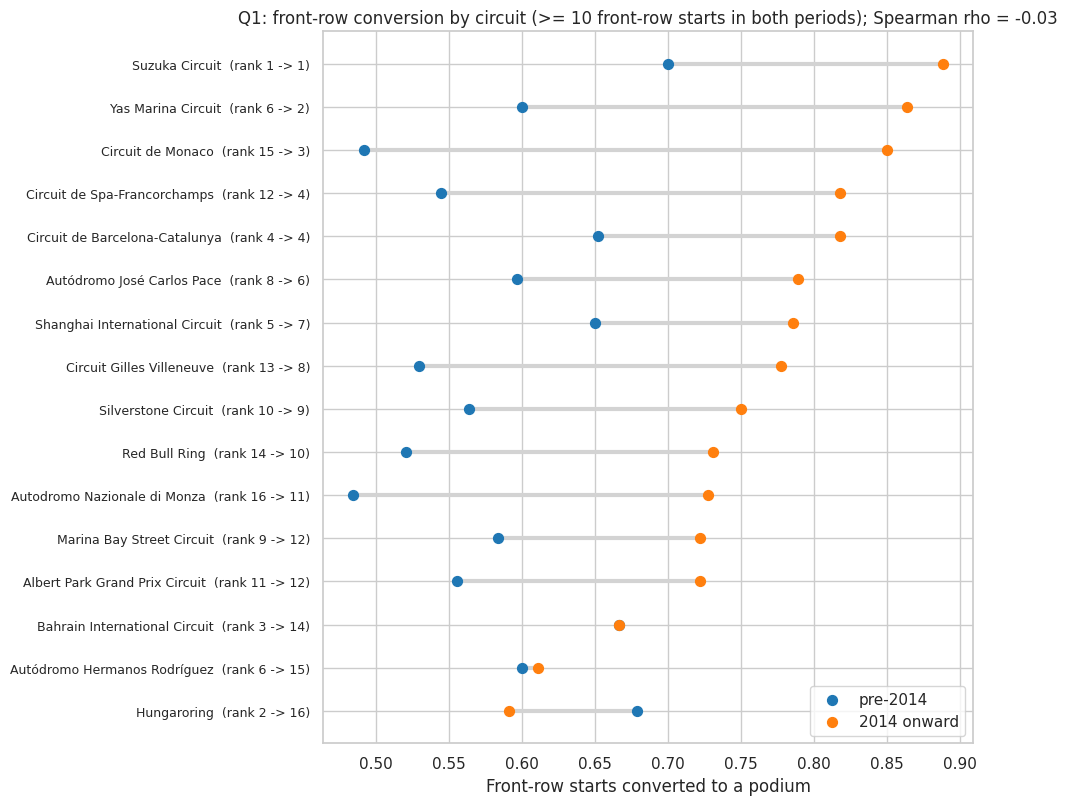

In [217]:
# Dumbbell chart: one row per circuit, sorted by 2014+ conversion; the label shows the rank in each period
d = both.sort_values('conv_2014on')
fig, ax = plt.subplots(figsize=(10, 0.42 * len(d) + 1.5))
y = np.arange(len(d))
ax.hlines(y, d['conv_pre2014'], d['conv_2014on'], color='lightgrey', lw=3, zorder=1)
ax.scatter(d['conv_pre2014'], y, color='tab:blue', s=50, label='pre-2014', zorder=2)
ax.scatter(d['conv_2014on'], y, color='tab:orange', s=50, label='2014 onward', zorder=2)
ax.set_yticks(y)
ax.set_yticklabels([f"{c}  (rank {int(r1)} -> {int(r2)})" for c, r1, r2 in zip(d.index, d['rank_pre2014'], d['rank_2014on'])], fontsize=9)
ax.set_xlabel('Front-row starts converted to a podium')
ax.set_title(f'Q1: front-row conversion by circuit (>= {MIN_FRONT_ROW_STARTS} front-row starts in both periods); Spearman rho = {rho:.2f}')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

In [218]:
# Minimum-sample check: how wide is the uncertainty for a typical 2014+ circuit?
lo, hi = wilson_ci(both['conv_2014on'] * both['starts_2014on'], both['starts_2014on'])
print('Median 95% interval width per circuit, 2014+:', f'{np.median(hi - lo):.2f}')


# Penalty check: the brief says qualifying position and grid differ (penalties).
# Grid is the real starting slot AFTER penalties, so it already includes them. We measure how much it matters.
qg = (clean['qualifying'][['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_pos'})
      .merge(clean['results'][['raceId', 'driverId', 'grid', 'positionOrder', 'pit_lane_start']], on=['raceId', 'driverId'])
      .merge(clean['races'][['raceId', 'is_sprint_weekend']], on='raceId'))
qg['podium'] = qg['positionOrder'] <= 3
demoted = qg[(qg['quali_pos'] <= 2) & (qg['grid'] > 2)]    # qualified front row, started further back
promoted = qg[(qg['quali_pos'] > 2) & (qg['grid'] <= 2)]   # moved onto the front row (someone else's penalty)
pd.DataFrame({
    'front-row starts': [int((qg['quali_pos'] <= 2).sum()), int((qg['grid'] <= 2).sum())],
    'podium conversion': [qg.loc[qg['quali_pos'] <= 2, 'podium'].mean(), qg.loc[qg['grid'] <= 2, 'podium'].mean()],
}, index=['front row by qualifying', 'front row by grid (used)']).round(3)

Median 95% interval width per circuit, 2014+: 0.35


,front-row starts,podium conversion
front row by qualifying,984,0.691
front row by grid (used),984,0.703


In [219]:
print(f'Qualified top 2 but started P3 or lower: {len(demoted)} '
      f'(sprint weekends: {int(demoted["is_sprint_weekend"].sum())}, pit lane: {int(demoted["pit_lane_start"].sum())}, '
      f'median grid: {demoted["grid"].median():.0f}, podium rate: {demoted["podium"].mean():.2f})')
print(f'Qualified P3 or lower but started top 2: {len(promoted)} (podium rate: {promoted["podium"].mean():.2f})')

Qualified top 2 but started P3 or lower: 36 (sprint weekends: 6, pit lane: 0, median grid: 7, podium rate: 0.31)
Qualified P3 or lower but started top 2: 36 (podium rate: 0.64)


> **Answer to Q1:**
> - Front-row starts convert **far more often from 2014** (about 76%) than before (about 56%); the confidence intervals do not overlap. More reliable cars mean a good start is lost less often.
> - **The circuit ranking changes almost completely:** Spearman ρ between the two rankings is close to 0, so a circuit's position before 2014 says nothing about its position after.
> - **Caveat:** each circuit has only about 20 front-row starts from 2014, so each circuit's rate has a wide interval (printed above). Differences of a few points between circuits are not meaningful; the overall rise and the reshuffled order are.
> - **Penalties were checked.** Grid is the starting slot *after* penalties, so it already includes them. Since 1994, about 36 top-2 qualifiers started further back (penalties, or the sprint setting the grid in 2021–22) and converted only about 31% of the time; 36 others were promoted onto the front row and converted about 64%. Defining the front row by qualifying instead of grid changes the overall conversion by about 1 point (69% vs 70%), so the choice matters little for the ranking but grid is the correct definition.

### 9.2 Q2: Do drivers podium more often at home, after controlling for starting position?

**Method (the brief's own wording):** "comparing drivers who started from similar grid positions". We split starters into **grid groups** (P1, P2, P3, P4–5, P6–10, P11–15, P16+) and compare the home and away podium rate **inside each group**. Then one number summarises all groups:
- **Mantel–Haenszel odds ratio:** the home/away odds ratio pooled across grid groups (1 = no home effect, above 1 = home advantage), with a p-value that says whether the difference could be chance.
- **Logistic regression** `podium ~ is_home + grid group` as a cross-check.

**Population:** drivers whose nationality has a home Grand Prix (D13); drivers who could never race at home are left out.

In [220]:
q2 = clean['model_base'][clean['model_base']['home_country'].notna()].copy()
q2['grid_group'] = q2['grid_group'].astype(str)
order = ['P1', 'P2', 'P3', 'P4-5', 'P6-10', 'P11-15', 'P16+']

q2_table = (q2.groupby(['grid_group', 'is_home'])['podium'].agg(['mean', 'size'])
              .unstack('is_home').reindex(order))
q2_table.columns = ['away_rate', 'home_rate', 'away_starts', 'home_starts']
q2_table['home_minus_away'] = q2_table['home_rate'] - q2_table['away_rate']
print('Home starts:', int(q2['is_home'].sum()), '| away starts:', int((q2['is_home'] == 0).sum()))
q2_table[['away_starts', 'home_starts', 'away_rate', 'home_rate', 'home_minus_away']].round(3)

Home starts: 1915 | away starts: 20326


,away_starts,home_starts,away_rate,home_rate,home_minus_away
grid_group,,,,,
P1,937,81,0.655,0.593,-0.063
P2,915,75,0.573,0.560,-0.013
P3,900,72,0.453,0.542,0.088
P4-5,1810,143,0.297,0.350,0.053
P6-10,4553,410,0.108,0.083,-0.025
P11-15,4627,407,0.029,0.025,-0.004
P16+,6584,727,0.007,0.003,-0.004


In [221]:
strata = []
for g in order:
    d = q2[q2['grid_group'] == g]
    strata.append(pd.crosstab(d['is_home'], d['podium']).reindex(index=[1, 0], columns=[1, 0], fill_value=0).values)
mh = StratifiedTable(strata)
mh_or, (mh_lo, mh_hi), mh_p = mh.oddsratio_pooled, mh.oddsratio_pooled_confint(), mh.test_null_odds().pvalue

logit = smf.logit('podium ~ is_home + C(grid_group)', data=q2).fit(disp=0)
lr_or, lr_p = np.exp(logit.params['is_home']), logit.pvalues['is_home']

print(f'Mantel-Haenszel odds ratio (home vs away, grid-adjusted): {mh_or:.2f}  95% CI [{mh_lo:.2f}, {mh_hi:.2f}]  p = {mh_p:.3f}')
print(f'Logistic regression odds ratio for is_home:              {lr_or:.2f}  p = {lr_p:.3f}')

Mantel-Haenszel odds ratio (home vs away, grid-adjusted): 0.95  95% CI [0.80, 1.13]  p = 0.570
Logistic regression odds ratio for is_home:              0.95  p = 0.569


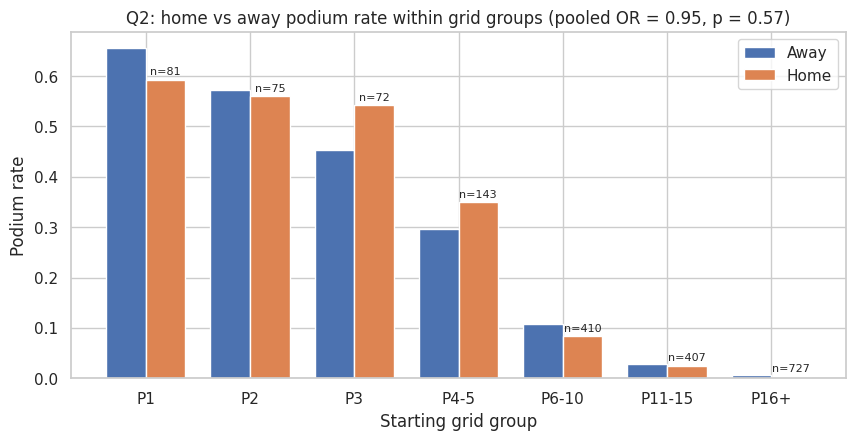

In [222]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(order)); w = 0.38
ax.bar(x - w/2, q2_table['away_rate'], w, label='Away')
ax.bar(x + w/2, q2_table['home_rate'], w, label='Home')
for i, g in enumerate(order):
    ax.text(x[i] + w/2, q2_table.loc[g, 'home_rate'] + 0.01, f"n={int(q2_table.loc[g, 'home_starts'])}", ha='center', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(order)
ax.set_xlabel('Starting grid group'); ax.set_ylabel('Podium rate')
ax.set_title(f'Q2: home vs away podium rate within grid groups (pooled OR = {mh_or:.2f}, p = {mh_p:.2f})')
ax.legend(); plt.show()

> **Answer to Q2:** **no measurable home advantage** once starting position is accounted for. Inside each grid group the home and away rates are close, home is higher in some groups and lower in others, and the pooled odds ratio is about 0.95 with a confidence interval that includes 1 (p ≈ 0.6). The logistic regression agrees.
>
> **Caveats:** only about 8% of starts are home starts, so small effects cannot be ruled out; nationality is one label per driver (D13); one-off local entrants in early decades may pull the home rate down.

### 9.3 Q3: Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**Definitions**
- **Mechanical retirement** = a race start that ended because a car component failed (brief note). The status mapping is D9 (section 5.7): Engine, Gearbox, Power Unit, Brakes, Hydraulics … plus Puncture, Tyre, Fire, Safety belt (Piazza). Accidents, driver causes, regulation decisions and statuses with no cause (`Retired`, `Damage` …) are not mechanical.
- **Rate** = mechanical retirements ÷ **race starts** (the brief's note). Non-starters were already removed (D3).
- **Constructor** = `constructorId` as it is (D11): renamed teams appear under each name.
- **Minimum sample:** at least **40 starts** in a period (one car-season is about 20).

**Robustness check:** the same ranking with the `unclear` statuses (mostly `Retired`) also counted as mechanical.

In [223]:
MIN_STARTS_Q3 = 40

q3 = (clean['results'][['raceId', 'constructorId', 'status_base']]
      .merge(clean['races'][['raceId', 'year']], on='raceId')
      .merge(clean['constructors'][['constructorId', 'name']].rename(columns={'name': 'constructor'}), on='constructorId'))
q3 = q3[q3['year'].between(2014, 2024)].copy()
q3['period'] = np.where(q3['year'] <= 2021, '2014-2021', '2022-2024')
q3['mechanical'] = q3['status_base'] == 'mechanical'
q3['mechanical_broad'] = q3['status_base'].isin(['mechanical', 'unclear'])

q3_rates = (q3.groupby(['period', 'constructor'])
              .agg(starts=('mechanical', 'size'), mechanical=('mechanical', 'sum'),
                   rate=('mechanical', 'mean'), rate_broad=('mechanical_broad', 'mean'))
              .reset_index())
q3_rates = q3_rates[q3_rates['starts'] >= MIN_STARTS_Q3]

for per in ['2014-2021', '2022-2024']:
    d = q3_rates[q3_rates['period'] == per].sort_values('rate', ascending=False)
    rho_sb = spearmanr(d['rate'], d['rate_broad'])[0]
    print(f'{per}: {len(d)} constructors | overall rate {q3.loc[q3.period == per, "mechanical"].mean():.3f} '
          f'| ranking strict vs broad: Spearman rho = {rho_sb:.2f}')
q3_rates.sort_values(['period', 'rate'], ascending=[True, False]).round(3)

2014-2021: 17 constructors | overall rate 0.100 | ranking strict vs broad: Spearman rho = 0.98
2022-2024: 12 constructors | overall rate 0.061 | ranking strict vs broad: Spearman rho = 0.75


,period,constructor,starts,mechanical,rate,rate_broad
8,2014-2021,Lotus F1,75,15,0.200,0.240
17,2014-2021,Toro Rosso,242,40,0.165,0.182
15,2014-2021,Renault,200,29,0.145,0.165
11,2014-2021,McLaren,319,46,0.144,0.163
16,2014-2021,Sauber,200,23,0.115,0.135
14,2014-2021,Red Bull,319,36,0.113,0.119
13,2014-2021,Racing Point,76,8,0.105,0.105
7,2014-2021,Haas F1 Team,242,23,0.095,0.124
1,2014-2021,AlphaTauri,77,7,0.091,0.104
2,2014-2021,Alpine F1 Team,44,4,0.091,0.091


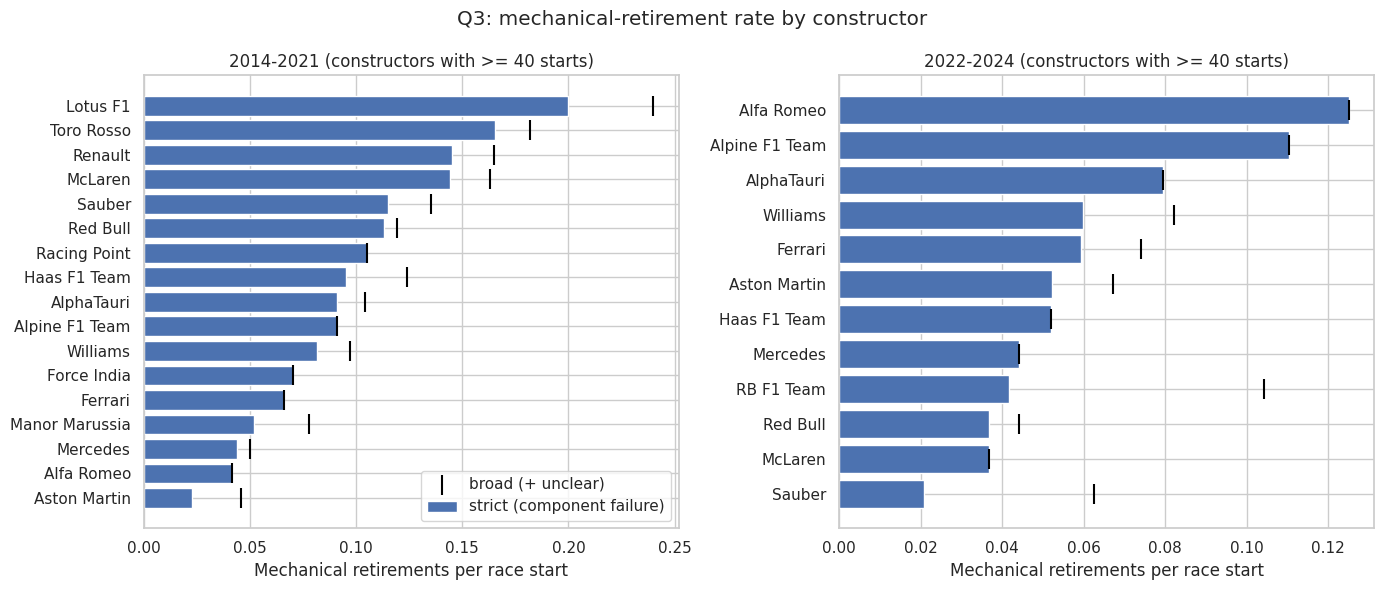

In [224]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, per in zip(axes, ['2014-2021', '2022-2024']):
    d = q3_rates[q3_rates['period'] == per].sort_values('rate')
    ax.barh(d['constructor'], d['rate'], label='strict (component failure)')
    ax.scatter(d['rate_broad'], d['constructor'], color='black', marker='|', s=200, label='broad (+ unclear)', zorder=3)
    ax.set_title(f'{per} (constructors with >= {MIN_STARTS_Q3} starts)')
    ax.set_xlabel('Mechanical retirements per race start')
axes[0].legend(loc='lower right')
plt.suptitle('Q3: mechanical-retirement rate by constructor')
plt.tight_layout(); plt.show()

> **Answer to Q3:**
> - **2014–2021:** the highest rates belong to Lotus F1, Toro Rosso, Renault and McLaren (McLaren's 2015–17 Honda years). Mercedes, the dominant team, is among the lowest.
> - **2022–2024:** rates fall for almost every team (the overall rate drops); Alfa Romeo and Alpine have the highest rates, McLaren and Red Bull among the lowest.
> - **Robustness:** counting `Retired` and the other unclear statuses as mechanical barely changes the 2014–2021 ranking (ρ ≈ 0.98) and changes 2022–2024 somewhat more (ρ ≈ 0.75), mainly for teams with few starts (RB, Sauber 2024).
> - **Caveats:** renamed teams are split (D11), so e.g. Racing Point → Aston Martin appear separately; small-start teams (≈ 40–90 starts) have wide uncertainty.

## 10. Feature engineering

**Prediction cutoff:** after qualifying, before the race starts. Every feature below is known at that moment; anything known only later (finishing position, points, laps, status, pit stops, lap times) is never used.

**Team decisions used here:** D7 (train on all seasons; missing qualifying filled from grid + flag), D10 (standings before a season opener = 0 points + flag), D11 (form looks back over the current and previous season only), D14 (qualifying gap to the fastest Q1 time; best-of-Q1/Q2/Q3 tested as an experiment), N = 5 for every "last N races" feature.

| Group | Feature | How it is computed (pre-race) | Why |
|---|---|---|---|
| Grid | `grid` | starting slot after penalties (D4: pit lane = behind the field) | strongest single signal (6.2) |
| | `pit_lane_start` | D4 flag | a pit-lane start is worse than "last on the grid" |
| | `field_size` | starters in the race | podium base rate is 3 ÷ field size; fields shrink over the decades |
| Qualifying | `quali_position` | qualifying position; **filled from grid** when missing (D7) | carries penalty information beyond grid |
| | `has_quali` | 1 if a real qualifying row exists | tells the model which `quali_position` values are filled copies |
| | `q1_gap_pct` | (driver's Q1 − fastest Q1 in the same race) ÷ fastest × 100 | how much slower, comparable across circuits (raw times are not) |
| | `best_gap_pct` | same with each driver's best of Q1/Q2/Q3 | **experiment only** (D14), compared with `q1_gap_pct` |
| | `grid_penalty` | max(0, grid − qualifying position); 0 on 2021–22 sprint weekends and without qualifying | a penalised driver is faster than his grid slot |
| Driver form | `drv_champ_rank_before`, `drv_points_share_before` | championship standings from a **strictly earlier** race of the same season; share = points ÷ leader's points | current-season strength; share is comparable across points systems |
| | `no_standing_yet` | 1 if the driver has no earlier standing this season | the 0 / last-place values above are empty, not bad |
| | `drv_podium_last5` | podium share in the driver's last 5 starts within the current + previous season | recent form |
| | `drv_no_recent_history` | 1 if no start in that window | the 0 above means "no data" |
| | `drv_starts_before` | career starts before this race | experience |
| | `teammate_gap_last5` | average of (own grid − teammate's grid) over the driver's last 5 races, **2-car teams only** | separates the driver from the car |
| | `teammate_gap_missing` | 1 if no 2-car-team race in the window (old eras, solo entries) | the 0 above means "no data" |
| Team form | `team_champ_rank_before` | constructor standings from a strictly earlier race (championship exists from 1958) | car strength |
| | `team_podium_rate_last5` | team's podium share over its last 5 races (current + previous season) | recent car pace |
| | `team_mech_dnf_rate_last5` | share of the team's recent starts ending in a mechanical retirement (D9) | reliability: a fast car that breaks does not podium |
| | `team_no_recent_history` | 1 if the team has no race in the window (new, renamed or returning team) | the 0s above mean "no data" |
| Context | `is_season_opener` | round = 1 | standings are empty at round 1 (D10) |
| | `era_index` | 0 = 1950–57 … 8 = 2022–25 | conversion and reliability differ by era (6.2, Q1, Q3) |

**Considered and not used:** `is_home` (Q2: no effect, p = 0.57), circuit identity (Q1: per-circuit samples too small), `year` (a time split puts test years outside training), `driver_age` (weak, corr 0.06), sprint results (D8), raw lap times (not comparable across circuits).

### 10.1 Helper functions

- `past_window`: average of a value over a group's previous N races, using **only earlier races** (strictly smaller `race_order`) from the current or previous season. The current race is never included.
- `standings_before`: the latest standings from a **strictly earlier** race of the same season (`merge_asof` on `race_order`, `allow_exact_matches=False`).

In [225]:
N_LAST = 5                  # "last N races" for every form feature (team decision)
WINDOW_SEASONS = 1          # look back over the current and the previous season only (D11)

def past_window(df, group_col, value_cols, n=N_LAST, window_seasons=WINDOW_SEASONS):
    '''For every row, average value_cols over the previous n rows of the same group,
    using ONLY earlier races (strictly smaller race_order) from the current or previous season.
    Returns the averages plus how many past rows were used. The current row is never included.'''
    d = df.sort_values([group_col, 'race_order'])
    out = {c: np.full(len(d), np.nan) for c in value_cols}
    used = np.zeros(len(d), dtype=int)
    groups = d[group_col].to_numpy()
    years = d['year'].to_numpy()
    orders = d['race_order'].to_numpy()
    vals = {c: d[c].to_numpy(dtype=float) for c in value_cols}
    start = 0
    for i in range(len(d)):
        if i > 0 and groups[i] != groups[i - 1]:
            start = i
        picked = []
        j = i - 1
        while j >= start and len(picked) < n:
            if orders[j] < orders[i] and years[j] >= years[i] - window_seasons:
                picked.append(j)
            elif years[j] < years[i] - window_seasons:
                break
            j -= 1
        used[i] = len(picked)
        if picked:
            for c in value_cols:
                v = vals[c][picked]
                v = v[~np.isnan(v)]
                if len(v):
                    out[c][i] = v.mean()
    res = pd.DataFrame(out, index=d.index)
    res['n_used'] = used
    return res.reindex(df.index)

def standings_before(base, standings, key):
    '''Latest championship standings from a STRICTLY EARLIER race of the same season.'''
    snap = standings.merge(clean['races'][['raceId', 'year', 'race_order']], on='raceId')
    leader = snap.groupby('raceId')['points'].transform('max')
    snap = snap.assign(points_share=np.where(leader > 0, snap['points'] / leader, 0.0),
                       st_order=snap['race_order'])
    snap = snap[[key, 'year', 'st_order', 'position', 'points_share']].sort_values('st_order')
    left = base[['row_id', key, 'year', 'race_order']].sort_values('race_order')
    m = pd.merge_asof(left, snap, left_on='race_order', right_on='st_order', by=[key, 'year'],
                      direction='backward', allow_exact_matches=False)
    return m.set_index('row_id').reindex(base['row_id'])

### 10.2 Build the feature table

`build_features` takes a cleaned results table and returns one row per driver per race with the target and all features. It is a function so the experiments (e.g. keeping non-starters, D3) can rebuild the table from another version of the data with exactly the same code.

In [226]:
def build_features(results):
    '''Build the pre-race feature table from a cleaned results table (one row per driver per race).
    Written as a function so the experiments can rebuild it from other versions of the data.'''
    f = (results[['raceId', 'driverId', 'constructorId', 'grid', 'pit_lane_start', 'positionOrder', 'status_base']]
         .merge(clean['races'][['raceId', 'year', 'round', 'race_order', 'is_sprint_weekend']], on='raceId', how='left')
         .reset_index(drop=True))
    f['row_id'] = np.arange(len(f))
    f['podium'] = (f['positionOrder'] <= 3).astype(int)                       # TARGET

    # ---------------- A. starting position ----------------
    f['field_size'] = f.groupby('raceId')['driverId'].transform('size')

    # ---------------- B. qualifying (D14) ----------------
    q = clean['qualifying'][['raceId', 'driverId', 'position', 'q1_sec', 'q2_sec', 'q3_sec']].copy()
    q['best_sec'] = q[['q1_sec', 'q2_sec', 'q3_sec']].min(axis=1)
    q['q1_gap_pct'] = 100 * (q['q1_sec'] / q.groupby('raceId')['q1_sec'].transform('min') - 1)
    q['best_gap_pct'] = 100 * (q['best_sec'] / q.groupby('raceId')['best_sec'].transform('min') - 1)
    f = f.merge(q[['raceId', 'driverId', 'position', 'q1_gap_pct', 'best_gap_pct']]
                .rename(columns={'position': 'quali_real'}), on=['raceId', 'driverId'], how='left')
    f['has_quali'] = f['quali_real'].notna().astype(int)
    f['quali_position'] = f['quali_real'].fillna(f['grid']).astype(float)          # D7: fill from grid
    sprint_sets_grid = (f['is_sprint_weekend'] == 1) & f['year'].between(2021, 2022)
    f['grid_penalty'] = np.where((f['has_quali'] == 1) & ~sprint_sets_grid,
                                 (f['grid'] - f['quali_real']).clip(lower=0), 0).astype(float)

    # ---------------- C. driver standings before the race (D10) ----------------
    ds = standings_before(f, clean['driver_standings'], 'driverId')
    f['drv_st_order'] = ds['st_order'].to_numpy()
    f['no_standing_yet'] = ds['st_order'].isna().astype(int).to_numpy()
    f['drv_champ_rank_before'] = ds['position'].astype(float).to_numpy()
    f['drv_points_share_before'] = ds['points_share'].fillna(0.0).to_numpy()
    f['drv_champ_rank_before'] = f['drv_champ_rank_before'].fillna(f['field_size'])  # no standing = last place
    f['is_season_opener'] = (f['round'] == 1).astype(int)

    # ---------------- D. driver form and experience ----------------
    f['is_mech'] = (f['status_base'] == 'mechanical').astype(float)
    drv = past_window(f, 'driverId', ['podium'])
    f['drv_podium_last5'] = drv['podium']
    f['drv_no_recent_history'] = (drv['n_used'] == 0).astype(int)
    f['drv_podium_last5'] = f['drv_podium_last5'].fillna(0.0)
    f['drv_starts_before'] = f.sort_values('race_order').groupby('driverId').cumcount()   # starts BEFORE this race

    # teammate gap (2-car teams only), then the driver's average gap over his last 5 races
    team_size = f.groupby(['raceId', 'constructorId'])['driverId'].transform('size')
    team_grid_sum = f.groupby(['raceId', 'constructorId'])['grid'].transform('sum')
    f['tm_gap_race'] = np.where(team_size == 2, f['grid'] - (team_grid_sum - f['grid']), np.nan)
    tm = past_window(f, 'driverId', ['tm_gap_race'])
    f['teammate_gap_last5'] = tm['tm_gap_race']
    f['teammate_gap_missing'] = f['teammate_gap_last5'].isna().astype(int)
    f['teammate_gap_last5'] = f['teammate_gap_last5'].fillna(0.0)

    # ---------------- E. team standings and team form ----------------
    cs = standings_before(f, clean['constructor_standings'], 'constructorId')
    f['team_st_order'] = cs['st_order'].to_numpy()
    f['team_champ_rank_before'] = cs['position'].astype(float).to_numpy()
    n_teams = f.groupby('raceId')['constructorId'].transform('nunique')
    f['team_champ_rank_before'] = f['team_champ_rank_before'].fillna(n_teams)       # none yet / before 1958 = last
    team_race = (f.groupby(['constructorId', 'raceId'])
                  .agg(year=('year', 'first'), race_order=('race_order', 'first'),
                       team_podium=('podium', 'mean'), team_mech=('is_mech', 'mean'))
                  .reset_index())
    tf = past_window(team_race, 'constructorId', ['team_podium', 'team_mech'])
    team_race['team_podium_rate_last5'] = tf['team_podium']
    team_race['team_mech_dnf_rate_last5'] = tf['team_mech']
    team_race['team_no_recent_history'] = (tf['n_used'] == 0).astype(int)
    f = f.merge(team_race[['constructorId', 'raceId', 'team_podium_rate_last5', 'team_mech_dnf_rate_last5',
                           'team_no_recent_history']], on=['constructorId', 'raceId'], how='left')
    f[['team_podium_rate_last5', 'team_mech_dnf_rate_last5']] = f[['team_podium_rate_last5',
                                                                    'team_mech_dnf_rate_last5']].fillna(0.0)

    # ---------------- F. context ----------------
    f['era'] = f['year'].map(era_of)
    return f.sort_values(['race_order', 'grid']).reset_index(drop=True)

features = build_features(clean['results'])
print('feature table:', features.shape)

feature table: (24588, 38)


### 10.3 Feature list and groups

The groups are the units of the **ablation study** (later): each group is removed in turn to measure what it adds. `q1_gap_pct` and `best_gap_pct` keep their missing values here; they are filled inside the model pipeline, **fitted on the training seasons only**, using the imputation method chosen by experiment.

`era_index` is an ordered number rather than one-hot columns: with split (a) the test era (2022–25) never appears in training, so its one-hot column would be all zeros in the training data and carry nothing.

In [227]:
# Era as an ordered number (0 = 1950-57 ... ). One-hot dummies would fail here: under split (a) the test era
# (2022-25) never appears in training, so its dummy column would be all zeros in train and useless.
ERA_ORDER = [e[2] for e in ERAS]
features['era_index'] = features['era'].map({e: i for i, e in enumerate(ERA_ORDER)}).astype(int)

FEATURE_GROUPS = {
    'grid':          ['grid', 'pit_lane_start', 'field_size'],
    'qualifying':    ['quali_position', 'has_quali', 'q1_gap_pct', 'grid_penalty'],
    'driver_form':   ['drv_champ_rank_before', 'drv_points_share_before', 'no_standing_yet',
                      'drv_podium_last5', 'drv_no_recent_history', 'drv_starts_before',
                      'teammate_gap_last5', 'teammate_gap_missing'],
    'team_form':     ['team_champ_rank_before', 'team_podium_rate_last5', 'team_mech_dnf_rate_last5',
                      'team_no_recent_history'],
    'context':       ['is_season_opener', 'era_index'],
}
ALT_QUALI_GAP = 'best_gap_pct'          # experiment: replaces q1_gap_pct (D14)
FEATURES = [c for cols in FEATURE_GROUPS.values() for c in cols]
TARGET = 'podium'
NEEDS_IMPUTATION = ['q1_gap_pct', 'best_gap_pct']    # filled inside the model pipeline, fitted on train only

# Columns that must NEVER be features (known only after the race)
POST_RACE = {'positionOrder', 'position', 'positionText', 'points', 'laps', 'time', 'milliseconds',
             'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId', 'status', 'status_base',
             'is_mech', 'podium', 'tm_gap_race'}
print(len(FEATURES), 'features in', len(FEATURE_GROUPS), 'groups')
pd.Series({g: ', '.join(c) for g, c in FEATURE_GROUPS.items()}, name='features').to_frame()

21 features in 5 groups


,features
grid,"grid, pit_lane_start, field_size"
qualifying,"quali_position, has_quali, q1_gap_pct, grid_pe..."
driver_form,"drv_champ_rank_before, drv_points_share_before..."
team_form,"team_champ_rank_before, team_podium_rate_last5..."
context,"is_season_opener, era_index"


### 10.4 Feature leakage gate

Like the cleaning gate (5.20), one cell checks the rules every feature must obey and stops the notebook if one fails. The two Hamilton checks are hand-verified examples: before the 2008 Malaysian GP he had 10 of the leader's 10 points (share 1.0), and he qualified 4th but started 9th after a 5-place penalty.

In [228]:
# Feature leakage gate: every rule must pass, otherwise the notebook stops
f = features
ham = f[(f['driverId'] == 1) & (f['year'] == 2008)].set_index('round')
leak = {
    'a feature is a post-race column':                     len(set(FEATURES) & POST_RACE),
    'driver standings from the same or a later race':      int((f['drv_st_order'] >= f['race_order']).sum()),
    'team standings from the same or a later race':        int((f['team_st_order'] >= f['race_order']).sum()),
    'season opener with non-zero points share':            int(((f['is_season_opener'] == 1) & (f['drv_points_share_before'] > 0)).sum()),
    "driver's first-ever start with past starts > 0":      int((f.sort_values('race_order').groupby('driverId').head(1)['drv_starts_before'] > 0).sum()),
    "driver's first-ever start with form history":         int((f.sort_values('race_order').groupby('driverId').head(1)['drv_no_recent_history'] == 0).sum()),
    'a feature almost equal to the target (|corr| > 0.9)': int((f[FEATURES].corrwith(f[TARGET]).abs() > 0.9).sum()),
    'Hamilton 2008 R2 points share != 1.0 (10 of 10)':     int(abs(ham.loc[2, 'drv_points_share_before'] - 1.0) > 1e-9),
    'Hamilton 2008 R2 grid penalty != 5 (Q4 -> P9)':       int(ham.loc[2, 'grid_penalty'] != 5),
    'missing values outside the planned gap features':     int(f[[c for c in FEATURES if c not in NEEDS_IMPUTATION]].isna().sum().sum()),
}
leak_gate = pd.DataFrame({'failing': leak})
leak_gate['result'] = np.where(leak_gate['failing'] == 0, 'pass', 'FAIL')
display(leak_gate)
assert (leak_gate['failing'] == 0).all(), 'Feature leakage gate failed'
print(f'All {len(leak_gate)} feature rules pass.')

,failing,result
a feature is a post-race column,0,pass
driver standings from the same or a later race,0,pass
team standings from the same or a later race,0,pass
season opener with non-zero points share,0,pass
driver's first-ever start with past starts > 0,0,pass
driver's first-ever start with form history,0,pass
a feature almost equal to the target (|corr| > 0.9),0,pass
Hamilton 2008 R2 points share != 1.0 (10 of 10),0,pass
Hamilton 2008 R2 grid penalty != 5 (Q4 -> P9),0,pass
missing values outside the planned gap features,0,pass


All 10 feature rules pass.


## 11. Train / validation / test split

**Chosen split (a):** train 1950–2019, validation 2020–2021, test 2022–2024. It is **by time**, never random: a random split would put 2023 races in training and 2015 races in test, and every "last 5 races" feature would then use information from the future of the rows it is tested on.

The instructors asked us to *assess* the split rather than copy it. The table below compares (a) with the alternative (b) (train ≤ 2021, validation 2022, test 2023–24) on the quantities that change how the model behaves.

In [229]:
SPLITS = {
    'a (chosen)':  {'train': (1950, 2019), 'val': (2020, 2021), 'test': (2022, 2024)},
    'b (compare)': {'train': (1950, 2021), 'val': (2022, 2022), 'test': (2023, 2024)},
}
def assign_split(years, scheme='a (chosen)'):
    s = pd.Series('unused', index=years.index)
    for name, (lo, hi) in SPLITS[scheme].items():
        s[years.between(lo, hi)] = name
    return s

features['split'] = assign_split(features['year'])
assert not features.groupby('raceId')['split'].nunique().gt(1).any(), 'a race appears in two splits'

split_summary = (features.groupby('split')
                 .agg(seasons=('year', lambda y: f'{y.min()}-{y.max()}'), races=('raceId', 'nunique'),
                      rows=('podium', 'size'), podium_rate=('podium', 'mean'),
                      with_qualifying=('has_quali', 'mean'), avg_field=('field_size', 'mean'))
                 .reindex(['train', 'val', 'test']))
split_summary.round(3)

,seasons,races,rows,podium_rate,with_qualifying,avg_field
split,,,,,,
train,1950-2019,1007,22455,0.135,0.371,22.751
val,2020-2021,39,779,0.150,0.999,19.976
test,2022-2024,68,1354,0.151,1.000,19.917


In [230]:
# Assessment of split (a): does validation look like test?  Compare the two schemes on what changes the model
rows = []
for scheme in SPLITS:
    sp = assign_split(features['year'], scheme)
    for part in ['train', 'val', 'test']:
        d = features[sp == part]
        rows.append({'scheme': scheme, 'part': part, 'seasons': f"{d['year'].min()}-{d['year'].max()}",
                     'rows': len(d), 'podium_rate': d['podium'].mean(),
                     'P1 converts': d.loc[d['grid'] == 1, 'podium'].mean(),
                     'mech DNF rate (team, last 5)': d['team_mech_dnf_rate_last5'].mean(),
                     'regulation era': ', '.join(sorted(d['era'].unique()))})
assess = pd.DataFrame(rows).set_index(['scheme', 'part'])
assess.round(3)

seasons   rows  podium_rate  P1 converts  \
scheme      part                                                
a (chosen)  train  1950-2019  22455        0.135        0.631   
            val    2020-2021    779        0.150        0.744   
            test   2022-2024   1354        0.151        0.794   
b (compare) train  1950-2021  23234        0.135        0.635   
            val    2022-2022    439        0.150        0.727   
            test   2023-2024    915        0.151        0.826   

                   mech DNF rate (team, last 5)  \
scheme      part                                  
a (chosen)  train                         0.274   
            val                           0.071   
            test                          0.060   
b (compare) train                         0.267   
            val                           0.097   
            test                          0.043   

                                                      regulation era  
scheme      part                                                      
a (chosen)  train  1950-57 front-engine, 1958-65 rear-engine, 196...  
            val                                       2014-21 hybrid  
            test                               2022-25 ground effect  
b (compare) train  1950-57 front-engine, 1958-65 rear-engine, 196...  
            val                                2022-25 ground effect  
            test                               2022-25 ground effect

> **Assessment of split (a)** (check the numbers above):
> - **Validation and test come from different regulation eras.** Validation is the end of the hybrid era (2014–21); test is the ground-effect era (2022–24). Settings tuned on validation (model choice, F1 threshold) may not transfer perfectly.
> - **Training looks very different from both:** a pole sitter converted about 63% of the time in training but 74–79% in validation and test, and recent team mechanical-DNF rates are about 27% in training vs 6–7% later. This is the cost of training from 1950 (D7); `era_index`, the reliability feature and the form features are there to absorb it.
> - **Strengths of (a):** the test set is three full seasons (about 1,350 rows, about 200 podiums), so test scores are more stable than with (b)'s two seasons; validation has two seasons instead of one.
> - (b) keeps validation and test in the same era. It is kept as a comparison: the modeling part reports the validation-to-test gap under both splits, which is the evidence for the choice.

## 12. Feature evidence (training seasons only)

The brief requires every feature to be justified with evidence. All evidence here uses the **training seasons only**; validation and test are not looked at until model evaluation.

In [231]:
# Feature evidence, measured on the TRAINING seasons only (validation and test are never looked at here)
train = features[features['split'] == 'train']
num_feats = [c for c in FEATURES if not c.startswith('era_')] + [ALT_QUALI_GAP]
ev = pd.DataFrame({
    'corr with podium (Spearman)': [train[[c, TARGET]].dropna().corr(method='spearman').iloc[0, 1] for c in num_feats],
    'missing %': [100 * train[c].isna().mean() for c in num_feats],
}, index=num_feats)
ev['|corr|'] = ev['corr with podium (Spearman)'].abs()
ev.sort_values('|corr|', ascending=False).drop(columns='|corr|').round(3)

,corr with podium (Spearman),missing %
best_gap_pct,-0.466,63.54
quali_position,-0.454,0.00
grid,-0.454,0.00
drv_podium_last5,0.448,0.00
team_podium_rate_last5,0.422,0.00
q1_gap_pct,-0.398,63.54
drv_points_share_before,0.363,0.00
drv_champ_rank_before,-0.361,0.00
team_champ_rank_before,-0.342,0.00
drv_starts_before,0.192,0.00


> **Reading the table:** grid, qualifying position, the qualifying gaps, recent driver and team podium rates and the championship features carry the strongest signal (|ρ| ≈ 0.35–0.47). Flags have near-zero correlation on their own; their job is to tell the model when another feature's value is a filled default, so they are judged in the ablation, not here. `q1_gap_pct` and `best_gap_pct` are missing for about 64% of training rows (no qualifying data before 1994), which is why their imputation is an experiment.

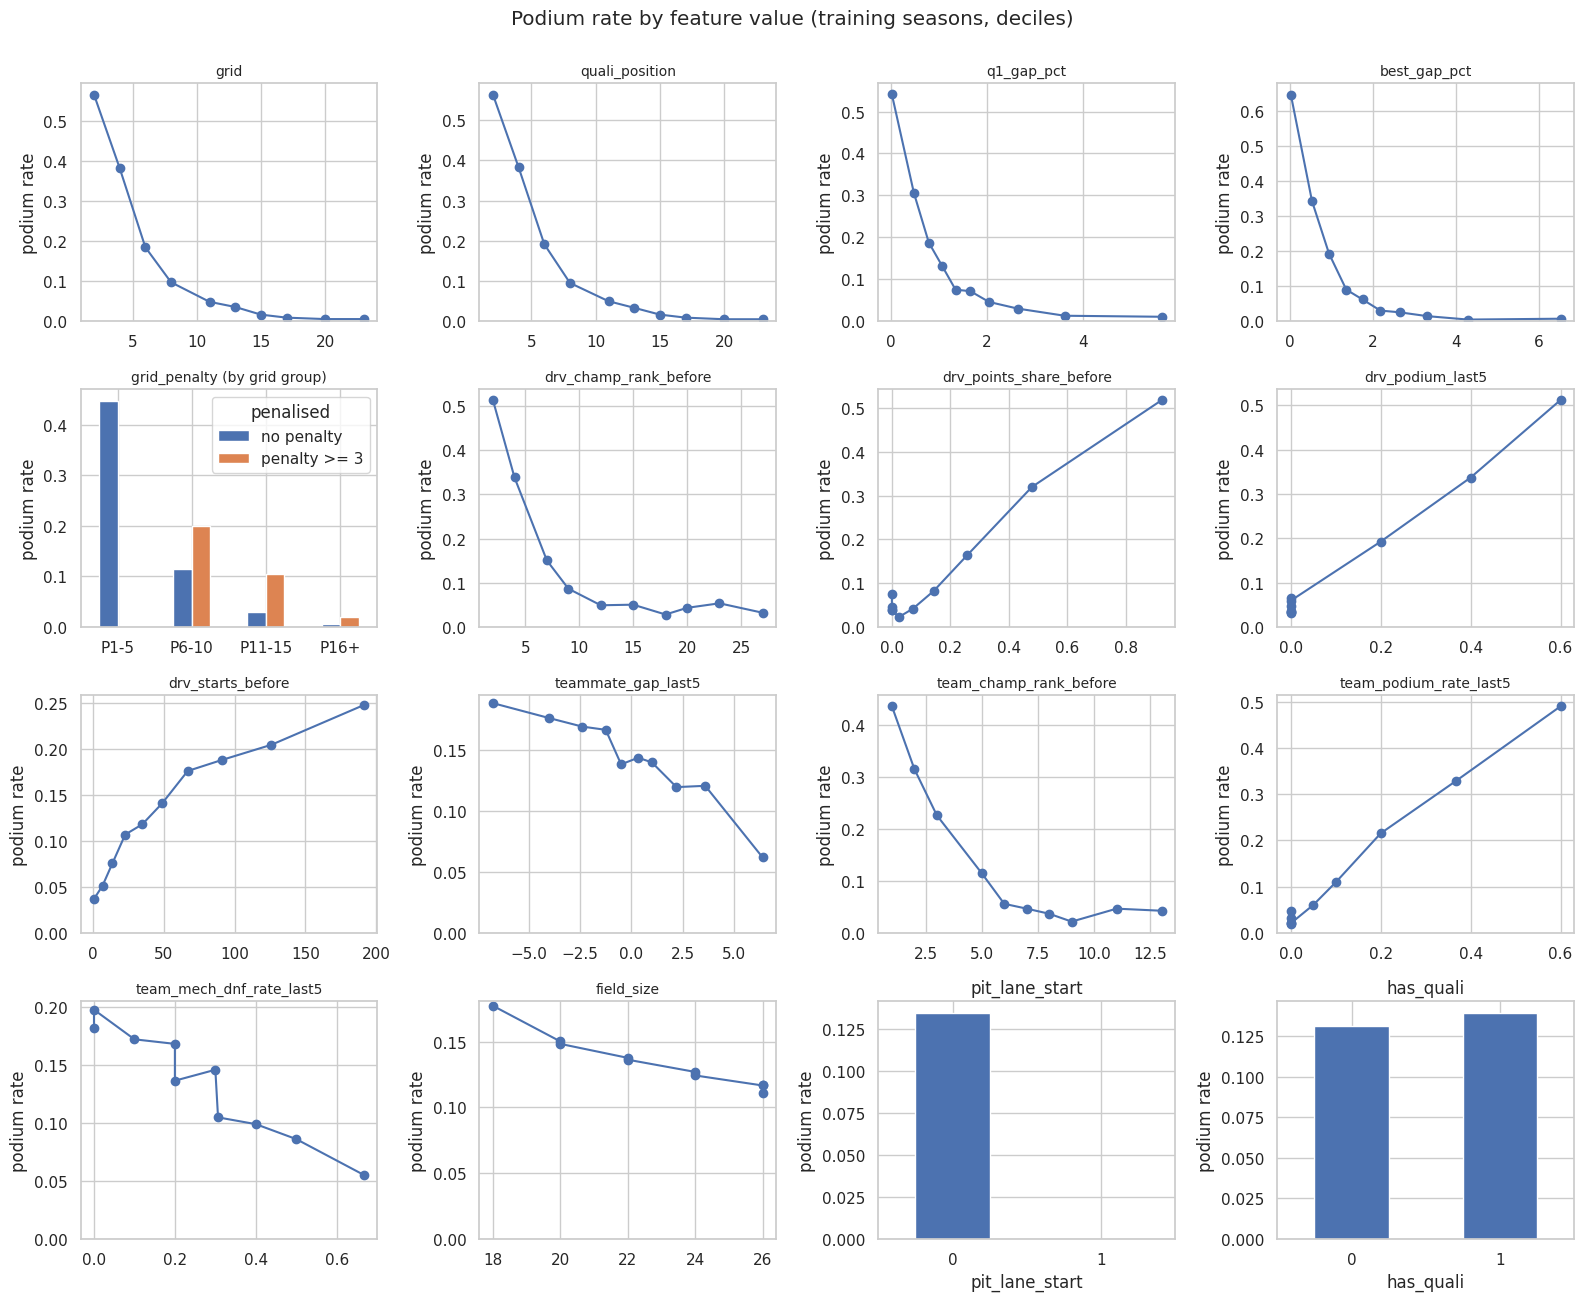

In [232]:
# Podium rate across the range of each numeric feature (training seasons): a feature is useful if the line moves
plot_feats = ['grid', 'quali_position', 'q1_gap_pct', 'best_gap_pct', 'grid_penalty', 'drv_champ_rank_before',
              'drv_points_share_before', 'drv_podium_last5', 'drv_starts_before', 'teammate_gap_last5',
              'team_champ_rank_before', 'team_podium_rate_last5', 'team_mech_dnf_rate_last5', 'field_size']
fig, axes = plt.subplots(4, 4, figsize=(16, 13)); axes = axes.ravel()
for ax, c in zip(axes, plot_feats):
    if c == 'grid_penalty':
        # 95% of rows have no penalty, so deciles are useless: compare penalised vs not, inside grid groups
        g = train.assign(gg=pd.cut(train['grid'], [0, 5, 10, 15, 100], labels=['P1-5', 'P6-10', 'P11-15', 'P16+']),
                         penalised=np.where(train['grid_penalty'] >= 3, 'penalty >= 3', 'no penalty'))
        g.groupby(['gg', 'penalised'], observed=True)[TARGET].mean().unstack().plot(kind='bar', ax=ax, rot=0)
        ax.set_title('grid_penalty (by grid group)', fontsize=10); ax.set_ylabel('podium rate'); ax.set_xlabel('')
        continue
    d = train[[c, TARGET]].dropna()
    if c == 'teammate_gap_last5':
        d = d[train.loc[d.index, 'teammate_gap_missing'] == 0]      # leave out the filled zeros
    bins = pd.qcut(d[c].rank(method='first'), q=min(10, d[c].nunique()), duplicates='drop')
    g = d.groupby(bins, observed=True).agg(x=(c, 'median'), rate=(TARGET, 'mean'))
    ax.plot(g['x'], g['rate'], marker='o')
    ax.set_title(c, fontsize=10); ax.set_ylabel('podium rate'); ax.set_ylim(0, None)
for c, ax in zip(['pit_lane_start', 'has_quali'], axes[len(plot_feats):]):
    train.groupby(c)[TARGET].mean().plot(kind='bar', ax=ax, title=c, rot=0); ax.set_ylabel('podium rate')
plt.suptitle('Podium rate by feature value (training seasons, deciles)', y=1.0)
plt.tight_layout(); plt.show()

> **Reading the plots:** a useful feature moves the podium rate across its range. Grid, qualifying position and gaps fall steeply; recent driver and team podium rates rise steeply; championship rank falls; mechanical-DNF rate falls (unreliable cars podium less); penalised drivers podium more often than unpenalised drivers starting from the same grid group. Pit-lane starters almost never podium. Weaker lines (field size, teammate gap) and flags such as `has_quali` are kept: a flag only tells the model when another value is a filled default, and the group ablation (14.1) shows that removing a group does not clearly improve the selected model.

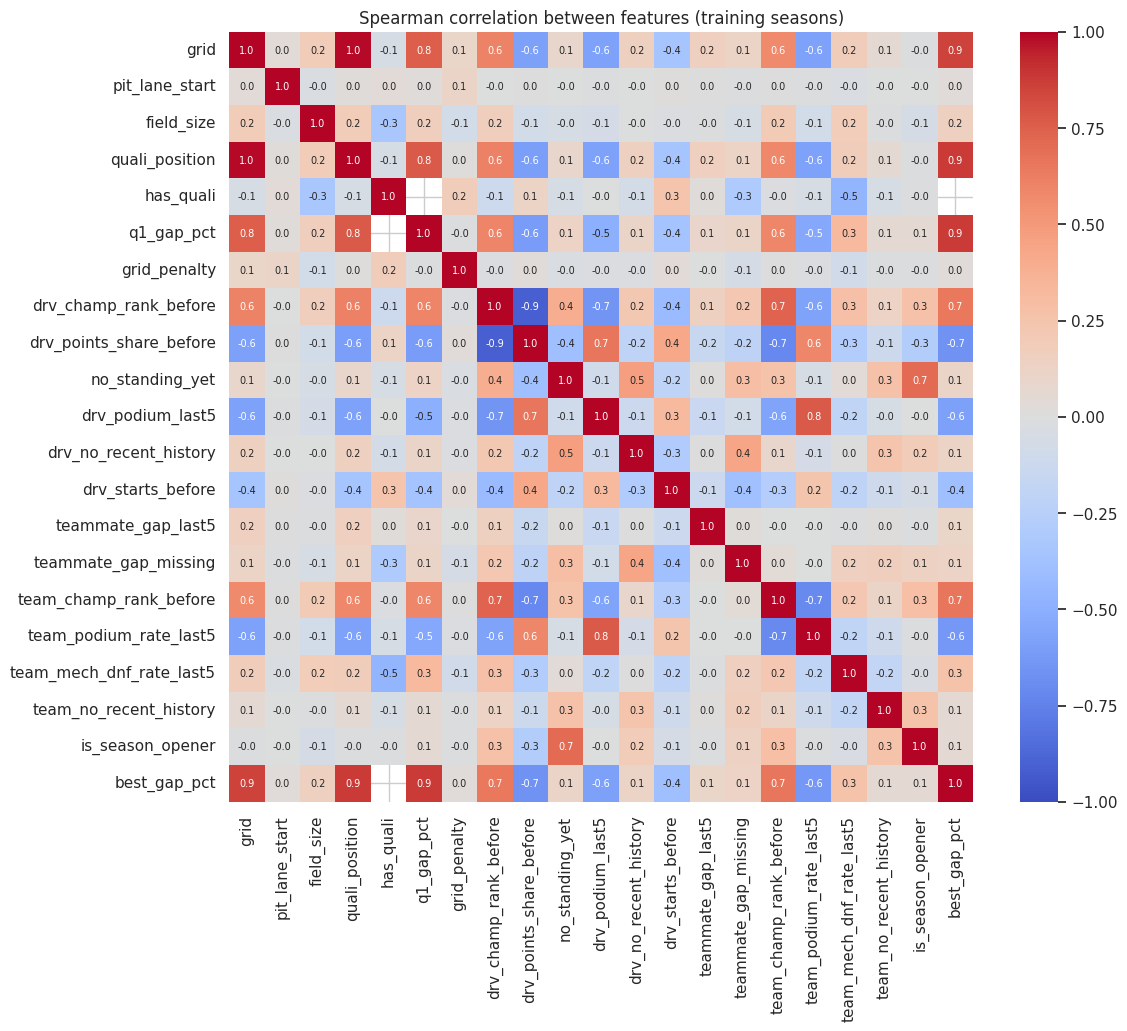

,,rho
grid,quali_position,0.99
drv_champ_rank_before,drv_points_share_before,-0.91
quali_position,best_gap_pct,0.88
q1_gap_pct,best_gap_pct,0.88
grid,best_gap_pct,0.86


In [233]:
# Redundancy: features that carry the same information (|corr| > 0.8) are candidates for the ablation
corr = train[num_feats].corr(method='spearman')
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt='.1f', annot_kws={'size': 7})
plt.title('Spearman correlation between features (training seasons)')
plt.show()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
         .rename('rho').loc[lambda s: s.abs() > 0.8].sort_values(key=abs, ascending=False))
pairs.round(2).to_frame()

> **Redundancy:** `grid` and `quali_position` are almost identical in training (ρ ≈ 0.99, partly because `quali_position` is filled from grid before 1994), and championship rank and points share mirror each other (ρ ≈ −0.9). Both pairs are kept. Each member adds something: `quali_position` carries penalty information beyond grid, and points share is comparable across points systems while rank is not. Permutation importance (15.1) shows the selected model uses both members of each pair.

In [234]:
features.to_pickle(os.path.join(OUT_DIR, 'features.pkl'))
print('Saved feature table:', features.shape, '->', OUT_DIR)

Saved feature table: (24588, 40) -> /kaggle/working/clean


## 13. Modeling

Four models are trained on **the same rows and the same features**, so their scores can be compared directly:

| Role | Model |
|---|---|
| Baseline (simplest reasonable model) | Logistic regression |
| Statistical ML model 1 | Random forest |
| Statistical ML model 2 | Gradient boosting (histogram-based) |
| Shallow neural network | MLP with 1–2 hidden layers |

A simple rule, "the front three on the grid finish on the podium", is added as a **reference line**. It is not a model, but any model worth its complexity must beat it.

**Rules followed in the whole section:** models are fitted on train (1950–2019). Every choice (imputation, hyperparameters, the probability threshold for F1) is made on validation (2020–21). The test set (2022–24) is used once, in the final comparison (13.8).

### 13.1 Metrics: primary and secondary

| Metric | What it measures | Role |
|---|---|---|
| **PR-AUC** | how well podium finishers are ranked above everyone else, over all thresholds | **primary** |
| **F1** | balance of precision and recall at one threshold (chosen on validation) | **secondary** |
| ROC-AUC | overall separation of the two classes | reported |
| Precision, recall | at the same threshold as F1 | reported |

**Why PR-AUC is primary:** only about 15% of rows are podiums. ROC-AUC rewards correctly ranking the many easy negatives (P18 on the grid), so it looks high even for weak predictors: the grid rule already scores about 0.91. PR-AUC focuses on the positive class, and a random guess scores only the podium rate (about 0.15), which the cell below checks.

**Why F1 is secondary:** PR-AUC does not depend on a threshold, but a real prediction needs one ("podium: yes/no"). F1 measures the quality of that decision. The threshold that maximises F1 is chosen on validation and reused unchanged on test.

In [235]:
import time
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, precision_score,
                             recall_score, precision_recall_curve, roc_curve, confusion_matrix, log_loss)
import sklearn
SEED = 42                      # every random model uses this seed, so Run All gives the same numbers
print('scikit-learn', sklearn.__version__, '(tree and neural-network results can shift slightly between versions)')

PARTS = ['train', 'val', 'test']
model_df = features[features['split'].isin(PARTS)]                    # 2025+ rows ('unused') are left out
D = {s: model_df[model_df['split'] == s].reset_index(drop=True) for s in PARTS}
Y = {s: D[s][TARGET].to_numpy() for s in PARTS}

def X_of(cols, part):
    return D[part][cols].astype(float)

pd.DataFrame({s: {'seasons': f"{D[s]['year'].min()}-{D[s]['year'].max()}", 'rows': len(D[s]),
                  'podiums': int(Y[s].sum()), 'podium rate': round(Y[s].mean(), 3)} for s in PARTS}).T

scikit-learn 1.6.1 (tree and neural-network results can shift slightly between versions)


,seasons,rows,podiums,podium rate
train,1950-2019,22455,3021,0.135
val,2020-2021,779,117,0.15
test,2022-2024,1354,204,0.151


In [236]:
def pick_threshold(y_true, p):
    # probability cut-off with the best F1, chosen on VALIDATION predictions only (never test)
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[np.argmax(f1)])

def evaluate(y_true, p, thr, part):
    pred = (p >= thr).astype(int)
    return {'PR-AUC': average_precision_score(y_true, p), 'ROC-AUC': roc_auc_score(y_true, p),
            'F1': f1_score(y_true, pred), 'precision': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred)}

# Sanity check of the metric code on the simplest possible predictor: always predict the base rate
p_const = np.full(len(Y['val']), Y['train'].mean())
print('constant predictor on validation: PR-AUC =', round(average_precision_score(Y['val'], p_const), 3),
      '(= podium rate), ROC-AUC =', roc_auc_score(Y['val'], p_const))

constant predictor on validation: PR-AUC = 0.15 (= podium rate), ROC-AUC = 0.5


### 13.2 Preprocessing pipeline

Only one feature still has missing values: `q1_gap_pct`, missing for about 64% of training rows (no qualifying times before 1994). The pipeline has two steps, and both are fitted on **training rows only**:

1. `GapImputer` fills the missing gap. The four strategies are compared in 13.3.
2. `StandardScaler` rescales every feature to mean 0 and standard deviation 1. Logistic regression and the neural network need this (a feature in the hundreds, like `drv_starts_before`, would otherwise dominate the weights). Tree models don't need it, but it doesn't change them, so all models share one pipeline.

Using a scikit-learn `Pipeline` makes leakage impossible by construction: `fit` only ever sees training rows, and validation and test are only passed through `transform`.

In [237]:
class GapImputer(BaseEstimator, TransformerMixin):
    # Fills the missing qualifying gap. Every fill value is learned in fit(), which the pipeline calls on
    # the TRAINING rows only, so validation and test never influence the values used to fill them.
    def __init__(self, strategy='median', col='q1_gap_pct'):
        self.strategy = strategy
        self.col = col

    def fit(self, X, y=None):
        gap = X[self.col]
        self.median_ = gap.median()
        self.slow_ = gap.quantile(0.95)
        known = X[gap.notna()]
        self.by_position_ = known.groupby(known['quali_position'].clip(upper=26))[self.col].median()
        return self

    def transform(self, X):
        X = X.copy()
        if self.strategy == 'drop':
            return X.drop(columns=self.col)
        miss = X[self.col].isna()
        if self.strategy == 'median':
            X.loc[miss, self.col] = self.median_
        elif self.strategy == 'slow':
            X.loc[miss, self.col] = self.slow_
        elif self.strategy == 'from_position':
            X.loc[miss, self.col] = (X.loc[miss, 'quali_position'].clip(upper=26)
                                     .map(self.by_position_).fillna(self.slow_))
        return X

def make_pipe(model, strategy, gap_col='q1_gap_pct'):
    # the same preprocessing for every model: fill the gap, then standardise (mean 0, std 1, fitted on train)
    return Pipeline([('impute_gap', GapImputer(strategy, gap_col)),
                     ('scale', StandardScaler().set_output(transform='pandas')),
                     ('model', model)])

# what each strategy learns from the training rows
g_ = GapImputer('from_position').fit(X_of(FEATURES, 'train'))
print('train median gap:', round(g_.median_, 3), '% | train 95th percentile:', round(g_.slow_, 3), '%')
g_.by_position_.head(10).round(3).rename('median gap % by qualifying position (train)').to_frame().T

train median gap: 1.502 % | train 95th percentile: 5.64 %


quali_position,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0
median gap % by qualifying position (train),0.0,0.348,0.555,0.696,0.83,1.044,1.116,1.245,1.325,1.308


### 13.3 Imputation experiment

The Piazza ruling asks for missing values to be handled experimentally. Four strategies, same model (logistic regression), scored on validation:

In [238]:
STRATEGIES = {
    'drop':          'remove the gap feature (no imputation)',
    'median':        'one value for everyone: the train median',
    'slow':          'one value for everyone: the train 95th percentile ("treat as slow")',
    'from_position': 'median gap of train drivers who qualified in the same position',
}
imp_rows, imp_filled = [], {}
for s, how in STRATEGIES.items():
    pipe = make_pipe(LogisticRegression(max_iter=2000), s).fit(X_of(FEATURES, 'train'), Y['train'])
    p_val = pipe.predict_proba(X_of(FEATURES, 'val'))[:, 1]
    imp_rows.append({'strategy': s, 'how missing gaps are filled': how,
                     **evaluate(Y['val'], p_val, pick_threshold(Y['val'], p_val), 'val')})
    if s != 'drop':
        imp_filled[s] = pipe.named_steps['impute_gap'].transform(X_of(FEATURES, 'train'))['q1_gap_pct']
imp_table = pd.DataFrame(imp_rows).set_index('strategy')
GAP_STRATEGY = imp_table['PR-AUC'].idxmax()
print('Chosen imputation (best validation PR-AUC, logistic regression):', GAP_STRATEGY)
imp_table.round(4)

Chosen imputation (best validation PR-AUC, logistic regression): from_position


,how missing gaps are filled,PR-AUC,ROC-AUC,F1,precision,recall
strategy,,,,,,
drop,remove the gap feature (no imputation),0.7223,0.9284,0.7045,0.6327,0.7949
median,one value for everyone: the train median,0.7198,0.9274,0.7132,0.6525,0.7863
slow,one value for everyone: the train 95th percent...,0.7213,0.9280,0.7132,0.6525,0.7863
from_position,median gap of train drivers who qualified in t...,0.7251,0.9288,0.7080,0.6178,0.8291


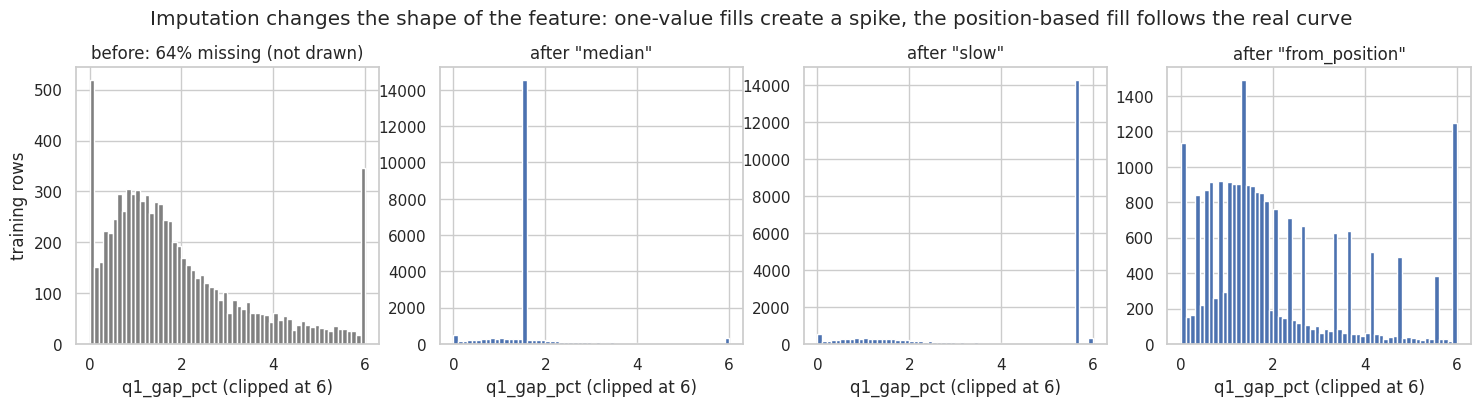

In [239]:
# Effect of each strategy on the distribution of q1_gap_pct in the TRAINING rows
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
raw = X_of(FEATURES, 'train')['q1_gap_pct']
bins = np.linspace(0, 6, 61)
axes[0].hist(raw.dropna().clip(upper=6), bins=bins, color='grey')
axes[0].set_title(f'before: {raw.isna().mean():.0%} missing (not drawn)')
for ax, (s, filled) in zip(axes[1:], imp_filled.items()):
    ax.hist(filled.clip(upper=6), bins=bins)
    ax.set_title(f'after "{s}"')
for ax in axes:
    ax.set_xlabel('q1_gap_pct (clipped at 6)')
axes[0].set_ylabel('training rows')
plt.suptitle('Imputation changes the shape of the feature: one-value fills create a spike, the position-based fill follows the real curve', y=1.04)
plt.show()

> **Reading the experiment:**
> - The scores are very close (PR-AUC ≈ 0.720–0.725). This is expected for two reasons. (1) Validation and test have qualifying data for almost every row, so imputation only changes what the model *learns* from the 1950–93 training rows. (2) The gap carries much of the same information as `quali_position` (ρ ≈ 0.88, section 12).
> - **Chosen: `from_position`.** It has the best validation PR-AUC, and the histograms give the second reason: one-value fills create a spike of about 14,000 identical values that no real driver ever had, while the position-based fill follows the real shape of the feature. A P1 qualifier without times gets gap 0, a P10 qualifier about 1.3%.

### 13.4 Experiment D14: Q1 gap vs best-of-Q1/Q2/Q3 gap

Section 12 showed `best_gap_pct` with a slightly higher raw correlation with podium. Here both versions are put into the full pipeline with two different models, so the conclusion does not depend on one model.

In [240]:
# D14: gap to the fastest Q1 time vs gap using each driver's best of Q1/Q2/Q3, tested with two different models
d14_rows, d14_probs = [], {}
for gap_col in ['q1_gap_pct', ALT_QUALI_GAP]:
    cols = [gap_col if c == 'q1_gap_pct' else c for c in FEATURES]
    for name, m in [('logistic regression', LogisticRegression(max_iter=2000)),
                    ('gradient boosting (default settings)', HistGradientBoostingClassifier(random_state=SEED))]:
        pipe = make_pipe(m, GAP_STRATEGY, gap_col).fit(X_of(cols, 'train'), Y['train'])
        p_val = pipe.predict_proba(X_of(cols, 'val'))[:, 1]
        d14_probs[(gap_col, name)] = p_val
        d14_rows.append({'gap feature': gap_col, 'model': name,
                         **evaluate(Y['val'], p_val, pick_threshold(Y['val'], p_val), 'val')})
d14_table = pd.DataFrame(d14_rows).set_index(['gap feature', 'model'])
mean_pr = d14_table['PR-AUC'].groupby(level=0).mean()

# Decision rule: D14 planned the Q1 gap. Switch only if best-of-3 is CLEARLY better: resample whole validation
# races 1,000 times; if the 95% interval of (best-of-3 minus Q1, averaged over both models) contains 0, keep Q1.
rng = np.random.default_rng(SEED)
race_ids = D['val']['raceId'].to_numpy()
idx_by_race = {r: np.flatnonzero(race_ids == r) for r in np.unique(race_ids)}
model_names = d14_table.index.get_level_values('model').unique()
diffs = []
for _ in range(1000):
    d = np.concatenate([idx_by_race[r] for r in rng.choice(list(idx_by_race), len(idx_by_race))])
    diffs.append(np.mean([average_precision_score(Y['val'][d], d14_probs[(ALT_QUALI_GAP, m)][d])
                          - average_precision_score(Y['val'][d], d14_probs[('q1_gap_pct', m)][d]) for m in model_names]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
GAP_COL = ALT_QUALI_GAP if (lo > 0 and GAP_STRATEGY != 'drop') else 'q1_gap_pct'
MODEL_FEATURES = [GAP_COL if c == 'q1_gap_pct' else c for c in FEATURES]
print('Average validation PR-AUC:', mean_pr.round(4).to_dict())
print(f'best-of-3 minus Q1: {mean_pr[ALT_QUALI_GAP] - mean_pr["q1_gap_pct"]:+.4f}, 95% interval [{lo:+.4f}, {hi:+.4f}]'
      f' -> chosen gap feature: {GAP_COL}')
d14_table.round(4)

Average validation PR-AUC: {'best_gap_pct': 0.7188, 'q1_gap_pct': 0.7158}
best-of-3 minus Q1: +0.0030, 95% interval [-0.0115, +0.0163] -> chosen gap feature: q1_gap_pct


PR-AUC  ROC-AUC      F1  \
gap feature  model                                                           
q1_gap_pct   logistic regression                   0.7251   0.9288  0.7080   
             gradient boosting (default settings)  0.7065   0.9275  0.7059   
best_gap_pct logistic regression                   0.7228   0.9286  0.7072   
             gradient boosting (default settings)  0.7148   0.9252  0.7160   

                                                   precision  recall  
gap feature  model                                                    
q1_gap_pct   logistic regression                      0.6178  0.8291  
             gradient boosting (default settings)     0.6942  0.7179  
best_gap_pct logistic regression                      0.6370  0.7949  
             gradient boosting (default settings)     0.6905  0.7436

> **Reading:**
> - The two versions are practically tied: the difference is a few thousandths of PR-AUC, and its sign even flips between scikit-learn versions (Q1 won on one of our runs, best-of-3 on another). The 95% bootstrap interval contains 0.
> - Best-of-3's higher raw correlation (section 12) does not carry into the model, because the model already has `quali_position` and best-of-3 mostly repeats it (ρ ≈ 0.88 with position).
> - **Decision rule: a planned decision is changed only on clear evidence.** So D14 stays `q1_gap_pct`, which also has the better definition: it compares **every** driver in the same session and conditions, while best-of-3 compares the top 10's Q3 laps (a faster, rubbered-in track) with the others' Q1 laps.

### 13.5 Preprocessing-order experiments

The brief asks for at least two experiments where only the **order** of preprocessing steps changes.

**Experiment 1: fit the imputer and scaler before or after the split.** "Before" means the fill values and scaling are computed from all seasons, test included: a leak.

In [241]:
# Preprocessing-order experiment 1: fit the imputer + scaler BEFORE the split (on all seasons) or AFTER it (train only)
def fit_transform_manual(fit_rows, cols, strategy, gap_col):
    imp = GapImputer(strategy, gap_col).fit(fit_rows)
    sc = StandardScaler().set_output(transform='pandas').fit(imp.transform(fit_rows))
    return imp, sc, {s: sc.transform(imp.transform(X_of(cols, s))) for s in PARTS}

def lr_scores(T, label, extra):
    m = LogisticRegression(max_iter=2000).fit(T['train'], Y['train'])
    p = {s: m.predict_proba(T[s])[:, 1] for s in ['val', 'test']}
    thr = pick_threshold(Y['val'], p['val'])
    ev = {s: evaluate(Y[s], p[s], thr, s) for s in ['val', 'test']}
    return {'order': label, **extra, 'val PR-AUC': ev['val']['PR-AUC'], 'test PR-AUC': ev['test']['PR-AUC'],
            'val F1': ev['val']['F1'], 'test F1': ev['test']['F1']}

X_all = pd.concat([X_of(FEATURES, s) for s in PARTS])
o1_rows = []
for label, rows_ in [('after split: fit on train only (used)', X_of(FEATURES, 'train')),
                     ('before split: fit on all seasons (leaky)', X_all)]:
    imp, sc, T = fit_transform_manual(rows_, FEATURES, 'median', 'q1_gap_pct')
    gi = list(sc.feature_names_in_).index('q1_gap_pct')
    o1_rows.append(lr_scores(T, label, {'gap fill value (median, %)': imp.median_,
                                        'scaler mean of gap': sc.mean_[gi], 'scaler std of gap': np.sqrt(sc.var_[gi])}))
order1 = pd.DataFrame(o1_rows).set_index('order')
order1.round(4)

,"gap fill value (median, %)",scaler mean of gap,scaler std of gap,val PR-AUC,test PR-AUC,val F1,test F1
order,,,,,,,
after split: fit on train only (used),1.5024,1.6925,1.2305,0.7198,0.7122,0.7132,0.6795
before split: fit on all seasons (leaky),1.3444,1.5576,1.2766,0.7206,0.7120,0.7181,0.6820


> **Reading:** the leaky order changes what is learned. The median gap drops from about 1.50% to 1.34%, because 2020–24 qualifying is closer than the long-term average. That value comes partly from the **test** seasons. The scores barely move (± 0.001–0.005), because imputation mostly affects old training rows. The correct order is still the rule: a pipeline that uses test information cannot be trusted, even when it happens to change little.

**Experiment 2: impute then scale, or scale then impute.** Missing gaps are filled with 0 in both B and C; only the order differs.

,missing gaps become (scaled),P1 driver with real data (scaled),val PR-AUC,test PR-AUC,val F1,test F1
order,,,,,,
A: median-impute -> scale (used),-0.1545,-1.3754,0.7198,0.7122,0.7132,0.6795
B: scale -> fill 0,0.0000,-1.0145,0.7203,0.7117,0.7132,0.6795
C: fill 0 -> scale,-0.4763,-0.4763,0.7196,0.7119,0.7132,0.6765


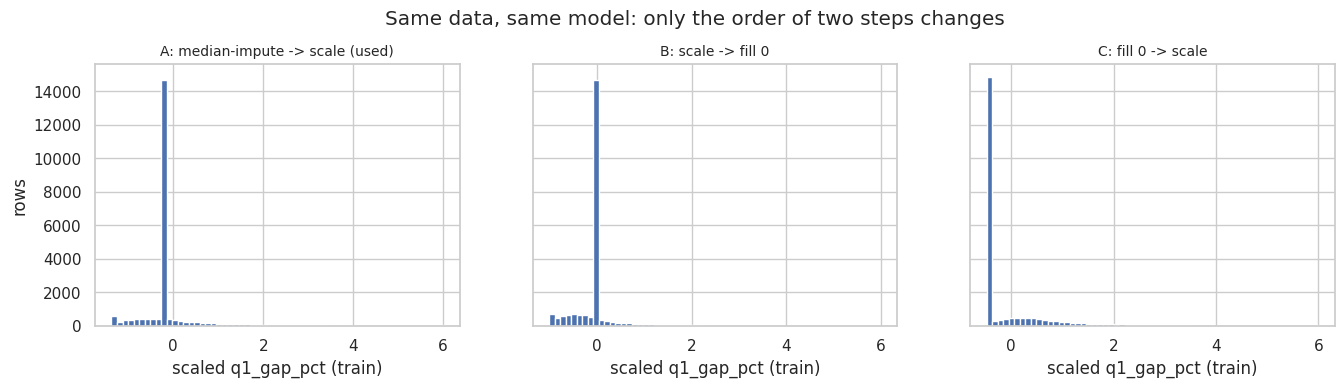

In [242]:
# Preprocessing-order experiment 2: impute THEN scale, or scale THEN impute (missing gaps filled with 0 in both)
Xtr, Xva, Xte = (X_of(FEATURES, s) for s in PARTS)
variants = {}
# A) impute (median) -> scale   : the order used in the pipeline
imp, sc, variants['A: median-impute -> scale (used)'] = fit_transform_manual(Xtr, FEATURES, 'median', 'q1_gap_pct')
# B) scale -> impute 0           : StandardScaler ignores NaN when fitting; 0 after scaling = the train mean gap
sc_b = StandardScaler().set_output(transform='pandas').fit(Xtr)
variants['B: scale -> fill 0'] = {s: sc_b.transform(X_of(FEATURES, s)).fillna(0) for s in PARTS}
# C) impute 0 -> scale           : 0 before scaling = '0 % slower than pole' for every driver without data
sc_c = StandardScaler().set_output(transform='pandas').fit(Xtr.fillna({'q1_gap_pct': 0}))
variants['C: fill 0 -> scale'] = {s: sc_c.transform(X_of(FEATURES, s).fillna({'q1_gap_pct': 0})) for s in PARTS}

o2_rows = []
for label, T in variants.items():
    g = T['train']['q1_gap_pct']
    o2_rows.append(lr_scores(T, label, {'missing gaps become (scaled)': g[Xtr['q1_gap_pct'].isna().values].iloc[0],
                                        'P1 driver with real data (scaled)': g[(Xtr['q1_gap_pct'] == 0).values].iloc[0]}))
order2 = pd.DataFrame(o2_rows).set_index('order')
display(order2.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.4), sharey=True)
for ax, (label, T) in zip(axes, variants.items()):
    ax.hist(T['train']['q1_gap_pct'].clip(-3, 6), bins=60)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel('scaled q1_gap_pct (train)')
axes[0].set_ylabel('rows')
plt.suptitle('Same data, same model: only the order of two steps changes', y=1.04)
plt.show()

> **Reading:**
> - The order changes the meaning of the filled value. In **C** (fill 0, then scale), every driver without qualifying times becomes exactly as fast as a pole sitter: both get the same scaled value (≈ −0.48), so the feature can no longer tell "no data" from "fastest". In **B** (scale, then fill 0), the 0 means "the average gap", which is a neutral value. **A** (our pipeline) also uses a neutral value.
> - The scores are almost identical. There are three reasons: the `has_quali` flag tells the model which rows are filled; validation and test have no missing gaps; and logistic regression gives the gap a small weight (it repeats `quali_position`).
> - **Conclusion of both experiments:** the order matters for correctness (no leakage, filled values that mean something), and the plots show the change in the data. On this dataset the effect on the scores is small, and we report that honestly rather than claim a gain.

### 13.6 How each model works, and its limitations

| Model | How it works | Limitations for this task |
|---|---|---|
| **Logistic regression** (baseline) | Weighted sum of the standardised features, passed through a sigmoid to get a probability between 0 and 1. The weights are learned by minimising log-loss; `C` controls how strongly large weights are penalised. | Linear and additive: it cannot learn that grid matters less in the 1950s than today unless that is built into a feature. Correlated features (grid and `quali_position`) make single coefficients unstable, so their signs cannot be read as effects. `era_index` = 8 (test) is outside the training range (0–7), so its effect is extrapolated linearly. |
| **Random forest** | Many decision trees, each trained on a bootstrap sample of rows and a random subset of features at each split. The probability is the average vote of the trees. | Cannot extrapolate: for an unseen era or reliability level it behaves like the nearest values seen in training. Coarser probabilities. Slower to train. |
| **Gradient boosting** | Trees built one after another, each one correcting the errors of the trees before it, with a small learning rate. Features are binned into histograms (fast), and early stopping picks the number of trees. | Many hyperparameters; overfits easily (big trees reach high train scores but lower validation, see 13.7). Same extrapolation limit as the forest. |
| **Shallow NN (MLP)** | The 21 inputs feed one or two hidden layers of ReLU units, then a sigmoid output. Weights are learned with the Adam optimiser on log-loss; `alpha` is an L2 penalty; early stopping ends training when an internal validation score stops improving. | The result depends on the random starting weights (shown in 13.7). Needs scaled inputs. The hardest of the four to explain, which is why XAI (section 15) matters most for it. |

### 13.7 Hyperparameter tuning (on validation only)

Each model gets a grid of settings. Every setting is fitted on train and scored by **validation PR-AUC**; the best one is kept. The grids are wide enough that the chosen value is not at the edge of the grid, except where the score flattens out. For the neural network, every setting is trained with **3 different seeds** and scored by the average, so a lucky starting point cannot win.

In [243]:
XM = {s: X_of(MODEL_FEATURES, s) for s in PARTS}

def tune(make_model, grid, label, seeds=(SEED,)):
    # fit every setting on TRAIN, score on VALIDATION; the test set is not touched here.
    # With several seeds, a setting is scored by its AVERAGE over the seeds (so a lucky start cannot win).
    rows, best = [], (-1.0, None, None)
    for params in ParameterGrid(grid):
        t0 = time.time()
        ap_tr, ap_va = [], []
        for seed in seeds:
            pipe = make_pipe(make_model(random_state=seed, **params), GAP_STRATEGY, GAP_COL).fit(XM['train'], Y['train'])
            ap_tr.append(average_precision_score(Y['train'], pipe.predict_proba(XM['train'])[:, 1]))
            ap_va.append(average_precision_score(Y['val'], pipe.predict_proba(XM['val'])[:, 1]))
        rows.append({**{k: str(v) for k, v in params.items()}, 'train PR-AUC': np.mean(ap_tr),
                     'val PR-AUC': np.mean(ap_va), 'val PR-AUC std (seeds)': np.std(ap_va),
                     'seconds': time.time() - t0})
        if np.mean(ap_va) > best[0]:
            if len(seeds) > 1:      # keep the winning setting fitted with the first tuning seed
                pipe = make_pipe(make_model(random_state=seeds[0], **params), GAP_STRATEGY, GAP_COL).fit(XM['train'], Y['train'])
            best = (np.mean(ap_va), params, pipe)
    res = pd.DataFrame(rows).sort_values('val PR-AUC', ascending=False).reset_index(drop=True)
    if len(seeds) == 1:
        res = res.drop(columns='val PR-AUC std (seeds)')
    print(f'{label}: {len(rows)} settings tried, best validation PR-AUC = {best[0]:.4f} with {best[1]}')
    return best[2], best[1], res

#### Logistic regression (baseline)

Logistic regression: 12 settings tried, best validation PR-AUC = 0.7251 with {'C': 10, 'class_weight': None}


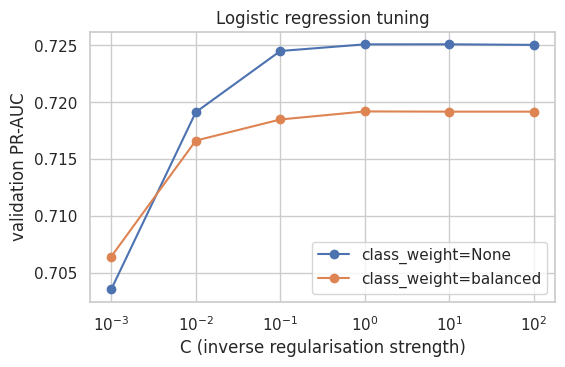

,coefficient (per 1 std of the feature)
quali_position,-0.885
grid,-0.847
team_podium_rate_last5,0.236
team_champ_rank_before,-0.192
drv_points_share_before,0.153
is_season_opener,0.152
era_index,-0.147
drv_podium_last5,0.130
q1_gap_pct,0.121
drv_starts_before,0.090


In [244]:
best_lr, lr_params, lr_res = tune(lambda **p: LogisticRegression(max_iter=3000, **p),
                                  {'C': [0.001, 0.01, 0.1, 1, 10, 100], 'class_weight': [None, 'balanced']},
                                  'Logistic regression')
fig, ax = plt.subplots(figsize=(6, 3.5))
for cw, g in lr_res.assign(C=lr_res['C'].astype(float)).sort_values('C').groupby('class_weight'):
    ax.plot(g['C'], g['val PR-AUC'], marker='o', label=f'class_weight={cw}')
ax.set_xscale('log'); ax.set_xlabel('C (inverse regularisation strength)'); ax.set_ylabel('validation PR-AUC')
ax.set_title('Logistic regression tuning'); ax.legend(); plt.show()

coef = pd.Series(best_lr.named_steps['model'].coef_[0], index=best_lr.named_steps['scale'].feature_names_in_)
coef.sort_values(key=abs, ascending=False).round(3).rename('coefficient (per 1 std of the feature)').to_frame()

> **Reading:** regularisation hardly matters once `C` ≥ 0.1, because there are 22,000 training rows for 21 features. `class_weight='balanced'` is slightly *worse* on PR-AUC: it shifts all probabilities up but does not improve the ranking, and the imbalance is already handled by choosing the F1 threshold on validation. The coefficients confirm grid and qualifying position dominate. The small **positive** sign of `q1_gap_pct` ("slower = more podiums") is a collinearity artefact: the gap and the position carry the same information, so the model splits the weight between them oddly. It is an example of why coefficients are not causal effects.

#### Random forest and gradient boosting

In [245]:
best_rf, rf_params, rf_res = tune(lambda **p: RandomForestClassifier(n_estimators=300, n_jobs=-1, **p),
                                  {'max_depth': [4, 6, 10, 16], 'min_samples_leaf': [5, 20, 50],
                                   'max_features': ['sqrt', 0.5]},
                                  'Random forest')
rf_res.head(8).round(4)

Random forest: 24 settings tried, best validation PR-AUC = 0.7309 with {'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 5}


,max_depth,max_features,min_samples_leaf,train PR-AUC,val PR-AUC,seconds
0,6,sqrt,5,0.6131,0.7309,2.0502
1,6,0.5,50,0.6093,0.7297,3.3238
2,16,sqrt,50,0.6156,0.7290,2.7020
3,6,sqrt,50,0.6006,0.7280,2.0261
4,6,0.5,20,0.6186,0.7276,3.3351
5,10,sqrt,20,0.6582,0.7271,2.6173
6,6,sqrt,20,0.6075,0.7266,2.1705
7,10,sqrt,50,0.6148,0.7257,2.5424


In [246]:
best_hgb, hgb_params, hgb_res = tune(lambda **p: HistGradientBoostingClassifier(max_iter=500, early_stopping=True,
                                                                               validation_fraction=0.1,
                                                                               n_iter_no_change=30,
                                                                               **p),
                                     {'learning_rate': [0.01, 0.03, 0.1], 'max_leaf_nodes': [7, 15, 31, 63],
                                      'min_samples_leaf': [20, 100], 'l2_regularization': [0.0, 1.0]},
                                     'Gradient boosting')
hgb_res.head(8).round(4)

Gradient boosting: 48 settings tried, best validation PR-AUC = 0.7285 with {'l2_regularization': 0.0, 'learning_rate': 0.01, 'max_leaf_nodes': 63, 'min_samples_leaf': 20}


,l2_regularization,learning_rate,max_leaf_nodes,min_samples_leaf,train PR-AUC,val PR-AUC,seconds
0,0.0,0.01,63,20,0.7264,0.7285,4.1168
1,0.0,0.01,31,20,0.6684,0.7207,3.4559
2,1.0,0.03,15,20,0.6552,0.7200,1.5203
3,0.0,0.03,15,20,0.6437,0.7199,1.3558
4,1.0,0.1,31,20,0.7189,0.7196,0.6659
5,1.0,0.03,31,20,0.6770,0.7189,1.3773
6,0.0,0.01,15,20,0.6198,0.7185,2.4790
7,1.0,0.01,31,20,0.6658,0.7175,3.5127


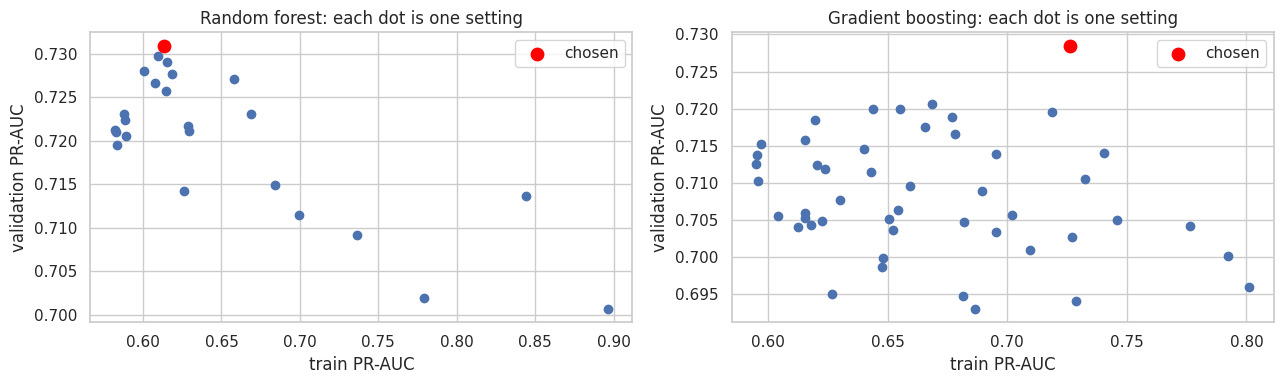

In [247]:
# Overfitting check for the two tree models: train vs validation PR-AUC for every setting tried
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (res, title) in zip(axes, [(rf_res, 'Random forest'), (hgb_res, 'Gradient boosting')]):
    ax.scatter(res['train PR-AUC'], res['val PR-AUC'])
    b = res.iloc[0]
    ax.scatter([b['train PR-AUC']], [b['val PR-AUC']], color='red', s=80, label='chosen')
    ax.set_xlabel('train PR-AUC'); ax.set_ylabel('validation PR-AUC'); ax.set_title(title + ': each dot is one setting')
    ax.legend()
plt.tight_layout(); plt.show()

> **Reading:** the settings that fit training best (right side of each plot: deep forest trees, big boosting trees) are **not** the best on validation. That is overfitting: the model memorises training seasons. The chosen settings are the restrained ones: shallow forest trees (depth 4–6) and small boosting trees with a small learning rate and early stopping.

#### Shallow neural network

Shallow NN: 72 settings tried, best validation PR-AUC = 0.7262 with {'alpha': 0.0001, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': 0.01}


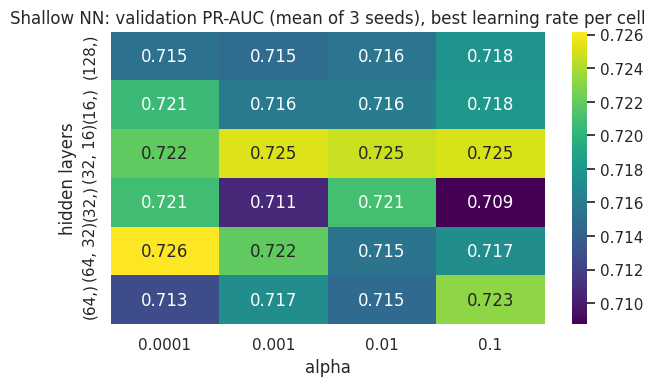

,alpha,hidden_layer_sizes,learning_rate_init,train PR-AUC,val PR-AUC,val PR-AUC std (seeds),seconds
0,0.0001,"(64, 32)",0.01,0.5934,0.7262,0.0043,9.3916
1,0.001,"(32, 16)",0.001,0.5930,0.7253,0.0132,11.8274
2,0.1,"(32, 16)",0.001,0.5949,0.7251,0.0136,14.5714
3,0.01,"(32, 16)",0.001,0.5988,0.7247,0.0139,14.3024
4,0.1,"(64,)",0.001,0.5908,0.7232,0.0070,11.6908
5,0.001,"(64, 32)",0.01,0.5855,0.7220,0.0057,8.0314
6,0.0001,"(32, 16)",0.01,0.5863,0.7220,0.0040,7.0670
7,0.0001,"(32, 16)",0.001,0.5971,0.7216,0.0185,12.9653


In [248]:
mlp_grid = {'hidden_layer_sizes': [(16,), (32,), (64,), (128,), (32, 16), (64, 32)],
            'alpha': [1e-4, 1e-3, 1e-2, 1e-1],
            'learning_rate_init': [3e-4, 1e-3, 1e-2]}
best_mlp, mlp_params, mlp_res = tune(lambda **p: MLPClassifier(activation='relu', solver='adam', batch_size=256,
                                                               max_iter=300, early_stopping=True,
                                                               validation_fraction=0.1, n_iter_no_change=15,
                                                               **p),
                                     mlp_grid, 'Shallow NN', seeds=(0, 1, 2))
heat = mlp_res.pivot_table(index='hidden_layer_sizes', columns='alpha', values='val PR-AUC', aggfunc='max')
heat.columns = [f'{float(a):g}' for a in heat.columns]
plt.figure(figsize=(7, 3.8))
sns.heatmap(heat, annot=True, fmt='.3f', cmap='viridis')
plt.title('Shallow NN: validation PR-AUC (mean of 3 seeds), best learning rate per cell')
plt.xlabel('alpha'); plt.ylabel('hidden layers'); plt.show()
mlp_res.head(8).round(4)

seed,0,1,2,3,4,42
val PR-AUC,0.7307,0.7276,0.7203,0.738,0.7208,0.6776
epochs before early stop,30.0000,27.0000,25.0000,25.000,25.0000,34.0000


one network, 6 different seeds: validation PR-AUC from 0.678 to 0.738
5-network average, validation PR-AUC: 0.7256


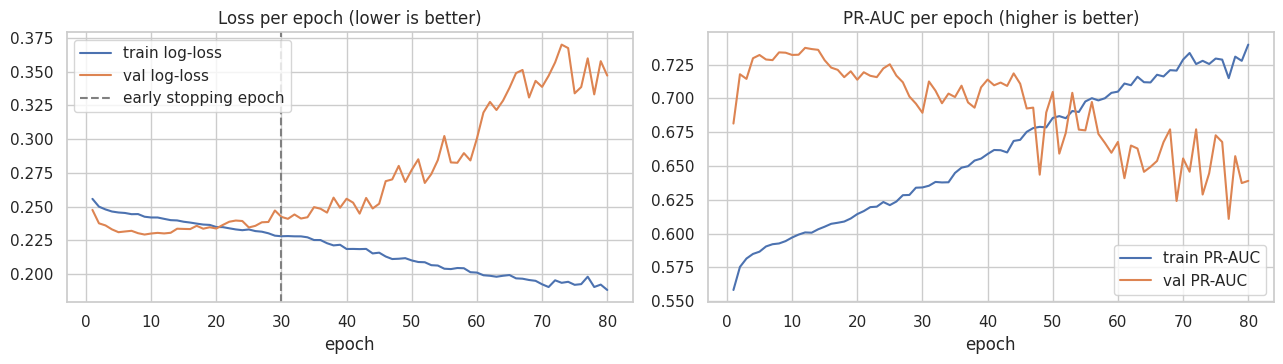

In [249]:
# A neural network's result depends on its random starting weights. Re-train the chosen setting with 5 seeds:
# if the spread is small, the tuning result is real and not a lucky initialisation.
seed_rows = []
for seed in [0, 1, 2, 3, 4, SEED]:
    m = clone(best_mlp).set_params(model__random_state=seed).fit(XM['train'], Y['train'])
    seed_rows.append({'seed': seed, 'val PR-AUC': average_precision_score(Y['val'], m.predict_proba(XM['val'])[:, 1]),
                      'epochs before early stop': m.named_steps['model'].n_iter_})
seeds_df = pd.DataFrame(seed_rows).set_index('seed')
display(seeds_df.round(4).T)
print(f"one network, 6 different seeds: validation PR-AUC from {seeds_df['val PR-AUC'].min():.3f} to {seeds_df['val PR-AUC'].max():.3f}")

# One network is a noisy draw, so the final NN averages the probabilities of 5 networks (seeds 0-4) with the
# chosen setting. Same architecture, same data; only the random start differs.
class SeedAveragedMLP(BaseEstimator, ClassifierMixin):
    def __init__(self, params=None, seeds=(0, 1, 2, 3, 4)):
        self.params = params
        self.seeds = seeds
    def fit(self, X, y):
        params = {k: v for k, v in self.params.items() if k != 'random_state'}
        self.nets_ = [MLPClassifier(**params, random_state=s).fit(X, y) for s in self.seeds]
        self.classes_ = self.nets_[0].classes_
        return self
    def predict_proba(self, X):
        return np.mean([n.predict_proba(X) for n in self.nets_], axis=0)
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

mlp_final_params = best_mlp.named_steps['model'].get_params()
best_mlp_avg = make_pipe(SeedAveragedMLP(mlp_final_params), GAP_STRATEGY, GAP_COL).fit(XM['train'], Y['train'])
print('5-network average, validation PR-AUC:',
      round(average_precision_score(Y['val'], best_mlp_avg.predict_proba(XM['val'])[:, 1]), 4))

# Training curve of the chosen network, epoch by epoch, on the real validation seasons
prep = Pipeline(best_mlp.steps[:-1])                      # the already-fitted imputer + scaler
T_tr, T_va = prep.transform(XM['train']), prep.transform(XM['val'])
net = MLPClassifier(**{k: v for k, v in mlp_params.items()}, activation='relu', solver='adam',
                    batch_size=256, random_state=0)
curve = []
for epoch in range(1, 81):
    net.partial_fit(T_tr, Y['train'], classes=[0, 1])
    p_tr, p_va = net.predict_proba(T_tr)[:, 1], net.predict_proba(T_va)[:, 1]
    curve.append({'epoch': epoch, 'train log-loss': log_loss(Y['train'], p_tr), 'val log-loss': log_loss(Y['val'], p_va),
                  'train PR-AUC': average_precision_score(Y['train'], p_tr),
                  'val PR-AUC': average_precision_score(Y['val'], p_va)})
curve = pd.DataFrame(curve).set_index('epoch')
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
curve[['train log-loss', 'val log-loss']].plot(ax=axes[0], title='Loss per epoch (lower is better)')
curve[['train PR-AUC', 'val PR-AUC']].plot(ax=axes[1], title='PR-AUC per epoch (higher is better)')
axes[0].axvline(best_mlp.named_steps['model'].n_iter_, ls='--', color='grey', label='early stopping epoch')
axes[0].legend(); plt.tight_layout(); plt.show()

> **Reading:**
> - **Architecture:** the spread between architectures is about the same size as the spread between seeds (std ≈ 0.005–0.02), so no architecture is clearly better. The chosen setting has the best 3-seed average.
> - **Seeds:** networks with the same setting differ by about 0.03–0.06 validation PR-AUC depending only on their random start (see the seed table). A single network is therefore a noisy draw, and the final NN averages 5 networks (seeds 0–4): same architecture and data, more stable probabilities.
> - **Training curve:** validation loss is lowest in the first 10–20 epochs and then rises while training loss keeps falling. That is overfitting, and it is why early stopping is used (it stops around epoch 25–35).

### 13.8 Final comparison: validation and the unseen test set

The test set is used here for the first time. Thresholds come from validation.

In [250]:
MODELS = {'Logistic regression (baseline)': best_lr, 'Random forest': best_rf,
          'Gradient boosting': best_hgb, 'Shallow NN (MLP)': best_mlp_avg}
PROBS = {name: {s: m.predict_proba(XM[s])[:, 1] for s in PARTS} for name, m in MODELS.items()}
THRESHOLDS = {name: pick_threshold(Y['val'], PROBS[name]['val']) for name in MODELS}   # validation only

rows = []
for name in MODELS:
    for s in PARTS:
        rows.append({'model': name, 'part': s, 'threshold': THRESHOLDS[name],
                     **evaluate(Y[s], PROBS[name][s], THRESHOLDS[name], s)})
# Reference rule, not a model: 'the front three on the grid finish on the podium'
for s in PARTS:
    rows.append({'model': 'Rule: grid <= 3 (reference)', 'part': s, 'threshold': np.nan,
                 **evaluate(Y[s], 1.0 / D[s]['grid'].to_numpy(), 1 / 3, s)})
comparison = pd.DataFrame(rows).set_index(['model', 'part'])
comparison.round(3)

threshold  PR-AUC  ROC-AUC     F1  \
model                          part                                       
Logistic regression (baseline) train      0.210   0.565    0.900  0.582   
                               val        0.210   0.725    0.929  0.708   
                               test       0.210   0.711    0.936  0.673   
Random forest                  train      0.402   0.613    0.912  0.583   
                               val        0.402   0.731    0.930  0.707   
                               test       0.402   0.725    0.942  0.662   
Gradient boosting              train      0.368   0.726    0.948  0.675   
                               val        0.368   0.729    0.927  0.709   
                               test       0.368   0.723    0.937  0.680   
Shallow NN (MLP)               train      0.215   0.599    0.911  0.589   
                               val        0.215   0.726    0.930  0.706   
                               test       0.215   0.706    0.937  0.679   
Rule: grid <= 3 (reference)    train        NaN   0.499    0.883  0.544   
                               val          NaN   0.639    0.909  0.692   
                               test         NaN   0.647    0.914  0.649   

                                      precision  recall  
model                          part                      
Logistic regression (baseline) train      0.464   0.782  
                               val        0.618   0.829  
                               test       0.542   0.887  
Random forest                  train      0.598   0.569  
                               val        0.713   0.701  
                               test       0.648   0.676  
Gradient boosting              train      0.644   0.710  
                               val        0.709   0.709  
                               test       0.641   0.725  
Shallow NN (MLP)               train      0.463   0.809  
                               val        0.652   0.769  
                               test       0.591   0.799  
Rule: grid <= 3 (reference)    train      0.545   0.543  
                               val        0.692   0.692  
                               test       0.650   0.647

In [251]:
# The deliverable table: every metric on validation and on the unseen test set
wide = comparison.drop(columns='threshold').unstack('part').swaplevel(axis=1).sort_index(axis=1)
wide = wide[['val', 'test']].reindex(list(MODELS) + ['Rule: grid <= 3 (reference)'])
display(wide.round(3))
gap = (comparison.xs('val', level='part')['PR-AUC'] - comparison.xs('test', level='part')['PR-AUC'])
train_val = (comparison.xs('train', level='part')['PR-AUC'] - comparison.xs('val', level='part')['PR-AUC'])
pd.DataFrame({'train - val PR-AUC (overfitting)': train_val, 'val - test PR-AUC (does tuning transfer?)': gap}).round(3)

part                              val                                   test  \
                                   F1 PR-AUC ROC-AUC precision recall     F1   
model                                                                          
Logistic regression (baseline)  0.708  0.725   0.929     0.618  0.829  0.673   
Random forest                   0.707  0.731   0.930     0.713  0.701  0.662   
Gradient boosting               0.709  0.729   0.927     0.709  0.709  0.680   
Shallow NN (MLP)                0.706  0.726   0.930     0.652  0.769  0.679   
Rule: grid <= 3 (reference)     0.692  0.639   0.909     0.692  0.692  0.649   

part                                                            
                               PR-AUC ROC-AUC precision recall  
model                                                           
Logistic regression (baseline)  0.711   0.936     0.542  0.887  
Random forest                   0.725   0.942     0.648  0.676  
Gradient boosting               0.723   0.937     0.641  0.725  
Shallow NN (MLP)                0.706   0.937     0.591  0.799  
Rule: grid <= 3 (reference)     0.647   0.914     0.650  0.647

,train - val PR-AUC (overfitting),val - test PR-AUC (does tuning transfer?)
model,,
Logistic regression (baseline),-0.160,0.014
Random forest,-0.118,0.006
Gradient boosting,-0.002,0.006
Shallow NN (MLP),-0.127,0.019
Rule: grid <= 3 (reference),-0.140,-0.009


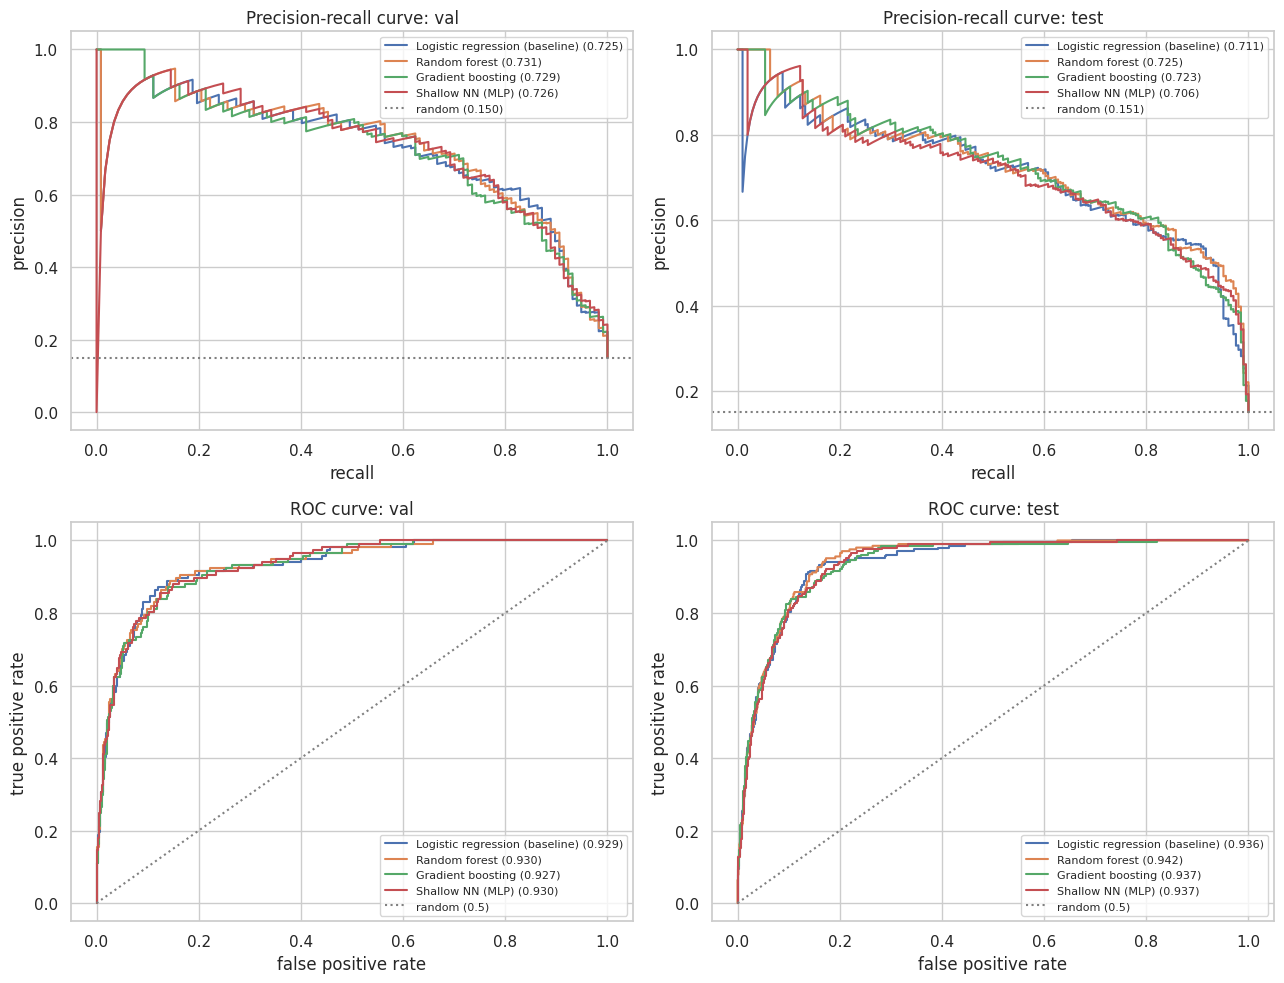

In [252]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for col, s in enumerate(['val', 'test']):
    for name in MODELS:
        p = PROBS[name][s]
        prec, rec, _ = precision_recall_curve(Y[s], p)
        fpr, tpr, _ = roc_curve(Y[s], p)
        axes[0, col].plot(rec, prec, label=f'{name} ({average_precision_score(Y[s], p):.3f})')
        axes[1, col].plot(fpr, tpr, label=f'{name} ({roc_auc_score(Y[s], p):.3f})')
    axes[0, col].axhline(Y[s].mean(), ls=':', color='grey', label=f'random ({Y[s].mean():.3f})')
    axes[1, col].plot([0, 1], [0, 1], ls=':', color='grey', label='random (0.5)')
    axes[0, col].set(title=f'Precision-recall curve: {s}', xlabel='recall', ylabel='precision')
    axes[1, col].set(title=f'ROC curve: {s}', xlabel='false positive rate', ylabel='true positive rate')
    axes[0, col].legend(fontsize=8); axes[1, col].legend(fontsize=8)
plt.tight_layout(); plt.show()

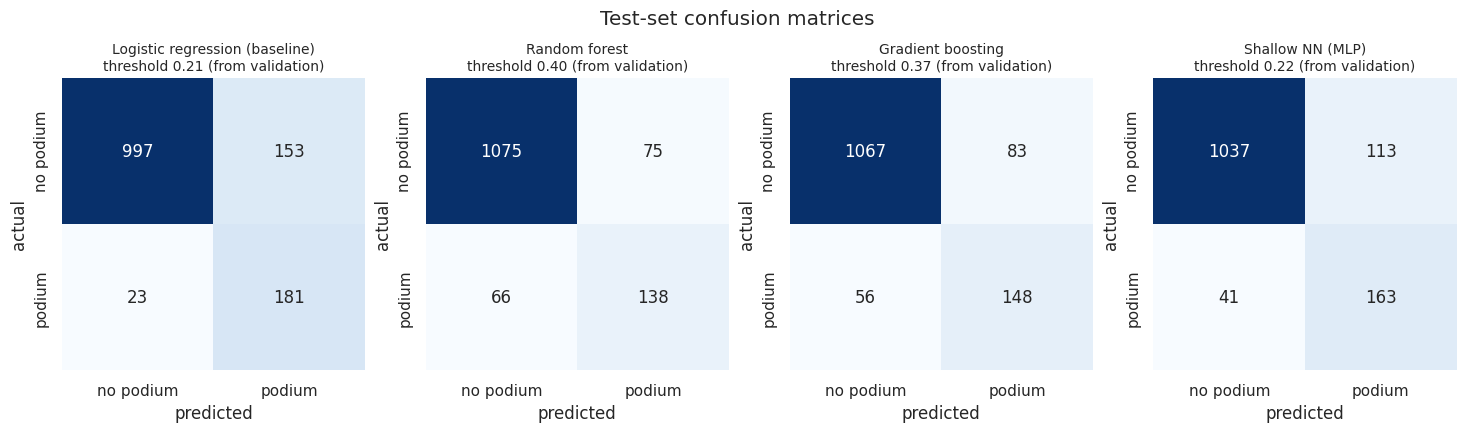

In [253]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, name in zip(axes, MODELS):
    pred = (PROBS[name]['test'] >= THRESHOLDS[name]).astype(int)
    cm = confusion_matrix(Y['test'], pred)
    sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap='Blues', ax=ax,
                xticklabels=['no podium', 'podium'], yticklabels=['no podium', 'podium'])
    ax.set_title(f'{name}\nthreshold {THRESHOLDS[name]:.2f} (from validation)', fontsize=10)
    ax.set_xlabel('predicted'); ax.set_ylabel('actual')
plt.suptitle('Test-set confusion matrices', y=1.06); plt.show()

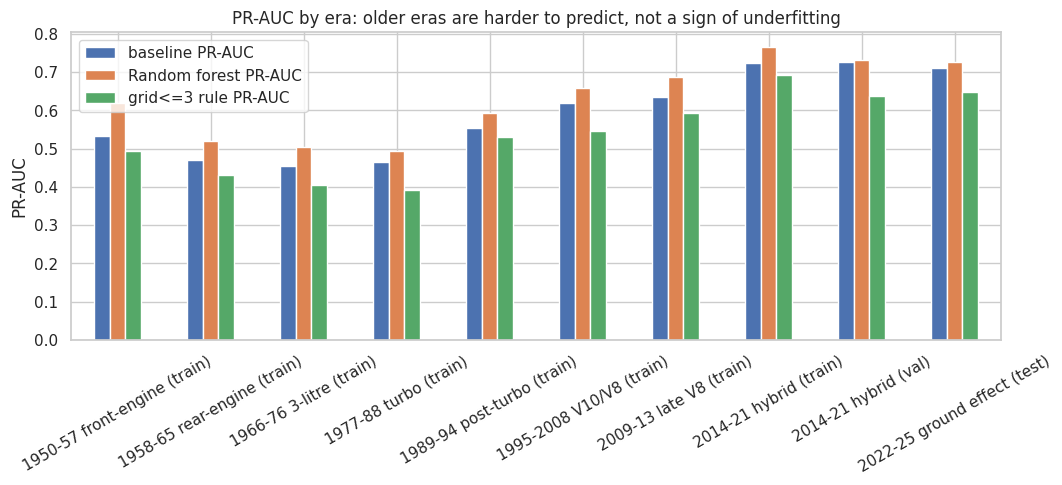

rows  podium rate  baseline PR-AUC  \
era                   part                                        
1950-57 front-engine  train  1109        0.151            0.533   
1958-65 rear-engine   train  1442        0.154            0.469   
1966-76 3-litre       train  3057        0.136            0.454   
1977-88 turbo         train  4654        0.121            0.464   
1989-94 post-turbo    train  2477        0.116            0.553   
1995-2008 V10/V8      train  5095        0.141            0.619   
2009-13 late V8       train  2143        0.132            0.636   
2014-21 hybrid        train  2478        0.146            0.723   
                      val     779        0.150            0.725   
2022-25 ground effect test   1354        0.151            0.711   

                             Random forest PR-AUC  grid<=3 rule PR-AUC  
era                   part                                              
1950-57 front-engine  train                 0.618                0.495  
1958-65 rear-engine   train                 0.519                0.431  
1966-76 3-litre       train                 0.504                0.405  
1977-88 turbo         train                 0.495                0.392  
1989-94 post-turbo    train                 0.594                0.531  
1995-2008 V10/V8      train                 0.659                0.547  
2009-13 late V8       train                 0.686                0.594  
2014-21 hybrid        train                 0.766                0.691  
                      val                   0.731                0.639  
2022-25 ground effect test                  0.725                0.647

In [254]:
# Why is TRAIN PR-AUC lower than validation? Score every era separately with the baseline and the best model
best_name = comparison.xs('val', level='part')['PR-AUC'].drop('Rule: grid <= 3 (reference)').idxmax()
era_rows = []
for s in PARTS:
    for era, idx in D[s].groupby('era').groups.items():
        idx = np.asarray(idx)
        y_e = Y[s][idx]
        if y_e.sum() == 0:
            continue
        era_rows.append({'era': era, 'part': s, 'rows': len(idx), 'podium rate': y_e.mean(),
                         'baseline PR-AUC': average_precision_score(y_e, PROBS['Logistic regression (baseline)'][s][idx]),
                         f'{best_name} PR-AUC': average_precision_score(y_e, PROBS[best_name][s][idx]),
                         'grid<=3 rule PR-AUC': average_precision_score(y_e, 1.0 / D[s]['grid'].to_numpy()[idx])})
era_df = pd.DataFrame(era_rows).set_index(['era', 'part'])
era_plot = era_df.drop(columns=['rows', 'podium rate'])
era_plot.index = [f'{e} ({p})' for e, p in era_plot.index]
ax = era_plot.plot(
    kind='bar', figsize=(12, 4), rot=30, title='PR-AUC by era: older eras are harder to predict, not a sign of underfitting')
ax.set_ylabel('PR-AUC'); plt.show()
era_df.round(3)

In [255]:
# Are the differences between models real? Bootstrap by RACE: resample whole races with replacement 1,000 times
# and recompute each model's PR-AUC minus the baseline's. If the 95% interval contains 0, the difference is noise.
rng = np.random.default_rng(SEED)
boot_rows = []
for s in ['val', 'test']:
    race_ids = D[s]['raceId'].to_numpy()
    races = np.unique(race_ids)
    idx_by_race = {r: np.flatnonzero(race_ids == r) for r in races}
    draws = [np.concatenate([idx_by_race[r] for r in rng.choice(races, len(races))]) for _ in range(1000)]
    base = PROBS['Logistic regression (baseline)'][s]
    for name in list(MODELS)[1:] + ['Rule: grid <= 3 (reference)']:
        p = 1.0 / D[s]['grid'].to_numpy() if name.startswith('Rule') else PROBS[name][s]
        diffs = np.array([average_precision_score(Y[s][d], p[d]) - average_precision_score(Y[s][d], base[d]) for d in draws])
        boot_rows.append({'part': s, 'model': name, 'PR-AUC minus baseline': average_precision_score(Y[s], p) - average_precision_score(Y[s], base),
                          '95% CI low': np.percentile(diffs, 2.5), '95% CI high': np.percentile(diffs, 97.5)})
boot = pd.DataFrame(boot_rows).set_index(['part', 'model'])
boot['verdict'] = np.where(boot['95% CI low'] > 0, 'better than baseline',
                   np.where(boot['95% CI high'] < 0, 'worse than baseline', 'no clear difference'))
boot.round(3)

PR-AUC minus baseline  95% CI low  \
part model                                                            
val  Random forest                                0.006      -0.017   
     Gradient boosting                            0.003      -0.029   
     Shallow NN (MLP)                             0.000      -0.021   
     Rule: grid <= 3 (reference)                 -0.087      -0.143   
test Random forest                                0.014      -0.012   
     Gradient boosting                            0.012      -0.024   
     Shallow NN (MLP)                            -0.004      -0.025   
     Rule: grid <= 3 (reference)                 -0.063      -0.112   

                                  95% CI high              verdict  
part model                                                          
val  Random forest                      0.024  no clear difference  
     Gradient boosting                  0.031  no clear difference  
     Shallow NN (MLP)                   0.023  no clear difference  
     Rule: grid <= 3 (reference)       -0.028  worse than baseline  
test Random forest                      0.040  no clear difference  
     Gradient boosting                  0.047  no clear difference  
     Shallow NN (MLP)                   0.014  no clear difference  
     Rule: grid <= 3 (reference)       -0.018  worse than baseline

> **Reading the comparison** (exact values in the tables above):
> - **Every model clearly beats the grid rule** on the primary metric: PR-AUC ≈ 0.72–0.73 vs 0.64 on validation, and ≈ 0.71 vs 0.65 on test. The bootstrap confirms this: the rule's interval lies entirely below the baseline.
> - **No model clearly beats the logistic-regression baseline.** The differences are at most about 0.01–0.02 PR-AUC, and every bootstrap interval contains 0. On this feature set, the extra complexity of forests, boosting and a neural network does not earn a measurable gain. Most of the signal is close to linear: better grid, better car, better form, more podiums.
> - **Tuning transferred to the new era.** Test is within about 0.02 PR-AUC of validation for every model, even though validation (hybrid era) and test (ground-effect era) come from different regulations (section 11).
> - **Train scores are lower than validation, and this is not underfitting.** The era plot shows every model and the grid rule scoring lower in old eras. When about half the field retires (sections 6 and Q3), podiums are harder to predict from pre-race information.
> - **Thresholds differ per model.** Logistic regression's F1 threshold is low (≈ 0.2): high recall, more false alarms. The random forest's is about twice as high: precision and recall balanced. Similar F1, different behaviour, visible in the confusion matrices.
> - **Model kept for explainability and inference:** the rule fixed in advance is "best validation PR-AUC", which selects `best_name` below. We state openly that it is statistically tied with the baseline, and logistic regression stays as the transparent reference.

In [256]:
best_name = comparison.xs('val', level='part')['PR-AUC'].drop('Rule: grid <= 3 (reference)').idxmax()
BEST_MODEL = MODELS[best_name]
BEST_THRESHOLD = THRESHOLDS[best_name]
print(f'Selected model (best validation PR-AUC): {best_name}, threshold {BEST_THRESHOLD:.3f} (from validation)')

Selected model (best validation PR-AUC): Random forest, threshold 0.402 (from validation)


## 14. Experiments

Three groups of controlled experiments. In each one, **a single thing changes** and everything else stays fixed:

| Experiment | What changes | Question |
|---|---|---|
| 14.1 Feature-group ablation | one feature group removed | how much does each group add? |
| 14.2 Split (a) vs (b) | the seasons used for validation and test | is our split choice justified? |
| 14.3 Data versions | one cleaning decision (D3, D2, D5) switched off | do our removal decisions change the results? |

Every experiment uses the **baseline** and the **selected model** from 13.8, with the hyperparameters tuned in 13.7 (not re-tuned), the F1 threshold chosen on validation, and the same metrics.

In [257]:
# Shared tools for every experiment in this section
EXP_MODELS = {
    'Logistic regression (baseline)': MODELS['Logistic regression (baseline)'].named_steps['model'],
    best_name: MODELS[best_name].named_steps['model'],
}

def pipe_for(cols, model):
    # the section-13 pipeline, adapted when an experiment removes the gap feature or qualifying position
    steps = []
    if GAP_COL in cols:
        steps.append(('impute_gap', GapImputer(GAP_STRATEGY if 'quali_position' in cols else 'median', GAP_COL)))
    steps += [('scale', StandardScaler().set_output(transform='pandas')), ('model', clone(model))]
    return Pipeline(steps)

def score_rows(df, p, thr):
    # the metrics of 13.1 for any set of rows (df must hold raceId and the target)
    pred = (p >= thr).astype(int)
    return {'PR-AUC': average_precision_score(df[TARGET], p), 'ROC-AUC': roc_auc_score(df[TARGET], p),
            'F1': f1_score(df[TARGET], pred)}

def fit_and_score(train, val, test, cols, model):
    # fit on train, choose the F1 threshold on val, score val and test
    pipe = pipe_for(cols, model).fit(train[cols].astype(float), train[TARGET])
    p_val = pipe.predict_proba(val[cols].astype(float))[:, 1]
    p_test = pipe.predict_proba(test[cols].astype(float))[:, 1]
    thr = pick_threshold(val[TARGET].to_numpy(), p_val)
    return score_rows(val, p_val, thr), score_rows(test, p_test, thr), pipe

print('Models used in every experiment:', list(EXP_MODELS), '(settings tuned in 13.7, not re-tuned)')

Models used in every experiment: ['Logistic regression (baseline)', 'Random forest'] (settings tuned in 13.7, not re-tuned)


### 14.1 Feature-group ablation

Each group from section 10.3 is removed in turn and the model is retrained. Because grid and qualifying position carry almost the same information (ρ ≈ 0.99, section 12), removing both together is tested as well.

In [258]:
ablation_sets = {'all features (reference)': MODEL_FEATURES}
for group, cols in FEATURE_GROUPS.items():
    group_cols = [GAP_COL if c == 'q1_gap_pct' else c for c in cols]
    ablation_sets[f'without {group}'] = [c for c in MODEL_FEATURES if c not in group_cols]
# grid and qualifying position carry the same information (rho 0.99), so also remove both groups together
ablation_sets['without grid + qualifying'] = [c for c in MODEL_FEATURES
                                              if c not in FEATURE_GROUPS['grid'] + FEATURE_GROUPS['qualifying'] + [GAP_COL]]

abl_rows = []
for label, cols in ablation_sets.items():
    for mname, model in EXP_MODELS.items():
        v, t, _ = fit_and_score(D['train'], D['val'], D['test'], cols, model)
        abl_rows.append({'feature set': label, 'model': mname, 'n features': len(cols),
                         'val PR-AUC': v['PR-AUC'], 'test PR-AUC': t['PR-AUC'], 'val F1': v['F1'], 'test F1': t['F1']})
ablation = pd.DataFrame(abl_rows).set_index(['feature set', 'model'])
ref = ablation.xs('all features (reference)', level='feature set')
for col in ['val PR-AUC', 'test PR-AUC']:
    ablation[f'drop in {col}'] = ref[col].reindex(ablation.index.get_level_values('model')).to_numpy() - ablation[col]
ablation.round(4)

n features  \
feature set               model                                        
all features (reference)  Logistic regression (baseline)          21   
                          Random forest                           21   
without grid              Logistic regression (baseline)          18   
                          Random forest                           18   
without qualifying        Logistic regression (baseline)          17   
                          Random forest                           17   
without driver_form       Logistic regression (baseline)          13   
                          Random forest                           13   
without team_form         Logistic regression (baseline)          17   
                          Random forest                           17   
without context           Logistic regression (baseline)          19   
                          Random forest                           19   
without grid + qualifying Logistic regression (baseline)          14   
                          Random forest                           14   

                                                          val PR-AUC  \
feature set               model                                        
all features (reference)  Logistic regression (baseline)      0.7251   
                          Random forest                       0.7309   
without grid              Logistic regression (baseline)      0.7268   
                          Random forest                       0.7074   
without qualifying        Logistic regression (baseline)      0.7192   
                          Random forest                       0.7089   
without driver_form       Logistic regression (baseline)      0.6707   
                          Random forest                       0.6971   
without team_form         Logistic regression (baseline)      0.7387   
                          Random forest                       0.7302   
without context           Logistic regression (baseline)      0.7234   
                          Random forest                       0.7225   
without grid + qualifying Logistic regression (baseline)      0.6185   
                          Random forest                       0.6411   

                                                          test PR-AUC  val F1  \
feature set               model                                                 
all features (reference)  Logistic regression (baseline)       0.7107  0.7080   
                          Random forest                        0.7250  0.7069   
without grid              Logistic regression (baseline)       0.7080  0.7037   
                          Random forest                        0.7077  0.7143   
without qualifying        Logistic regression (baseline)       0.7047  0.7068   
                          Random forest                        0.7121  0.6960   
without driver_form       Logistic regression (baseline)       0.7098  0.7019   
                          Random forest                        0.7169  0.7171   
without team_form         Logistic regression (baseline)       0.7109  0.7082   
                          Random forest                        0.7278  0.7130   
without context           Logistic regression (baseline)       0.7104  0.7004   
                          Random forest                        0.7289  0.7083   
without grid + qualifying Logistic regression (baseline)       0.5560  0.6860   
                          Random forest                        0.5802  0.6833   

                                                          test F1  \
feature set               model                                     
all features (reference)  Logistic regression (baseline)   0.6729   
                          Random forest                    0.6619   
without grid              Logistic regression (baseline)   0.6805   
                          Random forest                    0.6378   
without qualifying        Logistic regres

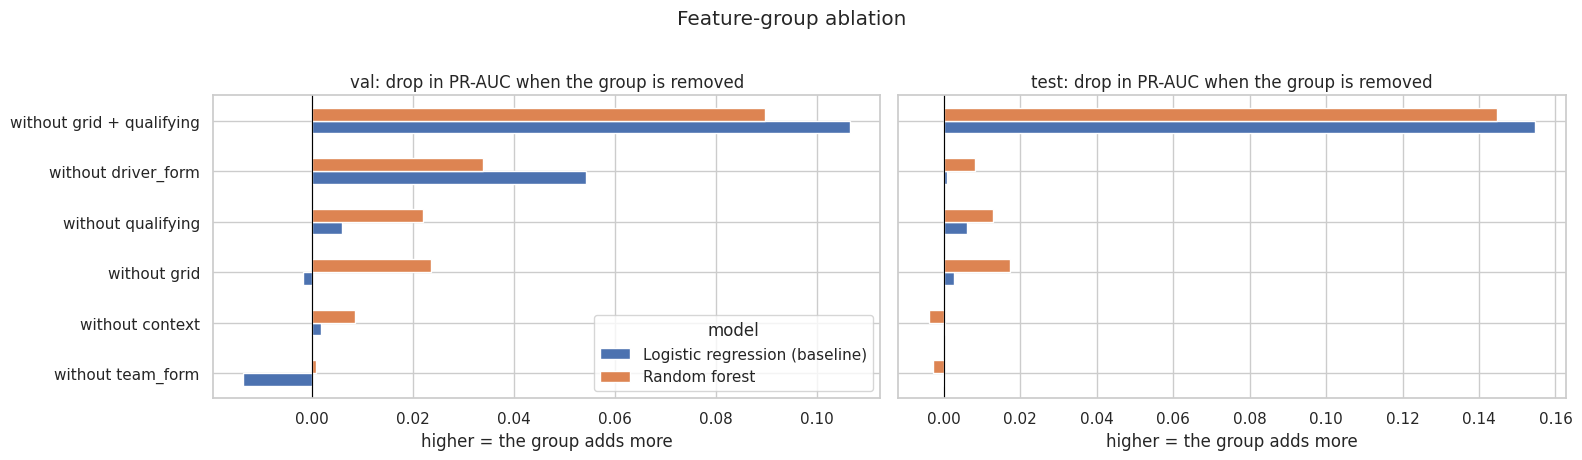

In [259]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for ax, part in zip(axes, ['val', 'test']):
    d = (ablation.drop(index='all features (reference)', level='feature set')[f'drop in {part} PR-AUC']
         .unstack('model'))
    d = d.loc[ablation.drop(index='all features (reference)', level='feature set')['drop in val PR-AUC']
              .groupby(level='feature set').mean().sort_values().index]
    d.plot(kind='barh', ax=ax, legend=(part == 'val'))
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(f'{part}: drop in PR-AUC when the group is removed')
    ax.set_xlabel('higher = the group adds more'); ax.set_ylabel('')
plt.suptitle('Feature-group ablation', y=1.02); plt.tight_layout(); plt.show()

> **Reading the ablation:**
> - **Starting position is the backbone.** Removing grid or qualifying alone changes little, because the other group still holds the starting order. Removing both at once causes by far the largest drop (about 0.09–0.11 PR-AUC on validation and 0.14–0.15 on test). This is why single-group ablation can be misleading with correlated groups.
> - **Driver form is the second most useful group**, clearly on validation (about 0.03–0.05), less on test.
> - **Team form adds little once driver form is present.** Logistic regression is even slightly better on validation without it. A driver's recent podiums already reflect his car. Under our decision rule (change a planned decision only on clear evidence), the group stays: the gain appears for one model on validation only, not on test or for the selected model. It is noted as a candidate for removal, and the XAI in section 15 shows how much the models actually use it.
> - **Context** (`era_index`, season opener) adds little on its own.
> - An ablation measures what a group adds **on top of the others**. It does not measure a feature's importance alone, and it says nothing about cause and effect.

### 14.2 Split (a) vs split (b)

Section 11 compared the two splits on the data. Here the models are trained under both splits. Two questions:

1. **Does validation predict test?** A small |val − test| gap means settings chosen on validation can be trusted.
2. **Is accuracy lost?** Split (a) trains on two fewer seasons. Both splits are scored on the **same rows** (2023–24, test data under both), so the comparison is fair.

In [260]:
# Split (a) vs split (b): same models, same settings. Each split chooses its own F1 threshold on its own validation set.
split_rows = []
common_test = features['year'].between(2023, 2024)            # seasons that are test data under BOTH splits
for scheme in SPLITS:
    sp = assign_split(features['year'], scheme)
    tr, va, te = (features[sp == s].reset_index(drop=True) for s in PARTS)
    te_common = features[(sp == 'test') & common_test].reset_index(drop=True)
    for mname, model in EXP_MODELS.items():
        v, t, pipe = fit_and_score(tr, va, te, MODEL_FEATURES, model)
        thr = pick_threshold(va[TARGET].to_numpy(), pipe.predict_proba(va[MODEL_FEATURES].astype(float))[:, 1])
        tc = score_rows(te_common, pipe.predict_proba(te_common[MODEL_FEATURES].astype(float))[:, 1], thr)
        split_rows.append({'split': scheme, 'model': mname,
                           'val seasons': f"{va['year'].min()}-{va['year'].max()}", 'val rows': len(va),
                           'test seasons': f"{te['year'].min()}-{te['year'].max()}", 'test rows': len(te),
                           'val PR-AUC': v['PR-AUC'], 'test PR-AUC': t['PR-AUC'],
                           '|val - test| PR-AUC': abs(v['PR-AUC'] - t['PR-AUC']),
                           'val F1': v['F1'], 'test F1': t['F1'], '|val - test| F1': abs(v['F1'] - t['F1']),
                           'PR-AUC on 2023-24 (same rows for both)': tc['PR-AUC'], 'F1 on 2023-24': tc['F1']})
split_cmp = pd.DataFrame(split_rows).set_index(['split', 'model'])
split_cmp.round(4).T

split                                                      a (chosen)  \
model                                  Logistic regression (baseline)   
val seasons                                                 2020-2021   
val rows                                                          779   
test seasons                                                2022-2024   
test rows                                                        1354   
val PR-AUC                                                     0.7251   
test PR-AUC                                                    0.7107   
|val - test| PR-AUC                                            0.0144   
val F1                                                          0.708   
test F1                                                        0.6729   
|val - test| F1                                                0.0352   
PR-AUC on 2023-24 (same rows for both)                         0.7215   
F1 on 2023-24                                                  0.6482   

split                                                 \
model                                  Random forest   
val seasons                                2020-2021   
val rows                                         779   
test seasons                               2022-2024   
test rows                                       1354   
val PR-AUC                                    0.7309   
test PR-AUC                                    0.725   
|val - test| PR-AUC                            0.006   
val F1                                        0.7069   
test F1                                       0.6619   
|val - test| F1                                0.045   
PR-AUC on 2023-24 (same rows for both)        0.7461   
F1 on 2023-24                                 0.6595   

split                                                     b (compare)  \
model                                  Logistic regression (baseline)   
val seasons                                                 2022-2022   
val rows                                                          439   
test seasons                                                2023-2024   
test rows                                                         915   
val PR-AUC                                                     0.6664   
test PR-AUC                                                    0.7207   
|val - test| PR-AUC                                            0.0544   
val F1                                                         0.7368   
test F1                                                        0.6574   
|val - test| F1                                                0.0795   
PR-AUC on 2023-24 (same rows for both)                         0.7207   
F1 on 2023-24                                                  0.6574   

split                                                 
model                                  Random forest  
val seasons                                2022-2022  
val rows                                         439  
test seasons                               2023-2024  
test rows                                        915  
val PR-AUC                                    0.6844  
test PR-AUC                                   0.7422  
|val - test| PR-AUC                           0.0578  
val F1                                           0.7  
test F1                                        0.673  
|val - test| F1                                0.027  
PR-AUC on 2023-24 (same rows for both)        0.7422  
F1 on 2023-24                                  0.673

> **Reading:**
> - **Under (b), validation is a poor guide to test.** Its single season (2022, about 440 rows, 22 races) misses the test PR-AUC by about 0.05–0.06, against about 0.01 under (a). One season is too small to tune on: a few unusual races move the score a lot.
> - **No accuracy is lost.** On the identical 2023–24 rows, both splits score about the same. Training on 2020–21 as well does not help (b) measurably.
> - **Conclusion: split (a) is kept.** It gives a validation set that tracks test, at no cost in accuracy. This is the evidence the instructors asked for in place of copying the suggested split.

### 14.3 Data versions: do the removal decisions change the results?

The Piazza ruling asks for removal decisions to be backed by experiments. Each version below switches **one** cleaning decision off; the feature table is rebuilt with the same `build_features` code (section 10).

| Version | What changes in the training data |
|---|---|
| D3 off | non-starters (did not qualify, withdrew) stay in, with no grid slot (put behind the field) |
| D2 off | every entry of a shared car stays in (a driver can appear twice in one race, a car can have two drivers) |
| D5 off | the Indianapolis 500 races (1950–60) stay in |

**Fair comparison:** all versions are scored on **identical** validation and test rows, the starters of the decided table. Non-starters are left out of scoring: they can never podium, so adding them would inflate every score without the model doing anything better. None of the three decisions touches 2020–24 rows (shared cars end in the 1960s, Indy in 1960, non-starters almost vanish after 2003), so only **training** changes.

First, a check that the cleaning steps, wrapped into one function, give back the cleaned table exactly:

In [261]:
# To test the cleaning decisions, the cleaning steps D3, D2 and D4 are wrapped in one function, so the feature
# table can be rebuilt from a different version of the data with exactly the same code.
def prepare_results(r, apply_d3=True, apply_d2=True):
    r = r.reset_index(drop=True)
    # D3: drop non-starters (same rule as 5.8)
    non_starter = ((r['status_base'] == 'did_not_start') | ((r['laps'] == 0) & (r['grid'] == 0))
                   | ((r['status'] == 'Withdrew') & (r['laps'] == 0)))
    r['is_non_starter'] = non_starter.astype(int)
    if apply_d3:
        r = r[~non_starter]
    # D2: one driver per car, the car's last entry (same greedy rule as 5.9)
    if apply_d2:
        r['is_last_entry'] = r.groupby(CAR)['resultId'].transform('max') == r['resultId']
        kept, used_cars, used_drivers = [], set(), set()
        for row in r.sort_values(['raceId', 'is_last_entry', 'resultId'], ascending=[True, False, False]).itertuples():
            car, drv = (row.raceId, row.number, row.grid), (row.raceId, row.driverId)
            if car in used_cars or drv in used_drivers:
                continue
            used_cars.add(car); used_drivers.add(drv); kept.append(row.Index)
        r = r.loc[kept].drop(columns='is_last_entry')
    # D4: missing grid from qualifying; grid 0 -> behind the last grid slot + flag (same as 5.10)
    if r['grid'].isna().any():
        qpos = r[['raceId', 'driverId']].merge(clean['qualifying'][['raceId', 'driverId', 'position']],
                                               on=['raceId', 'driverId'], how='left')['position'].to_numpy()
        r.loc[r['grid'].isna().to_numpy(), 'grid'] = pd.array(qpos, dtype='Int64')[r['grid'].isna().to_numpy()]
        r = r[r['grid'].notna()]
    back = r['grid'].where(r['grid'] > 0).groupby(r['raceId']).transform('max').fillna(0) + 1
    r['pit_lane_start'] = (r['grid'] == 0).astype(int)        # non-starters kept by a variant also land here
    r['grid'] = np.where(r['grid'] == 0, back, r['grid']).astype(int)
    return r.sort_values('resultId').reset_index(drop=True)

# Check: applied to all entries with every decision on, the function must give back the cleaned table exactly
check = prepare_results(clean['results_all'])
key = ['raceId', 'driverId', 'grid']
same = check[key].astype(float).sort_values(key).reset_index(drop=True).equals(
       clean['results'][key].astype(float).sort_values(key).reset_index(drop=True))
print('prepare_results reproduces the cleaned table:', same, f'({len(check)} vs {len(clean["results"])} rows)')
assert same

prepare_results reproduces the cleaned table: True (24588 vs 24588 rows)


In [262]:
# Build the feature table for each version of the data (each takes a little while: same code as section 10)
ERA_TO_INDEX = {e: i for i, e in enumerate(ERA_ORDER)}
indy_all = clean['indy_results'].merge(clean['status'][['statusId', 'status', 'status_base']], on='statusId', how='left')

def features_for(results, extra_races=None):
    races_backup = clean['races']
    try:
        if extra_races is not None:              # the Indy 500 races were removed from clean['races'] in 5.6
            clean['races'] = pd.concat([clean['races'], extra_races.assign(is_sprint_weekend=False)]).sort_values('race_order')
        f = build_features(results)
    finally:
        clean['races'] = races_backup
    f['era_index'] = f['era'].map(ERA_TO_INDEX).astype(int)
    return f

t0 = time.time()
VARIANTS = {
    'as decided (D2 + D3 + D5)':        features,
    'D3 off: non-starters kept':        features_for(prepare_results(clean['results_all'], apply_d3=False)),
    'D2 off: every entry of shared cars': features_for(prepare_results(clean['results_all'], apply_d2=False)),
    'D5 off: Indy 500 included':        features_for(prepare_results(pd.concat([clean['results_all'], indy_all], ignore_index=True)),
                                                     extra_races=clean['indy_races']),
}
print(f'variant feature tables built in {time.time() - t0:.0f} s')
pd.DataFrame({name: {'rows': len(f), 'train rows (1950-2019)': int(f['year'].between(1950, 2019).sum()),
                     'train podium rate': f.loc[f['year'].between(1950, 2019), TARGET].mean(),
                     'duplicate (raceId, driverId)': int(f.duplicated(['raceId', 'driverId']).sum()),
                     'races with != 3 podium rows': int((f.groupby('raceId')[TARGET].sum() != 3).sum())}
              for name, f in VARIANTS.items()}).T.round(3)

variant feature tables built in 4 s


,rows,train rows (1950-2019),train podium rate,"duplicate (raceId, driverId)",races with != 3 podium rows
as decided (D2 + D3 + D5),24588.0,22455.0,0.135,0.0,0.0
D3 off: non-starters kept,26217.0,24078.0,0.125,0.0,0.0
D2 off: every entry of shared cars,24708.0,22575.0,0.135,64.0,15.0
D5 off: Indy 500 included,24942.0,22809.0,0.134,0.0,0.0


In [263]:
# Piazza ruling: compare every variant on IDENTICAL evaluation rows. The val/test rows are the starters of the
# decided table (non-starters are certain non-podiums and would inflate every score). Only training changes.
var_rows = []
for vname, vf in VARIANTS.items():
    train = vf[vf['year'].between(1950, 2019)].reset_index(drop=True)
    ev = {s: D[s][['raceId', 'driverId']].merge(vf, on=['raceId', 'driverId'], how='left') for s in ['val', 'test']}
    assert all(len(ev[s]) == len(D[s]) and ev[s][TARGET].notna().all() for s in ev), 'evaluation rows differ'
    for mname, model in EXP_MODELS.items():
        v, t, _ = fit_and_score(train, ev['val'], ev['test'], MODEL_FEATURES, model)
        var_rows.append({'data version': vname, 'model': mname, 'train rows': len(train),
                         'val PR-AUC': v['PR-AUC'], 'test PR-AUC': t['PR-AUC'], 'val F1': v['F1'], 'test F1': t['F1']})
variants = pd.DataFrame(var_rows).set_index(['data version', 'model'])
ref_v = variants.xs('as decided (D2 + D3 + D5)', level='data version')
variants['val PR-AUC vs decided'] = variants['val PR-AUC'] - ref_v['val PR-AUC'].reindex(
    variants.index.get_level_values('model')).to_numpy()
variants.round(4)

train rows  \
data version                       model                                        
as decided (D2 + D3 + D5)          Logistic regression (baseline)       22455   
                                   Random forest                        22455   
D3 off: non-starters kept          Logistic regression (baseline)       24078   
                                   Random forest                        24078   
D2 off: every entry of shared cars Logistic regression (baseline)       22575   
                                   Random forest                        22575   
D5 off: Indy 500 included          Logistic regression (baseline)       22809   
                                   Random forest                        22809   

                                                                   val PR-AUC  \
data version                       model                                        
as decided (D2 + D3 + D5)          Logistic regression (baseline)      0.7251   
                                   Random forest                       0.7309   
D3 off: non-starters kept          Logistic regression (baseline)      0.7262   
                                   Random forest                       0.7146   
D2 off: every entry of shared cars Logistic regression (baseline)      0.7248   
                                   Random forest                       0.7217   
D5 off: Indy 500 included          Logistic regression (baseline)      0.7255   
                                   Random forest                       0.7247   

                                                                   test PR-AUC  \
data version                       model                                         
as decided (D2 + D3 + D5)          Logistic regression (baseline)       0.7107   
                                   Random forest                        0.7250   
D3 off: non-starters kept          Logistic regression (baseline)       0.7106   
                                   Random forest                        0.7260   
D2 off: every entry of shared cars Logistic regression (baseline)       0.7101   
                                   Random forest                        0.7228   
D5 off: Indy 500 included          Logistic regression (baseline)       0.7107   
                                   Random forest                        0.7208   

                                                                   val F1  \
data version                       model                                    
as decided (D2 + D3 + D5)          Logistic regression (baseline)  0.7080   
                                   Random forest                   0.7069   
D3 off: non-starters kept          Logistic regression (baseline)  0.7127   
                                   Random forest                   0.7083   
D2 off: every entry of shared cars Logistic regression (baseline)  0.7055   
                                   Random forest                   0.7069   
D5 off: Indy 500 included          Logistic regression (baseline)  0.7080   
                                   Random forest                   0.7094   

                                                                   test F1  \
data version                       model                                     
as decided (D2 + D3 + D5)          Logistic regression (baseline)   0.6729   
                                   Random forest                    0.6619   
D3 off: non-starters kept          Logistic regression (baseline)   0.6778   
                                   Random forest                    0.6744   
D2 off: every entry of shared cars Logistic regression (baseline)   0.6716   
                                   Random forest                    0.6683   
D5 off: Indy 500 included          Logistic regression (baseline)   0.6729   
                                   Random forest                    0.6667   

                                                                   val P

> **Reading:**
> - **The data table shows what each decision fixes.** Without D2, some drivers appear twice in the same race and some races have more than 3 podium rows: the grain (one row per driver per race) and the target are broken. Without D3, about 1,600 rows that can never podium are added, which lowers the podium rate. Without D5, about 350 Indy 500 rows are added.
> - **The scores barely move.** Logistic regression changes by about 0.001–0.002 PR-AUC; the selected model by up to about 0.01–0.02, which is within the noise measured in 13.8, and no version beats the decided one.
> - **Conclusion: the decisions are kept.** They do not cost accuracy, and they are needed for reasons the scores cannot show: D2 keeps the grain and the target correct, D3 matches the prediction cutoff (a non-starter has no grid slot, so there is nothing to predict), and D5 removes a race that was not really part of the F1 field.

### 14.4 Summary of experiments and decisions

| Experiment | Section | Result | Decision |
|---|---|---|---|
| Imputation of the qualifying gap | 13.3 | position-based fill best, and keeps the feature's shape | `from_position` |
| Q1 gap vs best-of-3 (D14) | 13.4 | practically tied; interval contains 0 | keep `q1_gap_pct` |
| Preprocessing order 1: fit before or after the split | 13.5 | leaky order changes fill values (uses test), scores barely change | fit after the split |
| Preprocessing order 2: impute → scale vs scale → impute | 13.5 | order changes the meaning of filled values, scores barely change | impute (median by position), then scale |
| Model comparison | 13.8 | all models beat the grid rule; none clearly beats the baseline | report all; selected model by validation PR-AUC |
| Feature-group ablation | 14.1 | grid + qualifying together essential; driver form next; team form adds little | keep all groups; team form flagged |
| Split (a) vs (b) | 14.2 | (a) validation tracks test much better, same accuracy on 2023–24 | keep split (a) |
| D3 / D2 / D5 switched off | 14.3 | scores unchanged within noise; D2 off breaks the grain and target | keep D2, D3, D5 |

## 15. Model explainability (XAI)

**Important: importance is not cause.** Every method in this section shows what the **model relies on** to make its predictions. None of them shows what **causes** a podium. Starting on pole does not by itself cause a podium: a fast car and driver cause both the pole and the podium, and the model uses the grid slot as evidence of that speed. A feature can also be important only because it repeats another one (grid and qualifying position).

| Method | Scope | Question it answers |
|---|---|---|
| Permutation importance | global | how much worse does the model get if this feature is scrambled? |
| SHAP summary and bar plots | global | how much, and in which direction, does each feature move the predictions? |
| SHAP waterfall | local | why did the model give **this** driver in **this** race this probability? |
| LIME | local | a second, independent local explanation, to check the SHAP one |

The selected model from 13.8 is explained, on the **test** seasons (2022–24): data it never saw. The baseline is shown next to it in the permutation importance.

In [264]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter('ignore')          # silences a harmless progress-bar warning printed on import
    import shap
from sklearn.inspection import permutation_importance
try:
    from lime.lime_tabular import LimeTabularExplainer
except ImportError:                      # Kaggle normally has lime; install it only if it is missing
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'lime'], check=False)
    try:
        from lime.lime_tabular import LimeTabularExplainer
    except ImportError:
        LimeTabularExplainer = None
print('shap', shap.__version__, '| lime available:', LimeTabularExplainer is not None)

# Readable labels for every test row (who, which race, from where)
names = (D['test'][['raceId', 'driverId', 'constructorId', 'grid', 'year', TARGET]]
         .merge(clean['drivers'][['driverId', 'forename', 'surname']], on='driverId', how='left')
         .merge(clean['races'][['raceId', 'name']].rename(columns={'name': 'race'}), on='raceId', how='left')
         .merge(clean['constructors'][['constructorId', 'name']].rename(columns={'name': 'team'}), on='constructorId', how='left'))
names['label'] = (names['forename'] + ' ' + names['surname'] + ' (' + names['team'] + '), ' + names['year'].astype(str)
                  + ' ' + names['race'] + ', grid P' + names['grid'].astype(str))
print('Model explained in this section:', best_name)

shap 0.52.0 | lime available: True
Model explained in this section: Random forest


### 15.1 Permutation importance (global)

Each feature is shuffled in turn in the test rows, which breaks its link with the target while keeping its distribution. The drop in PR-AUC is how much the model relies on it. The error bars show the spread over 10 shuffles.

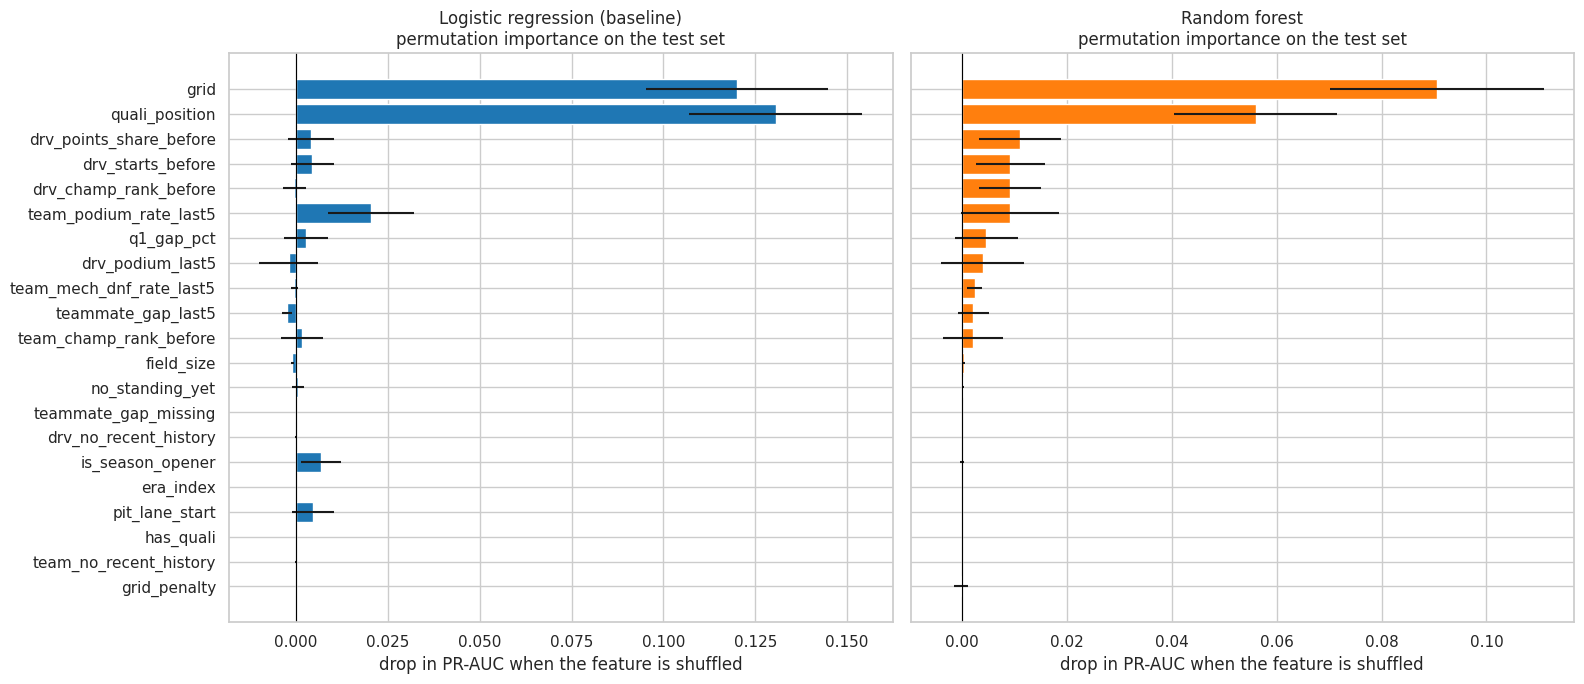

,Logistic regression (baseline),Random forest
grid,0.1201,0.0905
quali_position,0.1306,0.0560
drv_points_share_before,0.0042,0.0111
drv_starts_before,0.0044,0.0093
drv_champ_rank_before,-0.0005,0.0092
team_podium_rate_last5,0.0203,0.0091
q1_gap_pct,0.0027,0.0046
drv_podium_last5,-0.0019,0.0039
team_mech_dnf_rate_last5,-0.0005,0.0024
teammate_gap_last5,-0.0025,0.0022


In [265]:
# Permutation importance: shuffle ONE feature in the test rows, keep everything else, and measure how much
# the PR-AUC falls. A big fall = the model relies on that feature. 10 shuffles per feature.
perm = {}
for name in ['Logistic regression (baseline)', best_name]:
    r = permutation_importance(MODELS[name], XM['test'], Y['test'], scoring='average_precision',
                               n_repeats=10, random_state=SEED, n_jobs=1)
    perm[name] = pd.DataFrame({'mean drop in PR-AUC': r.importances_mean, 'std': r.importances_std},
                              index=MODEL_FEATURES)
order = perm[best_name]['mean drop in PR-AUC'].sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
for ax, (name, pi) in zip(axes, perm.items()):
    pi = pi.loc[order]
    ax.barh(pi.index, pi['mean drop in PR-AUC'], xerr=pi['std'], color='tab:blue' if 'Logistic' in name else 'tab:orange')
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(f'{name}\npermutation importance on the test set'); ax.set_xlabel('drop in PR-AUC when the feature is shuffled')
plt.tight_layout(); plt.show()
pd.concat({n: p['mean drop in PR-AUC'] for n, p in perm.items()}, axis=1).loc[order[::-1]].round(4)

> **Reading:**
> - **Both models rely mostly on grid and qualifying position.** This matches the ablation (14.1), where removing both was by far the largest loss.
> - **The two models split the work differently.** Logistic regression puts its weight on starting position plus recent team podium rate. The forest spreads it more across driver standings, experience and team form.
> - **Some features show ≈ 0 for a reason that has nothing to do with usefulness.** In the test seasons `era_index` is always 8 and `has_quali` is always 1, so shuffling them changes nothing. Permutation importance can only measure features that vary in the rows it is computed on.
> - **Correlated features share importance.** Shuffling grid leaves qualifying position intact, so each looks less important than "starting position" really is.

### 15.2 SHAP (global)

SHAP splits each prediction into one contribution per feature: **prediction = average prediction + sum of contributions**. The cell checks that this sum reproduces the model's probability exactly. In the summary plot, each dot is one test row: its position is the feature's contribution, and its colour is the feature's value (red = high, blue = low).

largest gap between SHAP sum and model probability: 0.0


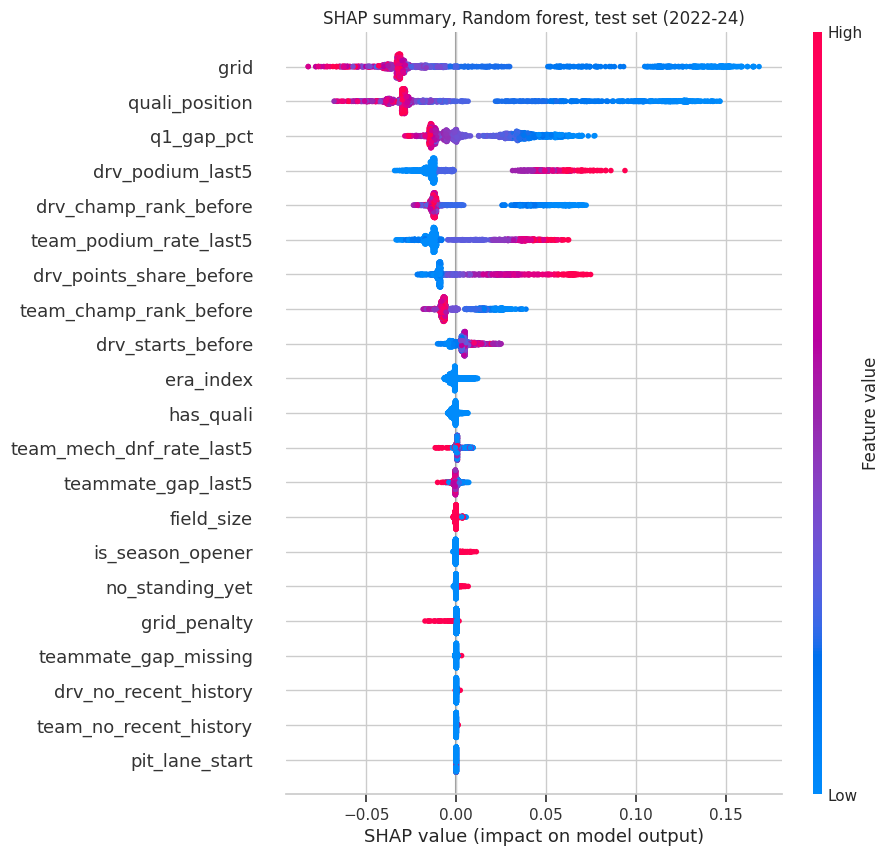

In [266]:
# SHAP: for every row, splits the prediction into one contribution per feature
# (prediction = average prediction + sum of contributions). Computed on the test rows.
prep_best = Pipeline(BEST_MODEL.steps[:-1])                        # fitted imputer + scaler
est_best = BEST_MODEL.named_steps['model']
T_test = prep_best.transform(XM['test'])
raw_test = BEST_MODEL.named_steps['impute_gap'].transform(XM['test'])   # same rows in original units (for display)

if isinstance(est_best, (RandomForestClassifier, HistGradientBoostingClassifier)):
    explainer = shap.TreeExplainer(est_best)
    sv = explainer.shap_values(T_test)
    base = explainer.expected_value
    if isinstance(sv, list):                         # older shap: one array per class
        sv, base = sv[1], base[1]
    elif np.ndim(sv) == 3:                           # newer shap: (rows, features, classes)
        sv, base = sv[:, :, 1], np.atleast_1d(base)[-1]
else:                                                # neural network: model-agnostic explainer on a sample
    background = shap.sample(prep_best.transform(XM['train']), 200, random_state=SEED)
    explainer = shap.Explainer(lambda a: est_best.predict_proba(pd.DataFrame(a, columns=T_test.columns))[:, 1], background)
    e_ = explainer(T_test)
    sv, base = e_.values, e_.base_values[0]
base = float(np.ravel(base)[0])
shap_exp = shap.Explanation(values=sv, base_values=np.full(len(sv), base), data=raw_test.to_numpy(),
                            feature_names=list(raw_test.columns))
# Check: average prediction + contributions = the model's probability (tree models are exact)
recon = base + sv.sum(axis=1)
print('largest gap between SHAP sum and model probability:',
      round(float(np.abs(recon - est_best.predict_proba(T_test)[:, 1]).max()), 6))

plt.figure()
shap.plots.beeswarm(shap_exp, max_display=21, show=False)
plt.title(f'SHAP summary, {best_name}, test set (2022-24)'); plt.show()

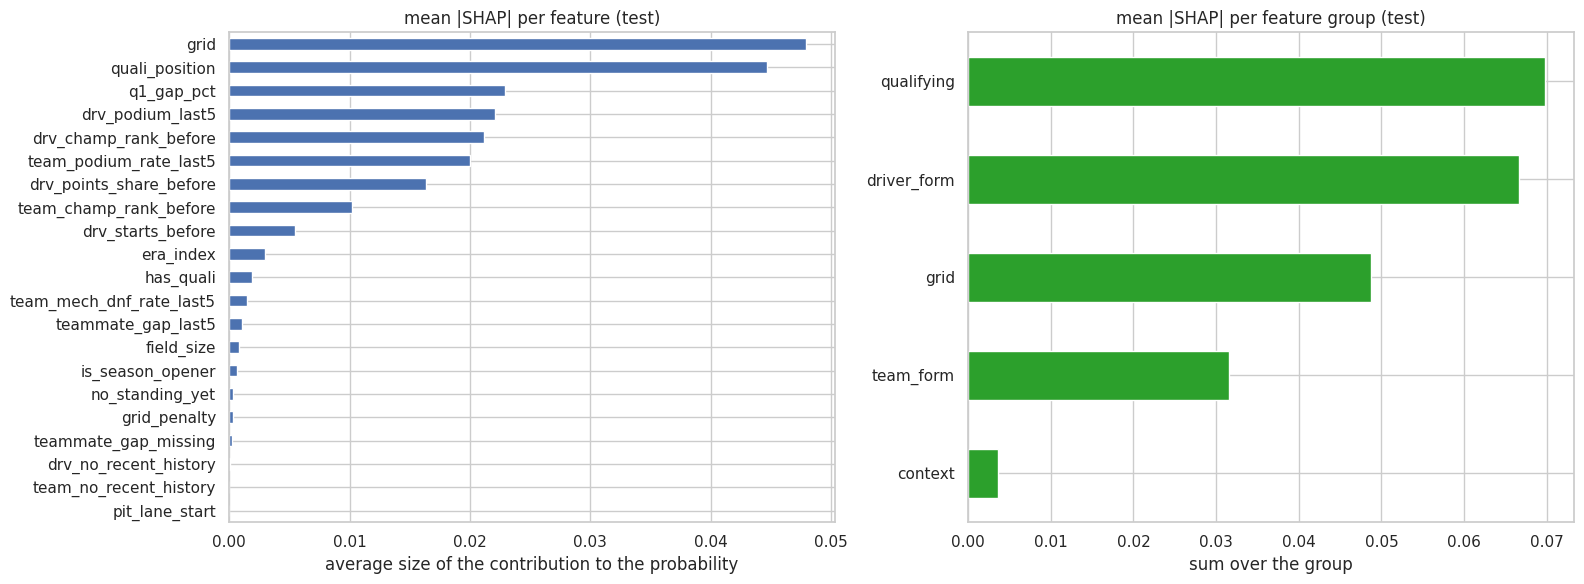

In [267]:
mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=raw_test.columns).sort_values(ascending=False)
group_of = {c: g for g, cols in FEATURE_GROUPS.items() for c in cols}
group_of[GAP_COL] = 'qualifying'
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
mean_abs[::-1].plot(kind='barh', ax=axes[0], title='mean |SHAP| per feature (test)')
axes[0].set_xlabel('average size of the contribution to the probability')
mean_abs.groupby(mean_abs.index.map(group_of)).sum().sort_values().plot(kind='barh', ax=axes[1], color='tab:green',
                                                                        title='mean |SHAP| per feature group (test)')
axes[1].set_xlabel('sum over the group')
plt.tight_layout(); plt.show()

> **Reading the summary:**
> - **Grid and qualifying position:** low values (blue, the front of the grid) push the probability up strongly; high values push it down a little. The effect is lopsided: starting at the front matters much more than how far back a midfield driver starts.
> - **The qualifying gap:** small gaps (fast in Q1) push up.
> - **Recent podiums, standings and points share:** a driver with recent podiums and a high points share is pushed up.
> - **Team form:** smaller than driver form, consistent with the ablation.
> - **By group:** qualifying, driver form and grid carry most of the explanation. Team form and context carry little.

### 15.3 Local explanations: three individual predictions

Three test rows chosen automatically: the most confident correct podium, the podium finisher the model rated lowest (the biggest miss), and the non-podium the model rated highest (the biggest false alarm).

In [268]:
# Three test rows to explain one by one: a confident correct podium, the biggest miss, the biggest false alarm
p_best = PROBS[best_name]['test']
ex = names.assign(p=p_best)
examples = {
    'confident and correct': ex[ex[TARGET] == 1]['p'].idxmax(),
    'biggest miss (podium the model did not expect)': ex[ex[TARGET] == 1]['p'].idxmin(),
    'biggest false alarm': ex[ex[TARGET] == 0]['p'].idxmax(),
}
pd.DataFrame([{'case': k, 'row': names.loc[i, 'label'], 'probability': round(p_best[i], 3),
               'predicted podium': p_best[i] >= BEST_THRESHOLD, 'actual podium': bool(Y['test'][i]),
               'finished': D['test'].loc[i, 'positionOrder'], 'status': D['test'].loc[i, 'status_base']}
              for k, i in examples.items()]).set_index('case')

,row,probability,predicted podium,actual podium,finished,status
case,,,,,,
confident and correct,"Max Verstappen (Red Bull), 2023 Monaco Grand P...",0.801,True,True,1,finished
biggest miss (podium the model did not expect),"Pierre Gasly (Alpine F1 Team), 2023 Dutch Gran...",0.019,False,True,3,finished
biggest false alarm,"Max Verstappen (Red Bull), 2022 British Grand ...",0.772,True,False,7,finished


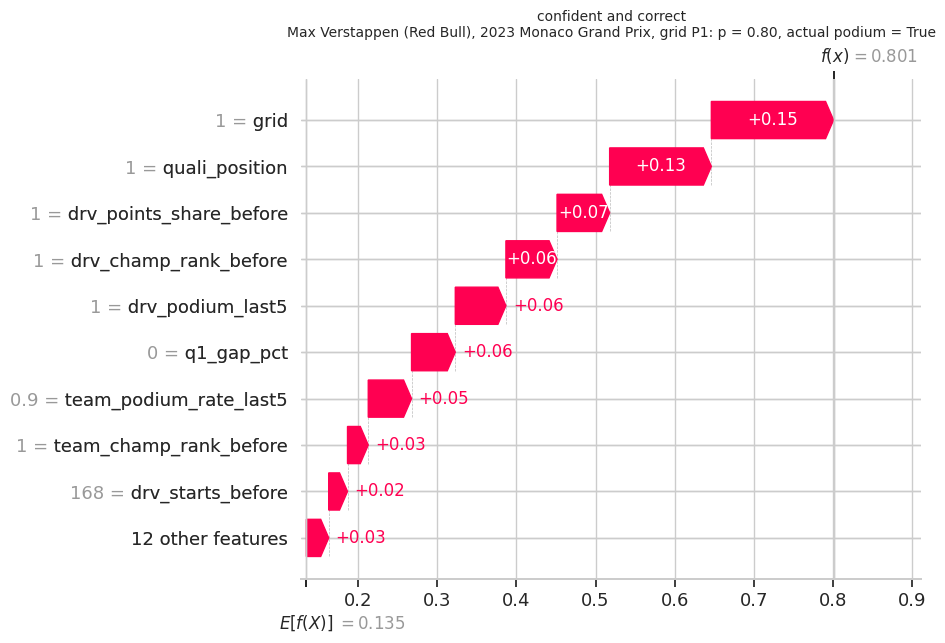

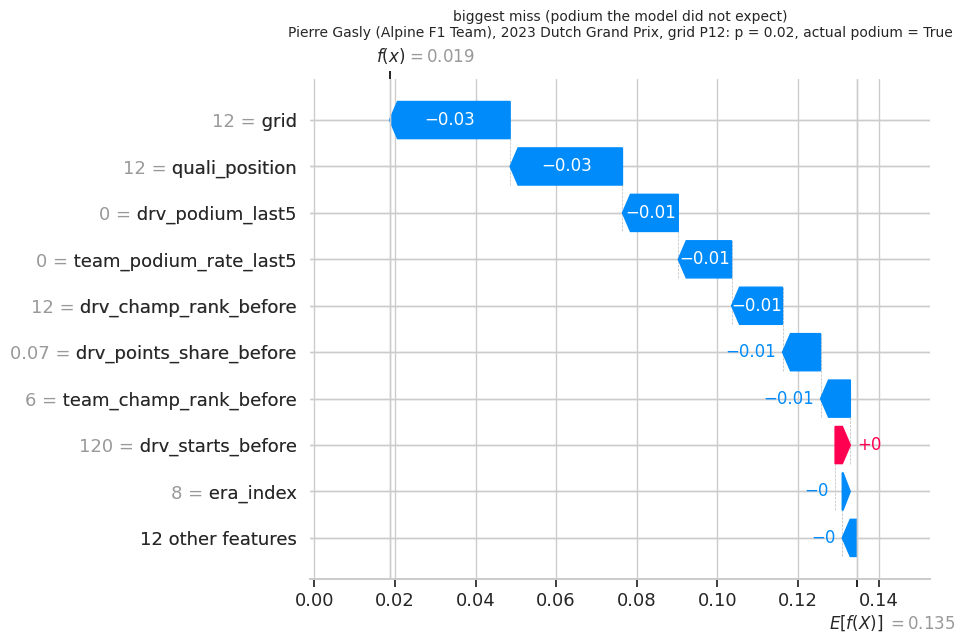

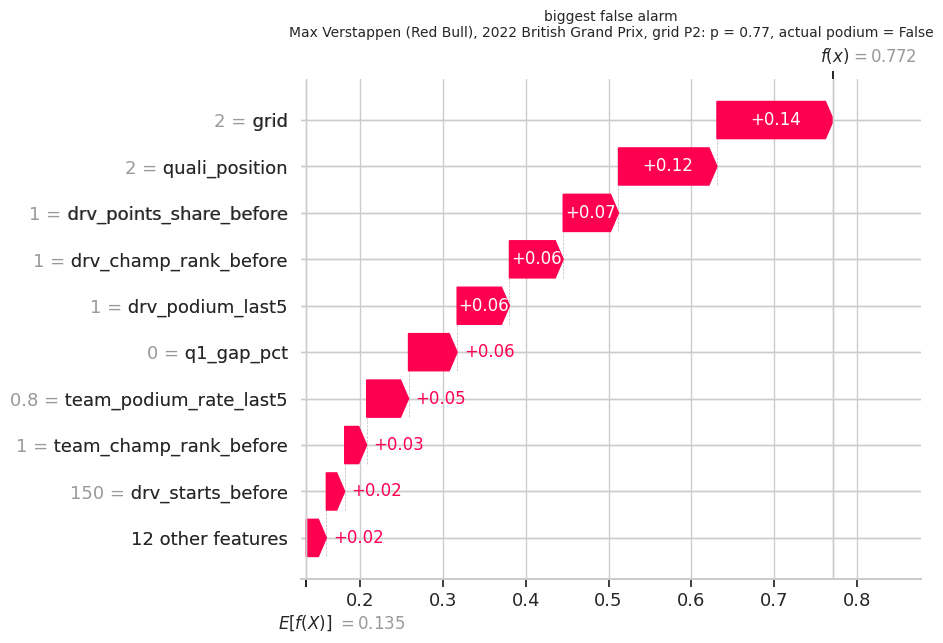

In [269]:
# Local SHAP: start from the average prediction, each bar adds or removes probability, ending at this row's prediction
for case, i in examples.items():
    plt.figure()
    shap.plots.waterfall(shap_exp[i], max_display=10, show=False)
    plt.title(f'{case}\n{names.loc[i, "label"]}: p = {p_best[i]:.2f}, actual podium = {bool(Y["test"][i])}', fontsize=10)
    plt.show()

> **Reading the waterfalls** (each starts at the average prediction, about 0.13, and every bar adds or removes probability):
> - **Confident and correct:** a front-row start, a front-row qualifying position, leading the championship and recent podiums all add up. Every piece of pre-race evidence points the same way.
> - **Biggest miss:** a midfield start (around P12), no recent podiums and a midfield team. Every feature pushes down, so the model gives about 2%. The driver finished on the podium anyway. A podium from midfield usually comes from what happens **during** the race (weather, crashes, safety cars, strategy), which no pre-race feature can contain. This is a limit of the prediction cutoff, not a bug.
> - **Biggest false alarm:** the explanation looks just like the correct case: a front-row start and a championship leader. The model was right to be confident on the information it had. What went wrong happened in the race. The status column shows the driver finished, but outside the top 3, so he lost places during the race rather than retiring.
> - **The lesson for the report:** the model's mistakes are mostly races decided by in-race events. Its explanations for them are still sensible.

### 15.4 LIME (local)

LIME builds its explanation in a completely different way from SHAP: it perturbs the row thousands of times and fits a small linear model around it. If both methods agree on what drove a prediction, the explanation can be trusted more.

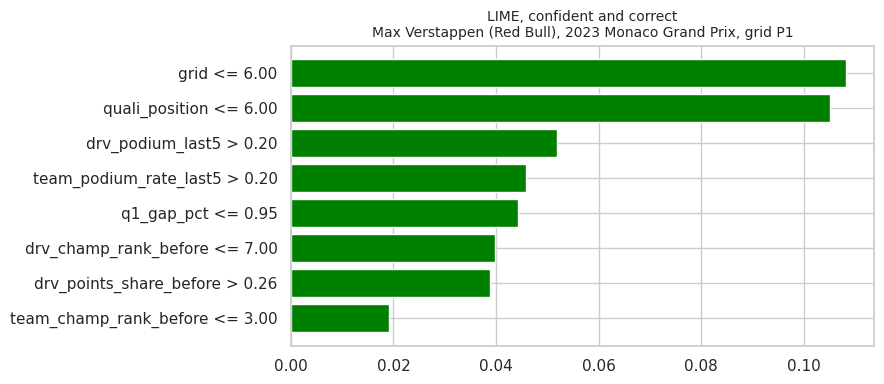

top-5 features by |SHAP| for the same row: ['grid', 'quali_position', 'drv_points_share_before', 'drv_champ_rank_before', 'drv_podium_last5']


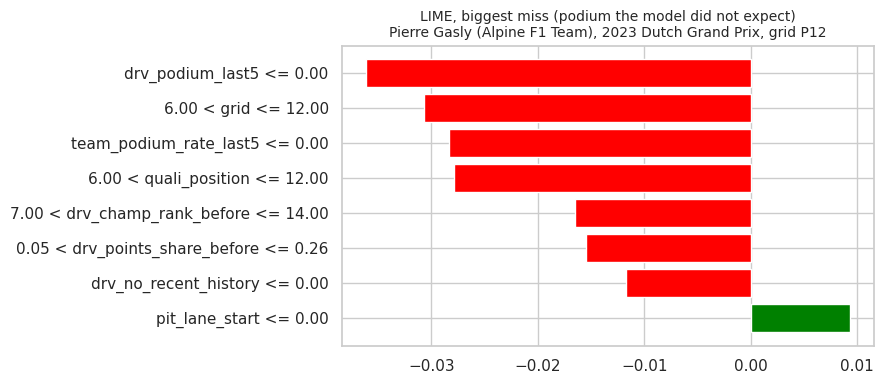

top-5 features by |SHAP| for the same row: ['grid', 'quali_position', 'drv_podium_last5', 'team_podium_rate_last5', 'drv_champ_rank_before']


condition  \
case                                                                                       
confident and correct                          0                            grid <= 6.00   
                                               1                  quali_position <= 6.00   
                                               2                 drv_podium_last5 > 0.20   
                                               3           team_podium_rate_last5 > 0.20   
                                               4                      q1_gap_pct <= 0.95   
                                               5           drv_champ_rank_before <= 7.00   
                                               6          drv_points_share_before > 0.26   
                                               7          team_champ_rank_before <= 3.00   
biggest miss (podium the model did not expect) 0                drv_podium_last5 <= 0.00   
                                               1                    6.00 < grid <= 12.00   
                                               2          team_podium_rate_last5 <= 0.00   
                                               3          6.00 < quali_position <= 12.00   
                                               4   7.00 < drv_champ_rank_before <= 14.00   
                                               5  0.05 < drv_points_share_before <= 0.26   
                                               6           drv_no_recent_history <= 0.00   
                                               7                  pit_lane_start <= 0.00   

                                                  LIME weight  
case                                                           
confident and correct                          0        0.108  
                                               1        0.105  
                                               2        0.052  
                                               3        0.046  
                                               4        0.044  
                                               5        0.040  
                                               6        0.039  
                                               7        0.019  
biggest miss (podium the model did not expect) 0       -0.036  
                                               1       -0.031  
                                               2       -0.028  
                                               3       -0.028  
                                               4       -0.017  
                                               5       -0.015  
                                               6       -0.012  
                                               7        0.009

In [270]:
# LIME: perturbs the row many times, asks the model for each perturbed copy, and fits a small weighted linear
# model around this one row. Its weights are a second, independent local explanation to compare with SHAP.
if LimeTabularExplainer is None:
    print('lime could not be installed here; the local SHAP explanations above cover the local-explanation requirement.')
else:
    imp_train = BEST_MODEL.named_steps['impute_gap'].transform(XM['train'])     # LIME needs data without gaps
    lime_explainer = LimeTabularExplainer(imp_train.to_numpy(), feature_names=list(imp_train.columns),
                                          class_names=['no podium', 'podium'], mode='classification',
                                          discretize_continuous=True, random_state=SEED)
    predict_fn = lambda a: BEST_MODEL.predict_proba(pd.DataFrame(a, columns=imp_train.columns))
    lime_tables = {}
    for case, i in list(examples.items())[:2]:
        exp_l = lime_explainer.explain_instance(raw_test.iloc[i].to_numpy(), predict_fn, num_features=8, num_samples=3000)
        fig = exp_l.as_pyplot_figure(label=1)
        fig.set_size_inches(9, 4)
        plt.title(f'LIME, {case}\n{names.loc[i, "label"]}', fontsize=10); plt.tight_layout(); plt.show()
        lime_tables[case] = pd.DataFrame(exp_l.as_list(label=1), columns=['condition', 'LIME weight'])
        shap_top = pd.Series(sv[i], index=raw_test.columns).abs().sort_values(ascending=False).head(5).index.tolist()
        print('top-5 features by |SHAP| for the same row:', shap_top)
    display(pd.concat(lime_tables, names=['case']).round(3))

> **Reading:** for both rows, LIME and SHAP name the same leading features: grid and qualifying position first, then recent driver form, team form and standings. LIME expresses them as conditions ("grid ≤ 6", "no podium in the last 5 races"). Two methods built on different principles agree, so the explanation describes the model's behaviour reliably. Again, it describes what the model **uses**, not what **causes** a podium.

## 16. Inference function

`predict_podium(record)` takes one pre-race record and returns the podium probability, the yes/no prediction at the threshold chosen on validation, and the list of every value it had to fill in.

**Design rules:**
- **Only pre-race fields are accepted.** A post-race field (e.g. `pit_stops`) is refused, so leakage at prediction time is impossible.
- **`grid` is required.** Without a starting position there is nothing to predict, which is the same reasoning as D3.
- **Missing values are filled with the same rules used to build the training table:**
  - no qualifying → copy the grid and set `has_quali` = 0 (D7);
  - no gap → filled by the pipeline from qualifying position (13.3);
  - no standing → last place with `no_standing_yet` = 1 (D10);
  - no form → 0 with the matching "no history" flag.

  The model never receives a combination it was not trained on.
- **Values outside the valid range are refused** (a share above 1, a grid slot of 0).
- **Every filled value is reported,** so the user knows how much of the prediction rests on defaults.

In [271]:
# Inference: one pre-race record in, a podium probability out. A record is a dict of the feature values known
# after qualifying. Missing values are filled with EXACTLY the rules used to build the training table (section 10),
# so the model never sees a combination it was not trained on.
FIELD_DEFAULT = 20           # typical modern field when field_size is not given
TEAMS_DEFAULT = 10

def predict_podium(record, model=None, threshold=None, verbose=True):
    model = BEST_MODEL if model is None else model
    threshold = BEST_THRESHOLD if threshold is None else threshold
    r = dict(record)
    unknown = set(r) - set(MODEL_FEATURES) - {'year', 'round', 'driver', 'race'}
    if unknown:
        raise ValueError(f'unknown fields: {sorted(unknown)}')
    if r.get('grid') is None:
        raise ValueError('grid is required: without a starting position there is nothing to predict (D3)')
    filled = []
    def fill(key, value, why, report=True):
        # flags that are only derived from other fields are filled silently (report=False)
        if r.get(key) is None or (isinstance(r.get(key), float) and np.isnan(r[key])):
            r[key] = value
            if report:
                filled.append(f'{key} = {value} ({why})')

    fill('pit_lane_start', 0, 'assumed a normal grid start')
    fill('field_size', FIELD_DEFAULT, 'typical modern field')
    if r.get('quali_position') is None:                      # D7: no qualifying -> copy grid, flag it, no penalty
        fill('quali_position', r['grid'], 'no qualifying: copied from grid (D7)')
        r['has_quali'] = 0; r['grid_penalty'] = 0
    fill('has_quali', 1, 'qualifying position given', report=False)
    fill('grid_penalty', max(0, r['grid'] - r['quali_position']) if r['has_quali'] else 0, 'grid - qualifying position', report=False)
    if r.get(GAP_COL) is None:
        r[GAP_COL] = np.nan
        filled.append(f'{GAP_COL} = filled by the pipeline from qualifying position (13.3)')
    if r.get('drv_champ_rank_before') is None:              # D10: no standing yet
        fill('drv_champ_rank_before', r['field_size'], 'no standing yet: last place (D10)')
        fill('drv_points_share_before', 0.0, 'no standing yet (D10)')
        r['no_standing_yet'] = 1
    fill('drv_points_share_before', 0.0, 'not given')
    fill('no_standing_yet', 0, 'standing given', report=False)
    if r.get('drv_podium_last5') is None:
        fill('drv_podium_last5', 0.0, 'no recent races')
        r['drv_no_recent_history'] = 1
    fill('drv_no_recent_history', 0, 'form given', report=False)
    fill('drv_starts_before', 0, 'unknown experience: treated as a debut')
    if r.get('teammate_gap_last5') is None:
        fill('teammate_gap_last5', 0.0, 'no 2-car-team race in the window')
        r['teammate_gap_missing'] = 1
    fill('teammate_gap_missing', 0, 'teammate gap given', report=False)
    fill('team_champ_rank_before', TEAMS_DEFAULT, 'no team standing: last place')
    if r.get('team_podium_rate_last5') is None and r.get('team_mech_dnf_rate_last5') is None:
        r['team_no_recent_history'] = 1
    fill('team_podium_rate_last5', 0.0, 'no recent team races')
    fill('team_mech_dnf_rate_last5', 0.0, 'no recent team races')
    fill('team_no_recent_history', 0, 'team form given', report=False)
    fill('is_season_opener', int(r.get('round') == 1) if r.get('round') is not None else 0, 'from round', report=False)
    fill('era_index', ERA_TO_INDEX[era_of(r['year'])] if r.get('year') is not None else len(ERA_ORDER) - 2,
         'from year (default: the latest era in the data)')

    # validity checks: the same ranges the training data had
    if not (1 <= r['grid'] <= 40):
        raise ValueError('grid must be between 1 and 40')
    for k in ['drv_podium_last5', 'drv_points_share_before', 'team_podium_rate_last5', 'team_mech_dnf_rate_last5']:
        if not (0 <= r[k] <= 1):
            raise ValueError(f'{k} must be a share between 0 and 1')

    X = pd.DataFrame([{c: r[c] for c in MODEL_FEATURES}]).astype(float)
    p = float(model.predict_proba(X)[:, 1][0])
    out = {'podium probability': round(p, 3), 'predicted podium': p >= threshold,
           'threshold (from validation)': round(threshold, 3), 'filled fields': filled}
    if verbose:
        print(f"{record.get('driver', 'driver')} at {record.get('race', 'race')}: p = {p:.3f} -> "
              f"{'PODIUM' if p >= threshold else 'no podium'} (threshold {threshold:.3f})")
        for f_ in filled:
            print('   filled:', f_)
    return out

### 16.1 Demonstration: a complete record and a partially-missing record

The complete record is a real row from the test set, so its prediction can be checked against the model directly (the cell asserts they are identical). The partial record is the **same driver and race** with the qualifying data, championship standings and driver form removed.

In [272]:
# Demo 1: a complete record from the test set (the pole sitter of round 10 of 2024), so the prediction can be checked
i_demo = D['test'][(D['test']['year'] == 2024) & (D['test']['round'] == 10)].sort_values('grid').index[0]
row = D['test'].loc[i_demo]
complete = {c: (None if pd.isna(row[c]) else float(row[c])) for c in MODEL_FEATURES}
complete.update(year=int(row['year']), round=int(row['round']), driver=names.loc[i_demo, 'label'].split(',')[0],
                race=f"{int(row['year'])} {names.loc[i_demo, 'race']}")
res_complete = predict_podium(complete)
direct = BEST_MODEL.predict_proba(XM['test'].loc[[i_demo]])[:, 1][0]
print(f'   check: same as the model on the test row: {direct:.3f}; actual result: P{int(row["positionOrder"])}')
assert abs(res_complete['podium probability'] - round(direct, 3)) < 1e-9

Lando Norris (McLaren) at 2024 Spanish Grand Prix: p = 0.651 -> PODIUM (threshold 0.402)
   check: same as the model on the test row: 0.651; actual result: P2


In [273]:
# Demo 2: the same driver and race with information missing: no qualifying time, no standings, no recent form.
# This is what a record looks like for a newcomer, or for a race where only the grid is known.
partial = {k: complete[k] for k in ['grid', 'field_size', 'year', 'round', 'driver', 'race',
                                    'team_champ_rank_before', 'team_podium_rate_last5', 'team_mech_dnf_rate_last5']}
partial['driver'] += ' (partial record)'
res_partial = predict_podium(partial)

pd.DataFrame({'complete record': res_complete, 'partial record': res_partial}).T[
    ['podium probability', 'predicted podium', 'threshold (from validation)']]

Lando Norris (McLaren) (partial record) at 2024 Spanish Grand Prix: p = 0.522 -> PODIUM (threshold 0.402)
   filled: pit_lane_start = 0 (assumed a normal grid start)
   filled: quali_position = 1.0 (no qualifying: copied from grid (D7))
   filled: q1_gap_pct = filled by the pipeline from qualifying position (13.3)
   filled: drv_champ_rank_before = 20.0 (no standing yet: last place (D10))
   filled: drv_points_share_before = 0.0 (no standing yet (D10))
   filled: drv_podium_last5 = 0.0 (no recent races)
   filled: drv_starts_before = 0 (unknown experience: treated as a debut)
   filled: teammate_gap_last5 = 0.0 (no 2-car-team race in the window)
   filled: era_index = 8 (from year (default: the latest era in the data))


,podium probability,predicted podium,threshold (from validation)
complete record,0.651,True,0.402
partial record,0.522,True,0.402


> **Reading:**
> - The complete record gives exactly the model's probability for that test row. The function and the trained pipeline are the same thing.
> - With information missing, the function still answers, and it lists every value it filled. The probability moves towards a more cautious value: the defaults (no standing, no recent form) describe a driver with no track record, so the model has less evidence of speed than it had with the full record. That is the behaviour we want. Missing information should not be invented as good news.